# Stratified contextual responsiveness: up to 300 queries per cell type and slice

Same eight sections and milestone-50 model as the 150-query analysis; no refitting. Queries cross **three true encoded malignant-neighbor groups (0, 1–2, 3–5 of five different-type tokens)** with **low/medium/high breast cancer-marker burden**, whose quantiles are determined separately for each cell type within each slice. Burden is the raw 32-gene panel sum divided by all measured query transcripts. Equal burden values remain together, so duplicate quantile cuts may leave fewer burden strata.

Queries are sampled without replacement with balanced allocation across available joint strata, capped at 300 per type/slice. Unfillable query quota can move to other available query strata, never duplicating cells. Context donors are sampled independently from the full eligible same-type pool: **up to five distinct donors per exact malignant count 0–5**. Missing context quota is **never** filled from another count. Distinct donors with identical encoded token sequences are retained. Every query of a type/slice receives the same selected donor panel; its original prediction fills its own donor position if applicable. Original and unchanged controls remain available.

Query and context strata, marker burden, cutpoints, eligibility counts, sampled donor IDs, and ordered neighbor IDs are saved with the prepared/predicted data and CSV manifests. Queries exclude the malignant class because its different-type context cannot contain malignant tokens. All breast cancer-marker analyses use the 32-gene panel. The analyses below follow the 150-query notebook format, including support masks for undersupplied context levels. These are descriptive results from deliberately stratified sampling, not prevalence-weighted estimates of the entire tissue.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.insert(0, '/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748')
from all_types_panel import FAMILIES, MARKERS, EXAMPLES
RUN = Path('/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748')
# One marker definition for every breast cancer-marker analysis below.
BREAST_CANCER_MARKERS = json.loads((RUN / "requested_marker_genes_20261019.json").read_text())
MARKERS = {**MARKERS, "Malignant": list(BREAST_CANCER_MARKERS)}
MARKER_REFRESH = RUN
SUMMARY = MARKER_REFRESH / "summaries_logits"
BREAST_MARKER_FIGURES = RUN / "figures_stratified_markers32"
DONOR_FRACTION_X_MODE = "delta"  # donor fraction minus the query’s true five-neighbor fraction
MIN_QUERIES_PER_DONOR_BIN = 5
FIGURES = BREAST_MARKER_FIGURES
FIGURES.mkdir(exist_ok=True)
MIN_SUPPORTED_QUERIES_PER_SLICE = 10
MIN_SLICES_PER_HEATMAP_TILE = 3
TYPE_ORDER = [t for family in FAMILIES.values() for t in family if t != 'malignant cell']

# Choose exactly three distinct query types, in left-to-right column order.
# Each selected type appears in both rows of every paired six-panel figure.
AVAILABLE_PANEL_QUERY_TYPES = [
    "T cells (pooled)", "natural killer cell", "plasma cell",
    "classical monocyte", "macrophage", "mast cell", "plasmacytoid dendritic cell",
    "capillary endothelial cell", "fibroblast of breast", "fibroblast of lung",
    "pericyte", "smooth muscle cell",
]
PANEL_QUERY_TYPES = [
    "macrophage",
    "T cells (pooled)",
    "plasma cell",
]

FAMILY_COLORS = dict(zip(FAMILIES, ['#4385b5','#c85252','#58a36a','#9463b8']))
SLICE_ORDER = [e['slice'] for e in json.loads((RUN / 'design.json').read_text())['slices']]
SLICE_LABELS = {e['slice']:e['label'] for e in json.loads((RUN/'design.json').read_text())['slices']}
SLICE_PALETTE = dict(zip(SLICE_ORDER, sns.color_palette('colorblind', len(SLICE_ORDER))))
# Related B1 sections share a blue hue, with a distinct shade per replicate.
B1_REPLICATE_COLORS = {'B1_1': '#9ecae1', 'B1_2': '#4292c6', 'B1_3': '#08519c'}
SLICE_PALETTE.update({s: B1_REPLICATE_COLORS[SLICE_LABELS[s]]
                      for s in SLICE_ORDER if SLICE_LABELS[s] in B1_REPLICATE_COLORS})
sns.set_theme(style='white', context='paper')
design = json.loads((RUN/'design.json').read_text())
print({k:design[k] for k in ['n_queries','n_contexts','milestone','query_sampling','expected_n_queries']})
print('Selected sections:', [e['label'] for e in design['slices']])

# Display the central 90% of query sensitivities; statistics use all queries.
PANEL_AXIS_QUANTILES = (0.05, 0.95)
SENSITIVITY_Y_QUANTILES = PANEL_AXIS_QUANTILES

def set_sensitivity_display_range(ax, values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return
    lower, upper = np.quantile(values, SENSITIVITY_Y_QUANTILES)
    if ax.get_yscale() == "log" and lower <= 0:
        positive = values[values > 0]
        if not len(positive):
            return
        lower = positive.min()
    if upper <= lower:
        padding = max(abs(lower) * 0.01, 1e-6)
        lower, upper = max(lower - padding, np.finfo(float).tiny), upper + padding
    ax.set_ylim(lower, upper)

# Population bins use pooled supported queries within each cell type.
# All sections share these boundaries; identical x values are never split.
EXPOSURE_POPULATION_BINS = 6
population_bin_coverage = {}

def population_exposure_bins(frame, value_col):
    result = pd.Series(index=frame.index, dtype=object)
    audits = []
    for query_group, group in frame.groupby("query_group", observed=True, sort=False):
        values = group.loc[np.isfinite(group[value_col]), value_col]
        if values.empty:
            continue
        bins = pd.qcut(values, q=EXPOSURE_POPULATION_BINS, duplicates="drop")
        if bins.isna().all():
            # One shared bin for a constant exposure; preserve every tied query.
            value = float(values.iloc[0])
            epsilon = max(abs(value) * 1e-6, 1e-9)
            result.loc[values.index] = pd.Interval(value - epsilon, value + epsilon, closed="right")
        else:
            result.loc[values.index] = bins.astype(object)
        audit = pd.DataFrame({"exposure_bin": result.loc[values.index], "x": values})
        for interval, members in audit.groupby("exposure_bin", observed=True):
            audits.append(dict(query_group=query_group, exposure=value_col,
                exposure_bin=str(interval), n_queries=len(members),
                observed_min=members.x.min(), observed_max=members.x.max(),
                median_x=members.x.median(), requested_bins=EXPOSURE_POPULATION_BINS))
    population_bin_coverage[value_col] = pd.DataFrame(audits)
    return result

def set_shared_exposure_display_range(ax, cells, x_col):
    values = cells.loc[cells.query_group.isin(PANEL_QUERY_TYPES), x_col].to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return
    lower, upper = np.quantile(values, PANEL_AXIS_QUANTILES)
    if upper <= lower:
        padding = max(abs(lower) * 0.01, 1e-6)
        lower, upper = lower - padding, upper + padding
    ax.set_xlim(lower, upper)


{'n_queries': 300, 'n_contexts': 30, 'milestone': 50, 'query_sampling': 'balanced allocation across available joint neighbor/burden strata without replacement, up to 300; redistribute exhausted query quota across available strata', 'expected_n_queries': 33567}
Selected sections: ['B1_1', 'B1_2', 'B1_3', 'B5', 'B12', 'B10', 'B17', 'B9']


## Sampling strata and realized coverage

Counts below document the actual sampled queries and context donors, including empty malignant-token levels. Burden cutpoints are specific to each cell type and slice.


In [2]:
query_sampling_manifest = pd.concat([pd.read_csv(RUN / "contexts" / f"{e['slice']}_queries.csv") for e in design['slices']], ignore_index=True)
context_sampling_manifest = pd.concat([pd.read_csv(RUN / "contexts" / f"{e['slice']}_context_donors.csv") for e in design['slices']], ignore_index=True)
strata_coverage = pd.concat([pd.read_csv(RUN / "contexts" / f"{e['slice']}_strata.csv") for e in design['slices']], ignore_index=True)
burden_cutpoints = pd.concat([pd.read_csv(RUN / "contexts" / f"{e['slice']}_burden_cutpoints.csv") for e in design['slices']], ignore_index=True)
display(query_sampling_manifest.groupby(['slice','query_cell_type']).size().rename('n_sampled_queries').unstack())
display(strata_coverage.loc[strata_coverage.context_malignant_token_count.notna(), ['slice','cell_type','context_malignant_token_count','n_contexts_available','n_contexts_selected']])
display(burden_cutpoints)
query_sampling_manifest.to_csv(FIGURES/'sampled_query_strata.csv',index=False)
context_sampling_manifest.to_csv(FIGURES/'sampled_context_strata.csv',index=False)


query_cell_type,"CD4-positive, alpha-beta memory T cell",capillary endothelial cell,classical monocyte,cytotoxic T cell,fibroblast of breast,fibroblast of lung,macrophage,mast cell,natural T-regulatory cell,natural killer cell,pericyte,plasma cell,plasmacytoid dendritic cell,smooth muscle cell
slice,,,,,,,,,,,,,,
GSM9509156_breast_breast_B17_B17_rctd_annotated,300,300,300,300,300,300,300,300,300,267,300,300,300,300
GSM9509162_breast_breast_B12_B12_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300
GSM9509164_breast_breast_B10_B10_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300
GSM9509166_breast_breast_B9_B9_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300
GSM9509171_breast_breast_B5_B5_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300
GSM9509172_breast_breast_B1_B1_1_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300
GSM9509173_breast_breast_B1_B1_2_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300
GSM9509174_breast_breast_B1_B1_3_rctd_annotated,300,300,300,300,300,300,300,300,300,300,300,300,300,300


,slice,cell_type,context_malignant_token_count,n_contexts_available,n_contexts_selected
9,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",0.0,1669.0,5.0
10,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",1.0,173.0,5.0
11,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",2.0,74.0,5.0
12,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",3.0,34.0,5.0
13,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",4.0,19.0,5.0
...,...,...,...,...,...
1675,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,1.0,552.0,5.0
1676,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,2.0,562.0,5.0
1677,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,3.0,521.0,5.0
1678,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,4.0,368.0,5.0


,slice,cell_type,population,n_eligible,burden_quantile_edges_json,n_effective_burden_strata,marker_genes_json
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",eligible cells of this type in this slice,1975,"[0.0, 0.07526881992816925, 0.11333333700895307...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,capillary endothelial cell,eligible cells of this type in this slice,7315,"[0.0, 0.13432836532592773, 0.17560975253581992...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,classical monocyte,eligible cells of this type in this slice,6777,"[0.0, 0.09433962404727936, 0.13333334028720856...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,eligible cells of this type in this slice,6203,"[0.0, 0.07500000298023224, 0.1121355593204498,...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,fibroblast of breast,eligible cells of this type in this slice,7782,"[0.0, 0.11538461595773697, 0.16434068481127415...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
...,...,...,...,...,...,...,...
107,GSM9509166_breast_breast_B9_B9_rctd_annotated,natural killer cell,eligible cells of this type in this slice,1867,"[0.0, 0.0990099012851715, 0.15500000119209287,...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
108,GSM9509166_breast_breast_B9_B9_rctd_annotated,pericyte,eligible cells of this type in this slice,1222,"[0.0, 0.16455696523189545, 0.2238806039094925,...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
109,GSM9509166_breast_breast_B9_B9_rctd_annotated,plasma cell,eligible cells of this type in this slice,8230,"[0.0, 0.08275862038135529, 0.1304347813129425,...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."
110,GSM9509166_breast_breast_B9_B9_rctd_annotated,plasmacytoid dendritic cell,eligible cells of this type in this slice,1804,"[0.0, 0.10691823810338974, 0.1568627506494522,...",3,"[""ABCC11"", ""APOBEC3B"", ""AR"", ""CAV1"", ""CCND1"", ..."


## Load completed predictions and audit support

The summary job runs after all selected prediction jobs finish. Unsupported combinations remain missing. Missing cell types may reflect absence or the eligibility criteria, rather than no responsiveness.

In [3]:
if not (SUMMARY / 'complete.json').exists():
    raise FileNotFoundError(f'Summaries not complete yet: {RUN / "jobs.json"}')
scale_metadata = json.loads((SUMMARY / 'complete.json').read_text())
if scale_metadata.get('response_scale') != 'logit':
    raise ValueError('Expected logit-scale summaries')
display(pd.read_csv(SUMMARY / 'response_scale_audit.csv'))
responses = pd.read_csv(SUMMARY / 'slice_responses.csv')
slopes = pd.read_csv(SUMMARY / 'slice_family_slopes.csv')
support = pd.read_csv(SUMMARY / 'support.csv')
DELTA_CONTEXT = MARKER_REFRESH / 'summaries_delta_context'
if not (DELTA_CONTEXT/'complete.json').exists():
    raise FileNotFoundError(f'Missing original-context composition table: {DELTA_CONTEXT}')
examples = pd.read_csv(DELTA_CONTEXT / 'logit_examples.csv.gz')
marker_support = pd.read_csv(SUMMARY / 'marker_support.csv')
coverage = pd.concat([pd.read_csv(p) for p in sorted((RUN/'contexts').glob('*_coverage.csv'))], ignore_index=True)
display(coverage)
display(marker_support)
display(support.groupby(['query_cell_type','neighbor_family','status']).n_queries.sum().unstack('status',fill_value=0))


,slice,response_scale,n_values,n_values_clipped
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,logit,37203870,30221477
1,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,logit,37203593,31045352
2,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,logit,37034346,30634281
3,GSM9509171_breast_breast_B5_B5_rctd_annotated,logit,37212734,30774300
4,GSM9509162_breast_breast_B12_B12_rctd_annotated,logit,37109690,31523687
5,GSM9509164_breast_breast_B10_B10_rctd_annotated,logit,36853188,30748755
6,GSM9509156_breast_breast_B17_B17_rctd_annotated,logit,36478130,31654730
7,GSM9509166_breast_breast_B9_B9_rctd_annotated,logit,37212180,29514040


,slice,cell_type,n_eligible,n_queries,n_contexts,status,n_query_strata,n_unique_encoded_sequences
0,GSM9509156_breast_breast_B17_B17_rctd_annotated,"CD4-positive, alpha-beta memory T cell",506,300,28,ok,9,26
1,GSM9509156_breast_breast_B17_B17_rctd_annotated,capillary endothelial cell,2525,300,30,ok,9,25
2,GSM9509156_breast_breast_B17_B17_rctd_annotated,classical monocyte,5773,300,30,ok,9,26
3,GSM9509156_breast_breast_B17_B17_rctd_annotated,cytotoxic T cell,1503,300,30,ok,9,26
4,GSM9509156_breast_breast_B17_B17_rctd_annotated,fibroblast of breast,4003,300,30,ok,9,24
...,...,...,...,...,...,...,...,...
107,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,natural killer cell,998,300,30,ok,9,26
108,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,pericyte,2524,300,30,ok,9,26
109,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,plasma cell,8002,300,30,ok,9,26
110,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,plasmacytoid dendritic cell,1380,300,28,ok,9,25


,slice,family,n_panel_markers,markers
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Lymphoid,8,CD247;CD3E;CD79A;GNLY;MS4A1;MZB1;NKG7;TRAC
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Myeloid / innate,3,AIF1;CD68;FCER1G
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Stromal / vascular,4,ACTA2;LUM;PECAM1;VWF
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Malignant,32,ABCC11;APOBEC3B;AR;CAV1;CCND1;CDH1;CEACAM6;CEN...
4,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Lymphoid,8,CD247;CD3E;CD79A;GNLY;MS4A1;MZB1;NKG7;TRAC
5,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Myeloid / innate,3,AIF1;CD68;FCER1G
6,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Stromal / vascular,4,ACTA2;LUM;PECAM1;VWF
7,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Malignant,32,ABCC11;APOBEC3B;AR;CAV1;CCND1;CDH1;CEACAM6;CEN...
8,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,Lymphoid,8,CD247;CD3E;CD79A;GNLY;MS4A1;MZB1;NKG7;TRAC
9,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,Myeloid / innate,3,AIF1;CD68;FCER1G


status                                                     insufficient_context_variation  \
query_cell_type                        neighbor_family                                      
CD4-positive, alpha-beta memory T cell Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
capillary endothelial cell             Lymphoid                                        38   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
classical monocyte                     Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
cytotoxic T cell                       Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
fibroblast of breast                   Lymphoid                                        58   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
fibroblast of lung                     Lymphoid                                        35   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
macrophage                             Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 1   
                                       Stromal / vascular                               0   
mast cell                              Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
natural T-regulatory cell              Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
natural killer cell                    Lymphoid                                         0   
                                       Malignant                                        0   
                                       Myeloid / innate                                 0   
                                       Stromal / vascular                               0   
pericyte                               Lymphoid                                       107   
 

## Overview and unchanged-context control

Left: signed change in predicted admixture logit per +10 percentage points of neighboring-family composition, for that family's predefined markers expressed in a query. Query slopes are summarized by their median within each slice, then by the median across slices. Each tile requires ≥10 supported queries per slice and ≥3 slices. Numbers in brackets show the number of supporting slices. Gray means insufficient support.

Right: mean absolute logit changes over each query's expressed genes, summarized by median within slice. Points are slices and bars are means of slice medians. Swapped contexts and unchanged-context duplicates use the same query cells. Queries are not treated as independent biological replicates; slices may also come from related specimens.


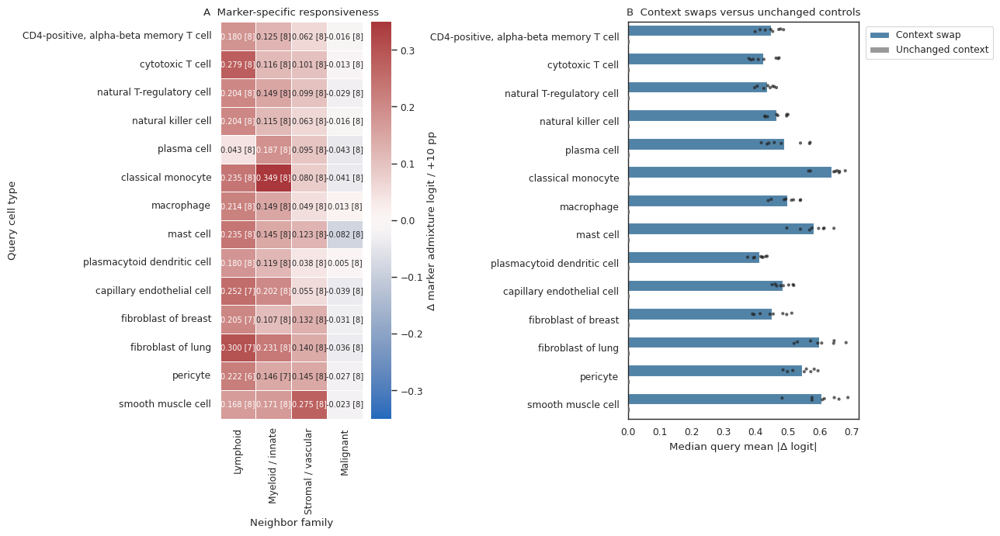

neighbor_family,Lymphoid,Myeloid / innate,Stromal / vascular,Malignant
query_cell_type,,,,
"CD4-positive, alpha-beta memory T cell",8,8,8,8
cytotoxic T cell,8,8,8,8
natural T-regulatory cell,8,8,8,8
natural killer cell,8,8,8,8
plasma cell,8,8,8,8
classical monocyte,8,8,8,8
macrophage,8,8,8,8
mast cell,8,8,8,8
plasmacytoid dendritic cell,8,8,8,8


In [4]:
supported = slopes.loc[slopes.n_queries >= MIN_SUPPORTED_QUERIES_PER_SLICE].copy()
mean_slopes = supported.groupby(['query_cell_type','neighbor_family']).median_slope.median().unstack()
n_slices = supported.groupby(['query_cell_type','neighbor_family'])['slice'].nunique().unstack(fill_value=0)
mean_slopes = mean_slopes.reindex(index=TYPE_ORDER,columns=list(FAMILIES))
n_slices = n_slices.reindex(index=TYPE_ORDER,columns=list(FAMILIES),fill_value=0).fillna(0)
mean_slopes = mean_slopes.mask(n_slices < MIN_SLICES_PER_HEATMAP_TILE)
annotation = mean_slopes.copy().astype(object)
for t in TYPE_ORDER:
    for f in FAMILIES:
        v=mean_slopes.loc[t,f]
        annotation.loc[t,f] = f'{v:.3f} [{int(n_slices.loc[t,f])}]' if pd.notna(v) else ''
fig, axes=plt.subplots(1,2,figsize=(13,7),gridspec_kw={'width_ratios':[1,1.3]})
axes[0].set_facecolor('0.9')
finite=mean_slopes.to_numpy()[np.isfinite(mean_slopes.to_numpy())]
limit=max(float(np.max(np.abs(finite))) if len(finite) else .01,.001)
sns.heatmap(mean_slopes,mask=mean_slopes.isna(),cmap='vlag',center=0,vmin=-limit,vmax=limit,
            annot=annotation,fmt='',annot_kws={'fontsize':7},linewidths=.5,ax=axes[0],
            cbar_kws={'label':'Δ marker admixture logit / +10 pp'})
axes[0].set(xlabel='Neighbor family',ylabel='Query cell type',title='A  Marker-specific responsiveness')
plot_responses=responses.assign(comparison=lambda f:f.comparison.map({'representative':'Context swap','unchanged_control':'Unchanged context'}))
sns.barplot(data=plot_responses,y='query_cell_type',x='median_absolute_delta_logit',hue='comparison',
            order=TYPE_ORDER,hue_order=['Context swap','Unchanged context'],palette=['#4385b5','#999999'],errorbar=None,ax=axes[1])
sns.stripplot(data=plot_responses,y='query_cell_type',x='median_absolute_delta_logit',hue='comparison',
              order=TYPE_ORDER,hue_order=['Context swap','Unchanged context'],dodge=True,palette=['#222222','#666666'],
              size=3,alpha=.7,legend=False,ax=axes[1])
axes[1].set(xlabel='Median query mean |Δ logit|',ylabel='',title='B  Context swaps versus unchanged controls')
axes[1].legend(title='',loc='upper left',bbox_to_anchor=(1.01,1))
fig.tight_layout()
def save_numbered(fig,stem):
    index=1
    while (FIGURES/f'{stem}_{index}.pdf').exists() or (FIGURES/f'{stem}_{index}.png').exists(): index+=1
    fig.savefig(FIGURES/f'{stem}_{index}.pdf',bbox_inches='tight')
    fig.savefig(FIGURES/f'{stem}_{index}.png',dpi=300,bbox_inches='tight')
save_numbered(fig,'all_type_responsiveness')
plt.show()
display(n_slices)


## Predefined examples

Cytotoxic T cells and breast fibroblasts, each versus malignant-family neighbor proportion. Response averages predefined malignant markers expressed in each query. Curves average within each query/composition bin, then across queries within a slice. Lines are individual slices. Sparse or unavailable marker combinations are shown explicitly, rather than replaced with the most responsive examples.

The x-axis is now **substituted minus original malignant-neighbor proportion for each query**, matching the baseline-relative y-axis. Positive x adds malignant context; negative x removes it. A zero change in malignant proportion can still change other neighbor types, so swapped-context curves need not pass through (0, 0). The unchanged-context control remains (0, 0). Within-query slopes are unchanged by subtracting each query’s constant baseline proportion.


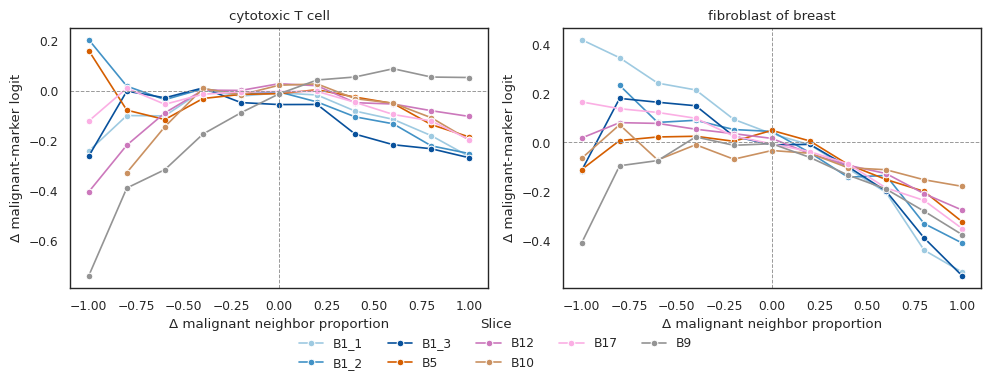

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),squeeze=False)
for ax,(query_type,family) in zip(axes.flat,EXAMPLES):
    subset=examples.loc[examples.query_cell_type.eq(query_type)&examples.neighbor_family.eq(family)].copy()
    if subset.empty:
        ax.text(.5,.5,'No expressed-marker support',ha='center',va='center',transform=ax.transAxes)
    else:
        subset['delta_proportion_bin']=np.rint(subset.delta_neighbor_proportion*5)/5
        by_query=subset.groupby(['slice','query_cell_id','delta_proportion_bin']).delta_marker_logit.mean().reset_index()
        by_slice=by_query.groupby(['slice','delta_proportion_bin']).agg(response=('delta_marker_logit','mean'),n_queries=('query_cell_id','nunique')).reset_index()
        by_slice=by_slice.loc[by_slice.n_queries>=5]
        sns.lineplot(data=by_slice,x='delta_proportion_bin',y='response',hue='slice',marker='o',estimator=None,ax=ax,
                     hue_order=SLICE_ORDER,palette=SLICE_PALETTE,legend=(ax is axes.flat[0]))
    ax.axhline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.axvline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.set(title=query_type,xlabel=f'Δ {family.lower()} neighbor proportion',ylabel='Δ malignant-marker logit')
handles, labels = axes.flat[0].get_legend_handles_labels()
if handles:
    axes.flat[0].get_legend().remove()
    fig.legend(handles, [SLICE_LABELS.get(label,label) for label in labels],
               title='Slice', loc='lower center', ncol=5, bbox_to_anchor=(.5,-.1),frameon=False)
fig.tight_layout()
save_numbered(fig,'predefined_examples_delta_context')
plt.show()


## Reproducibility and interpretation

`design.json` records source files, checkpoint, sampling seed, eligibility rules, and controls. `contexts/*_coverage.csv` records every intended query type, including missing types. Per-query response/slopes and per-slice summaries are retained alongside marker coverage and status tables.

The design has one sampling repeat. This panel demonstrates context sensitivity and checks specificity; it does not establish correction accuracy, physical contamination, or biological identity changes. Use neighbor-token ablations as complementary evidence. Different-type neighbors reflect model training and exclude the query's own exact type, so neighborhood-family support differs among query types. Inference time and GPU memory must be measured from the pilot before making runtime claims.


## Gene-ranking responsiveness

Ranks use the existing **untransformed probabilities**, restricted to the same expressed genes within each query. Higher ranks mean higher predicted contamination. Probability and logit ranks agree except where logit clipping creates ties, so raw probabilities avoid that clipping artifact.

For each context, compare against the same query's original neighborhood: **rank distance = 1 − Spearman ρ** (0 = unchanged; up to 2 for reversed rankings), and top-10%/20% removal-priority overlap. Queries need ≥10 expressed genes. Top sets contain at least three genes; ties at the cutoff receive fractional membership, with overlap defined as sum of the minimum memberships divided by k. Identical tied rankings therefore have overlap 1. Constant-rank vectors have undefined Spearman and are reported rather than assigned 0 distance.

Summaries first average over contexts within query, then take medians within slice. Identical-context controls should have rank distance 0 and overlap 1. Overlap quantifies gene prioritization, not counts removed or biological accuracy.


{'n_slices': 8, 'n_ranked_queries': 33444, 'rank_source': 'raw probabilities, without clipping or logit', 'minimum_expressed_genes': 10, 'top_k_minimum': 3, 'ties': 'average ranks; fractional top-k memberships; overlap=sum(min(weights))/k', 'marker_genes': ['ABCC11', 'APOBEC3B', 'AR', 'CAV1', 'CCND1', 'CDH1', 'CEACAM6', 'CENPF', 'CXCL12', 'EGFR', 'ERBB2', 'ESR1', 'FOXA1', 'GATA3', 'KIT', 'KRT7', 'LDHB', 'LRRC15', 'MDM2', 'PCLAF', 'PGR', 'PTGDS', 'RUNX1', 'S100A4', 'SCD', 'SFRP1', 'SNAI1', 'TACSTD2', 'TCF4', 'TOP2A', 'ZEB1', 'ZEB2']}


comparison         status
representative     ok        33444
unchanged_control  ok        33444
Name: n_queries, dtype: int64

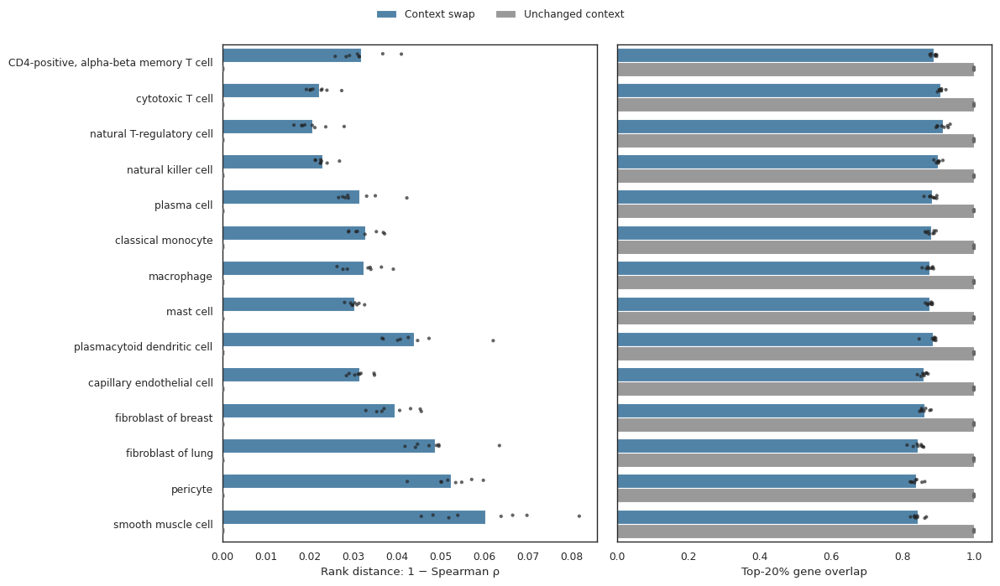

,median_rank_distance,median_top10_overlap,median_top20_overlap
query_cell_type,,,
"CD4-positive, alpha-beta memory T cell",0.031092,0.836111,0.891288
capillary endothelial cell,0.031218,0.800000,0.859838
classical monocyte,0.031748,0.841336,0.879630
cytotoxic T cell,0.021643,0.863333,0.906677
fibroblast of breast,0.038783,0.800926,0.856875
fibroblast of lung,0.048152,0.788333,0.847745
macrophage,0.033567,0.826111,0.875667
mast cell,0.030058,0.844444,0.878889
natural T-regulatory cell,0.019692,0.900000,0.913333


In [6]:
RANK_SUMMARY = MARKER_REFRESH / 'summaries_ranks'
if not (RANK_SUMMARY/'complete.json').exists():
    raise FileNotFoundError(f'Ranking summaries not complete: {RANK_SUMMARY}')
rank_metadata = json.loads((RANK_SUMMARY/'complete.json').read_text())
print(rank_metadata)
rank_slices = pd.read_csv(RANK_SUMMARY/'slice_rank_changes.csv')
rank_markers = pd.read_csv(RANK_SUMMARY/'slice_marker_rank_slopes.csv')
rank_examples = pd.read_csv(DELTA_CONTEXT/'rank_examples.csv.gz')
rank_query_status = pd.read_csv(RANK_SUMMARY/'query_rank_changes.csv.gz')
display(rank_query_status.groupby(['comparison','status']).size().rename('n_queries'))
rank_plot=rank_slices.assign(comparison=lambda f:f.comparison.map({'representative':'Context swap','unchanged_control':'Unchanged context'}))
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
for ax,metric,label in zip(axes,['median_rank_distance','median_top20_overlap'],
                           ['Rank distance: 1 − Spearman ρ','Top-20% gene overlap']):
    sns.barplot(data=rank_plot,y='query_cell_type',x=metric,hue='comparison',order=TYPE_ORDER,
                hue_order=['Context swap','Unchanged context'],palette=['#4385b5','#999999'],errorbar=None,ax=ax)
    sns.stripplot(data=rank_plot,y='query_cell_type',x=metric,hue='comparison',order=TYPE_ORDER,
                  hue_order=['Context swap','Unchanged context'],palette=['#222222','#666666'],
                  dodge=True,alpha=.7,size=3,legend=False,ax=ax)
    ax.set(xlabel=label,ylabel='')
    ax.legend_.remove()
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=2,frameon=False)
fig.tight_layout(rect=[0,0,1,.95])
save_numbered(fig,'ranking_responsiveness')
plt.show()
display(rank_slices.loc[rank_slices.comparison.eq('representative')].groupby('query_cell_type')[
    ['median_rank_distance','median_top10_overlap','median_top20_overlap']].median())


## Do neighboring-family markers rise in rank?

Slopes compare each query's mean marker-rank percentile across its substituted contexts. Percentile is (average rank − 1)/(number of expressed genes − 1), so positive slopes mean markers move toward the genes prioritized for removal. Only expressed predefined markers enter each query's comparison. The same ≥10-query/≥3-slice support rule is used as above. These marginal composition associations do not isolate the effect of replacing a single neighbor token.


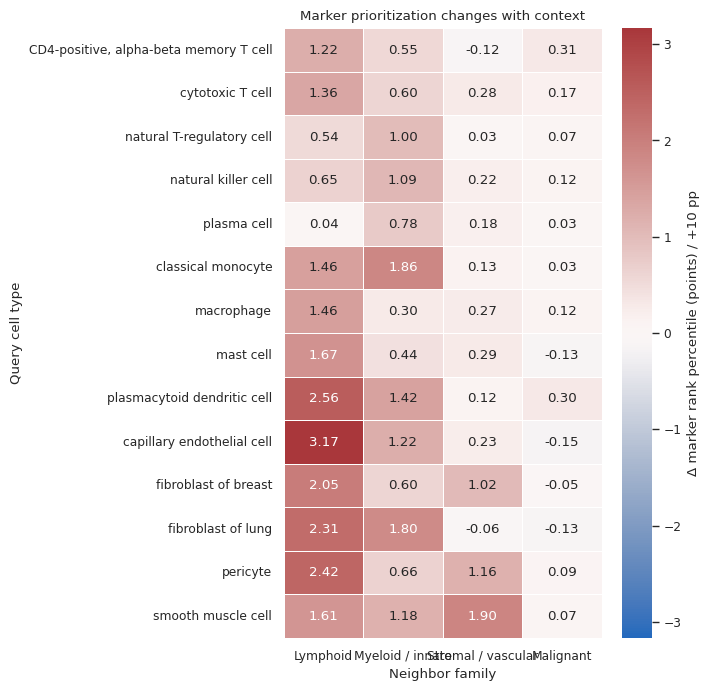

neighbor_family,Lymphoid,Myeloid / innate,Stromal / vascular,Malignant
query_cell_type,,,,
"CD4-positive, alpha-beta memory T cell",8,8,8,8
cytotoxic T cell,8,8,8,8
natural T-regulatory cell,8,8,8,8
natural killer cell,8,8,8,8
plasma cell,8,8,8,8
classical monocyte,8,8,8,8
macrophage,8,8,8,8
mast cell,8,8,8,8
plasmacytoid dendritic cell,8,8,8,8


,n_slices,median_rank_slope,n_positive_slices,n_negative_slices
query_cell_type,,,,
"CD4-positive, alpha-beta memory T cell",8,0.003094,8,0
capillary endothelial cell,8,-0.001503,0,8
classical monocyte,8,0.000335,4,4
cytotoxic T cell,8,0.001709,8,0
fibroblast of breast,8,-0.000462,0,8
fibroblast of lung,8,-0.001322,2,6
macrophage,8,0.001201,6,2
mast cell,8,-0.001281,1,7
natural T-regulatory cell,8,0.000737,6,2


In [7]:
supported_ranks=rank_markers.loc[rank_markers.n_queries>=MIN_SUPPORTED_QUERIES_PER_SLICE]
rank_heatmap=supported_ranks.groupby(['query_cell_type','neighbor_family']).median_rank_slope.median().unstack()
rank_support=supported_ranks.groupby(['query_cell_type','neighbor_family'])['slice'].nunique().unstack(fill_value=0)
rank_heatmap=rank_heatmap.reindex(index=TYPE_ORDER,columns=list(FAMILIES))
rank_support=rank_support.reindex(index=TYPE_ORDER,columns=list(FAMILIES),fill_value=0).fillna(0)
rank_heatmap=rank_heatmap.mask(rank_support<MIN_SLICES_PER_HEATMAP_TILE)
fig,ax=plt.subplots(figsize=(7,7));ax.set_facecolor('0.9')
finite=rank_heatmap.to_numpy()[np.isfinite(rank_heatmap.to_numpy())]
limit=max(float(np.max(np.abs(finite))) if len(finite) else .01,.001)
sns.heatmap(100*rank_heatmap,mask=rank_heatmap.isna(),cmap='vlag',center=0,vmin=-100*limit,vmax=100*limit,
            annot=True,fmt='.2f',linewidths=.5,ax=ax,cbar_kws={'label':'Δ marker rank percentile (points) / +10 pp'})
ax.set(xlabel='Neighbor family',ylabel='Query cell type',title='Marker prioritization changes with context')
fig.tight_layout();save_numbered(fig,'marker_rank_responsiveness');plt.show()
display(rank_support)
malignant_rank_summary = supported_ranks.loc[supported_ranks.neighbor_family.eq('Malignant')].groupby('query_cell_type').agg(
    n_slices=('slice','nunique'),median_rank_slope=('median_rank_slope','median'),
    n_positive_slices=('median_rank_slope',lambda x:int((x>0).sum())),
    n_negative_slices=('median_rank_slope',lambda x:int((x<0).sum())))
display(malignant_rank_summary)


## Predefined malignant-marker rank examples

The same cytotoxic-T and breast-fibroblast examples are shown as baseline-relative rank-percentile changes. Positive values indicate increased removal priority. The slice-level slopes below are computed within each query before aggregation; the curves are descriptive binned averages and may include different queries in different bins.

The x-axis also uses **Δ malignant-neighbor proportion relative to the same query’s original neighborhood**. Original proportions are joined by slice, query ID, and family; the y-axis remains baseline-relative rank change.


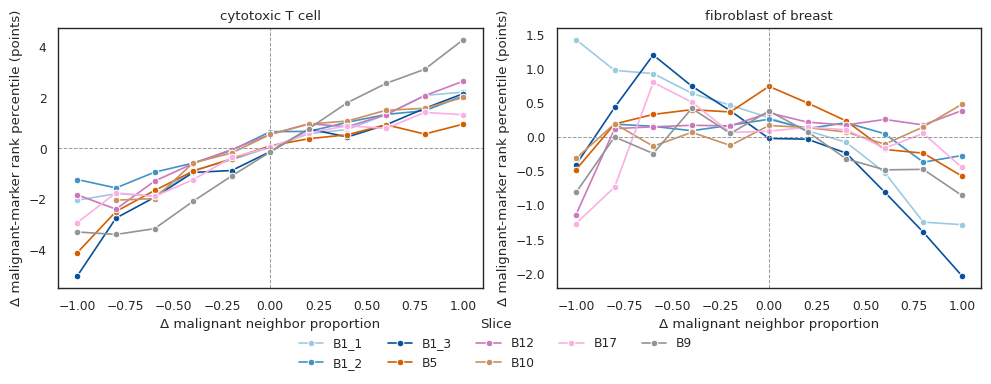

,slice,query_cell_type,neighbor_family,median_rank_slope,n_queries
12,GSM9509156_breast_breast_B17_B17_rctd_annotated,cytotoxic T cell,Malignant,0.001734,290
16,GSM9509156_breast_breast_B17_B17_rctd_annotated,fibroblast of breast,Malignant,-0.000372,292
67,GSM9509162_breast_breast_B12_B12_rctd_annotated,cytotoxic T cell,Malignant,0.001685,296
71,GSM9509162_breast_breast_B12_B12_rctd_annotated,fibroblast of breast,Malignant,-0.000115,299
123,GSM9509164_breast_breast_B10_B10_rctd_annotated,cytotoxic T cell,Malignant,0.001583,294
127,GSM9509164_breast_breast_B10_B10_rctd_annotated,fibroblast of breast,Malignant,-0.000202,298
178,GSM9509166_breast_breast_B9_B9_rctd_annotated,cytotoxic T cell,Malignant,0.004870,300
182,GSM9509166_breast_breast_B9_B9_rctd_annotated,fibroblast of breast,Malignant,-0.000552,300
234,GSM9509171_breast_breast_B5_B5_rctd_annotated,cytotoxic T cell,Malignant,0.001234,295
237,GSM9509171_breast_breast_B5_B5_rctd_annotated,fibroblast of breast,Malignant,-0.001036,299


In [8]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),squeeze=False)
for ax,(query_type,family) in zip(axes.flat,EXAMPLES):
    subset=rank_examples.loc[rank_examples.query_cell_type.eq(query_type)&rank_examples.neighbor_family.eq(family)].copy()
    if subset.empty:
        ax.text(.5,.5,'No expressed-marker support',ha='center',va='center',transform=ax.transAxes)
    else:
        subset['delta_proportion_bin']=np.rint(subset.delta_neighbor_proportion*5)/5
        by_query=subset.groupby(['slice','query_cell_id','delta_proportion_bin']).delta_marker_rank_percentile.mean().reset_index()
        by_slice=by_query.groupby(['slice','delta_proportion_bin']).agg(response=('delta_marker_rank_percentile','mean'),n_queries=('query_cell_id','nunique')).reset_index()
        by_slice=by_slice.loc[by_slice.n_queries>=5].copy();by_slice['response']*=100
        sns.lineplot(data=by_slice,x='delta_proportion_bin',y='response',hue='slice',marker='o',estimator=None,ax=ax,
                     hue_order=SLICE_ORDER,palette=SLICE_PALETTE,legend=(ax is axes.flat[0]))
    ax.axhline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.axvline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.set(title=query_type,xlabel=f'Δ {family.lower()} neighbor proportion',ylabel='Δ malignant-marker rank percentile (points)')
handles,labels=axes.flat[0].get_legend_handles_labels()
if handles:
    axes.flat[0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=5,bbox_to_anchor=(.5,-.1),frameon=False)
fig.tight_layout();save_numbered(fig,'malignant_marker_rank_examples_delta_context');plt.show()
display(supported_ranks.loc[supported_ranks.query_cell_type.isin([e[0] for e in EXAMPLES]) &
                           supported_ranks.neighbor_family.eq('Malignant')])


## How much malignant-neighbor variation is present naturally?

These distributions use **every eligible cell** of the tested types in the selected slices, rather than only the 150 sampled query cells or the deliberately diverse swapped contexts. Query eligibility matches the experiment: ≥10 counts, ≥5 expressed genes, finite coordinates and labels, and five eligible neighbors. Neighbors have >10 counts. Summaries require five neighbors under both definitions so the two views compare the same query cells.

- **Model context:** the five nearest eligible neighbors excluding the query's exact annotated type, matching the input used in the experiment.
- **Physical context:** the five nearest eligible neighbors allowing the query's own type, describing local spatial context without that type exclusion.

Malignant queries have zero malignant proportion in the model context **by construction**. This must not be interpreted as a lack of malignant clustering in the tissue; the physical-context panel shows their natural local tumor context. Both definitions allow proportions 0, 0.2, …, 1. Slices are displayed separately, with pooled cell-weighted and slice-balanced tables also provided.


,cell_type,definition,n_cells,n_slices,pooled_mean,pooled_sd,pooled_fraction_zero,median_slice_sd,median_slice_iqr,n_slices_with_context_variation
0,"CD4-positive, alpha-beta memory T cell",model_context,14783,8,0.084678,0.182439,0.764459,0.174864,0.10,8
1,"CD4-positive, alpha-beta memory T cell",physical_context,14783,8,0.077535,0.175502,0.782791,0.166547,0.10,8
2,capillary endothelial cell,model_context,45576,8,0.219379,0.287682,0.526527,0.277995,0.40,8
3,capillary endothelial cell,physical_context,45576,8,0.150974,0.230517,0.612647,0.210060,0.20,8
4,classical monocyte,model_context,54629,8,0.186890,0.270229,0.579802,0.222472,0.30,8
5,classical monocyte,physical_context,54629,8,0.158842,0.246387,0.617840,0.207505,0.20,8
6,cytotoxic T cell,model_context,38698,8,0.134002,0.235309,0.676211,0.195784,0.10,8
7,cytotoxic T cell,physical_context,38698,8,0.113747,0.215383,0.710838,0.181668,0.10,8
8,fibroblast of breast,model_context,48726,8,0.219140,0.292882,0.540184,0.271492,0.30,8
9,fibroblast of breast,physical_context,48726,8,0.185462,0.262485,0.574929,0.261906,0.30,8


,slice,cell_type,definition,n_cells,mean,sd,iqr,q10,q90,fraction_zero,n_distinct_proportions,tested,sufficient_family_variation
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",model_context,1975,0.053570,0.148396,0.0,0.0,0.2,0.845063,6,True,True
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",physical_context,1975,0.049823,0.143408,0.0,0.0,0.2,0.855696,6,True,True
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,model_context,6203,0.074158,0.170521,0.0,0.0,0.2,0.790263,6,True,True
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,physical_context,6203,0.063195,0.157906,0.0,0.0,0.2,0.817185,6,True,True
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,natural T-regulatory cell,model_context,3678,0.156552,0.260075,0.2,0.0,0.6,0.656063,6,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,GSM9509166_breast_breast_B9_B9_rctd_annotated,pericyte,physical_context,1222,0.232897,0.288000,0.4,0.0,0.6,0.504092,6,True,True
236,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,model_context,3508,0.318472,0.317794,0.6,0.0,0.8,0.379133,6,True,True
237,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,physical_context,3508,0.285747,0.301860,0.6,0.0,0.8,0.405359,6,True,True
238,GSM9509166_breast_breast_B9_B9_rctd_annotated,malignant cell,model_context,45274,0.000000,0.000000,0.0,0.0,0.0,1.000000,1,True,False


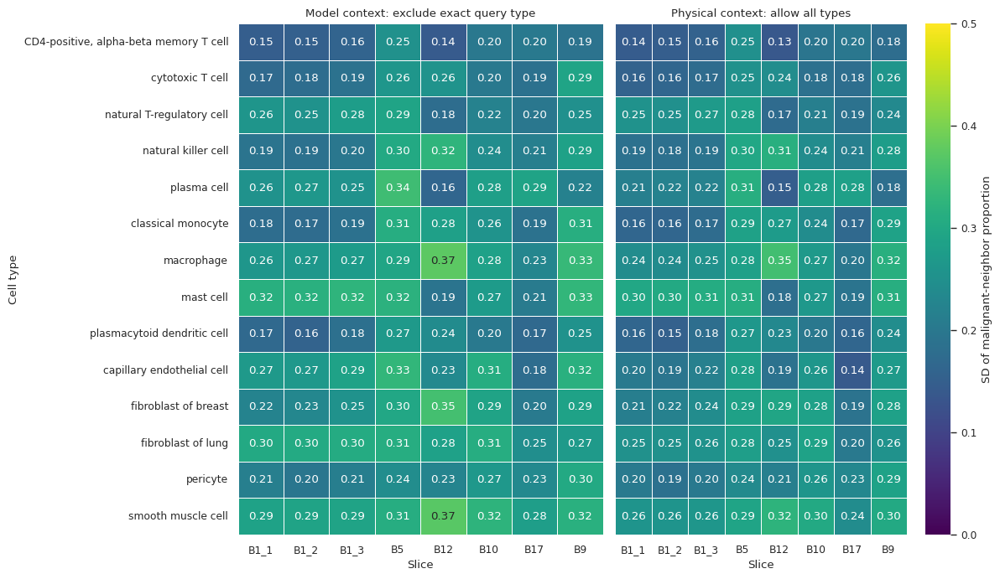

In [9]:
VARIATION = RUN/'context_variability'
if not (VARIATION/'complete.json').exists():
    raise FileNotFoundError(f'Population context-variation analysis incomplete: {VARIATION}')
context_variation = pd.read_csv(VARIATION/'slice_context_variability.csv')
context_distribution = pd.read_csv(VARIATION/'slice_distributions.csv')
context_pooled = pd.read_csv(VARIATION/'pooled_context_variability.csv')
display(context_pooled)
display(context_variation[['slice','cell_type','definition','n_cells','mean','sd','iqr',
                          'q10','q90','fraction_zero','n_distinct_proportions','tested','sufficient_family_variation']])
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
for ax,definition,title in zip(axes,['model_context','physical_context'],
                              ['Model context: exclude exact query type','Physical context: allow all types']):
    heat=context_variation.loc[context_variation.definition.eq(definition)].pivot(index='cell_type',columns='slice',values='sd')
    heat=heat.reindex(index=TYPE_ORDER,columns=SLICE_ORDER).rename(columns=SLICE_LABELS)
    sns.heatmap(heat,cmap='viridis',vmin=0,vmax=.5,annot=True,fmt='.2f',linewidths=.5,ax=ax,
                cbar=(definition=='physical_context'),cbar_kws={'label':'SD of malignant-neighbor proportion'})
    ax.set(title=title,xlabel='Slice',ylabel='Cell type' if definition=='model_context' else '')
fig.tight_layout();save_numbered(fig,'natural_malignant_context_sd');plt.show()


### Distribution of malignant-neighbor proportions

Stacked bars average the per-slice proportions equally across slices containing that cell type. Thus, a large slice does not dominate the distribution. The pooled table above separately reports cell-weighted results. Zero cells and absent types remain unavailable rather than being assigned zero variance.


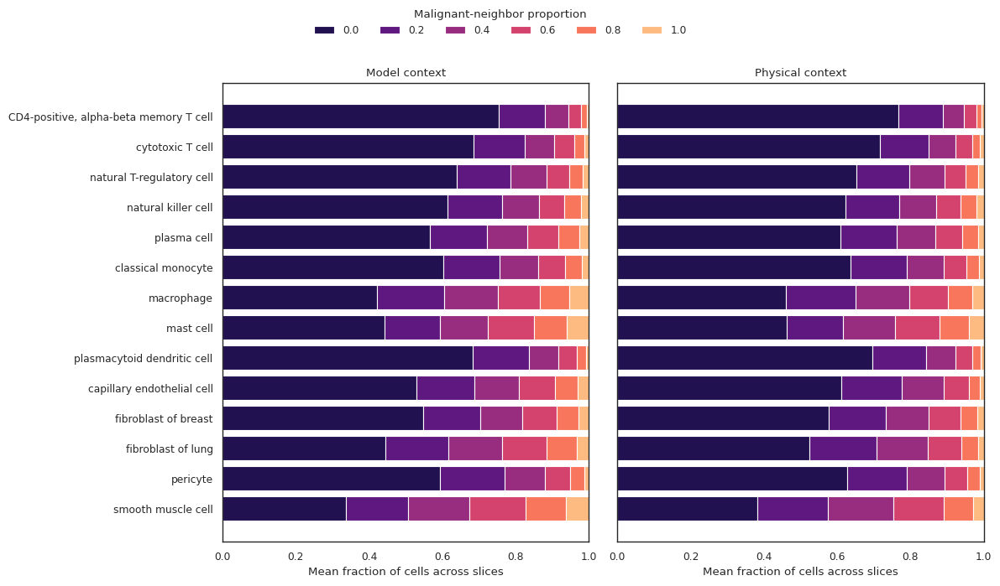

In [10]:
balanced = pd.read_csv(VARIATION/'slice_balanced_distribution.csv')
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
levels=[i/5 for i in range(6)]
level_colors=sns.color_palette('magma',6)
for ax,definition,title in zip(axes,['model_context','physical_context'],['Model context','Physical context']):
    table=balanced.loc[balanced.definition.eq(definition)].pivot(index='cell_type',columns='malignant_neighbor_proportion',values='mean_slice_fraction')
    table=table.reindex(index=TYPE_ORDER,columns=levels)
    left=np.zeros(len(TYPE_ORDER))
    for level,color in zip(levels,level_colors):
        values=table[level].fillna(0).to_numpy()
        ax.barh(np.arange(len(TYPE_ORDER)),values,left=left,color=color,label=f'{level:.1f}')
        left+=values
    ax.set_yticks(np.arange(len(TYPE_ORDER)),TYPE_ORDER)
    ax.set(xlim=(0,1),xlabel='Mean fraction of cells across slices',title=title)

axes[0].invert_yaxis()
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,title='Malignant-neighbor proportion',loc='upper center',ncol=6,frameon=False)
fig.tight_layout(rect=[0,0,1,.91]);save_numbered(fig,'natural_malignant_context_distribution');plt.show()


## Actual query proximity and swapped donor neighborhoods

Original-context plots retain each query's actual 2D centroid distance to the nearest annotated malignant cell. Malignant reference cells use all finite-coordinate annotations, without a count filter. Original-context marker scores and ranks use the **32-gene breast cancer panel**.

The donor-context comparison below uses **malignant cells / five nearest neighbors of a different annotated cell type at the donor location**, replacing the previous donor-distance x-axis. This describes the source neighborhood for a substituted context; the fixed query does not move. `DONOR_FRACTION_X_MODE` in configuration selects donor fraction minus the query's true original-context fraction (default), or absolute donor fraction. All relevant marker scores and rank responses use the same 32-gene panel. Unchanged controls are verified separately.


In [11]:
DISTANCE_SUMMARY = MARKER_REFRESH/'summaries_distance'
DISTANCE_X_MODE = 'delta'  # 'delta' or 'absolute'
DISTANCE_BIN_WIDTH_UM = 25
MIN_QUERIES_PER_DISTANCE_BIN = 5
if DISTANCE_X_MODE not in {'delta','absolute'}:
    raise ValueError("DISTANCE_X_MODE must be 'delta' or 'absolute'")
if not (DISTANCE_SUMMARY/'complete.json').exists():
    raise FileNotFoundError(f'Distance summaries not available: {DISTANCE_SUMMARY}')
print(json.loads((DISTANCE_SUMMARY/'complete.json').read_text()))
distance_original = pd.read_csv(DISTANCE_SUMMARY/'query_original_distance_scores.csv')
distance_contexts = pd.read_csv(DISTANCE_SUMMARY/'example_distance_responses.csv.gz')
distance_correlations = pd.read_csv(DISTANCE_SUMMARY/'original_distance_correlations.csv')
distance_context_correlations = pd.read_csv(DISTANCE_SUMMARY/'query_context_distance_correlations.csv')
display(pd.read_csv(DISTANCE_SUMMARY/'distance_audit.csv'))

from encoded_donor_fraction import encoded_donor_fraction
from all_type_marker_context_responses import all_type_marker_context_responses
DONOR_ALL_TYPE_RESULTS = RUN / "all_type_donor_context_markers32_20261019"
all_donor_marker_responses = all_type_marker_context_responses(
    RUN, BREAST_CANCER_MARKERS, DONOR_ALL_TYPE_RESULTS)
donor_fraction_contexts, donor_fraction_correlations = encoded_donor_fraction(
    RUN, all_donor_marker_responses, DONOR_ALL_TYPE_RESULTS)
DONOR_T_CELL_TYPES = ["CD4-positive, alpha-beta memory T cell", "cytotoxic T cell", "natural T-regulatory cell"]
donor_fraction_contexts["query_group"] = donor_fraction_contexts.query_cell_type.replace(
    {t: "T cells (pooled)" for t in DONOR_T_CELL_TYPES})
donor_fraction_correlations["query_group"] = donor_fraction_correlations.query_cell_type.replace(
    {t: "T cells (pooled)" for t in DONOR_T_CELL_TYPES})


{'n_slices': 8, 'n_queries': 33567, 'units': 'micrometers', 'distance': '2D Euclidean centroid distance to nearest annotated malignant cell in same slice; all finite-coordinate malignant cells, no source-count filter', 'malignant_queries': 'Self included: distance zero; omitted from proximity-response plots', 'context_donor_distance': 'Distance at the donor location, not physical relocation of the query; raw distance and delta relative to original query both exported', 'marker_genes': ['ABCC11', 'APOBEC3B', 'AR', 'CAV1', 'CCND1', 'CDH1', 'CEACAM6', 'CENPF', 'CXCL12', 'EGFR', 'ERBB2', 'ESR1', 'FOXA1', 'GATA3', 'KIT', 'KRT7', 'LDHB', 'LRRC15', 'MDM2', 'PCLAF', 'PGR', 'PTGDS', 'RUNX1', 'S100A4', 'SCD', 'SFRP1', 'SNAI1', 'TACSTD2', 'TCF4', 'TOP2A', 'ZEB1', 'ZEB2']}


,slice,n_annotated_malignant_cells,n_finite_coordinate_cells,n_queries
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,40931,124525,4200
1,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,46977,141262,4200
2,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,37022,108069,4200
3,GSM9509171_breast_breast_B5_B5_rctd_annotated,109305,185547,4200
4,GSM9509162_breast_breast_B12_B12_rctd_annotated,87591,151364,4200
5,GSM9509164_breast_breast_B10_B10_rctd_annotated,30217,66079,4200
6,GSM9509156_breast_breast_B17_B17_rctd_annotated,25574,68181,4167
7,GSM9509166_breast_breast_B9_B9_rctd_annotated,45274,98081,4200


### Original-context proximity associations across cell types

Each tile is a within-slice Spearman correlation across queried cells of the same annotated type. Positive values mean larger scores/ranks farther from malignant cells; negative values mean larger scores/ranks nearer malignant cells. Gray tiles have insufficient support. The two metrics use the expressed breast cancer-panel-marker set defined above. These markers are not uniquely malignant.


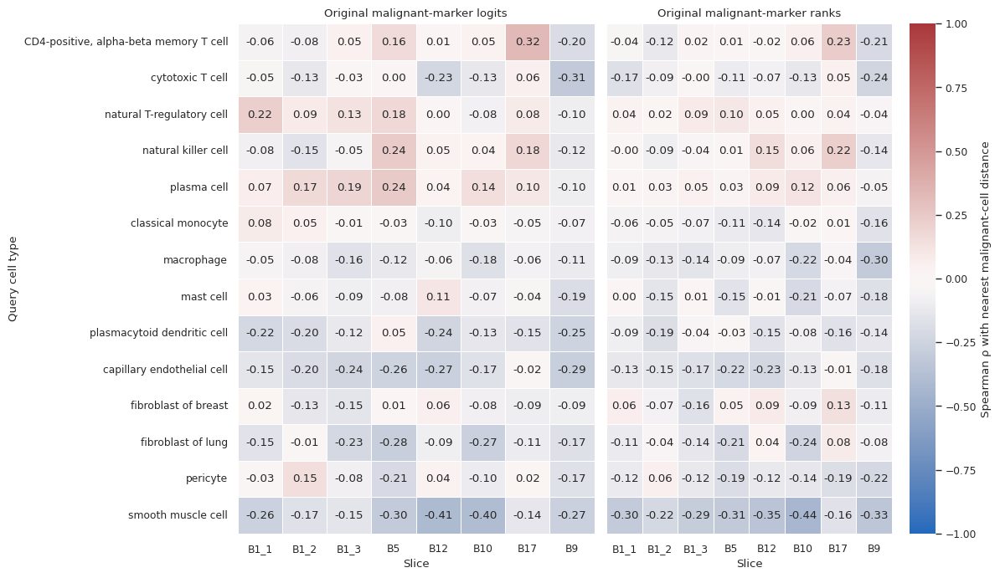

n_supported_slices  \
query_cell_type                        metric                                                 
CD4-positive, alpha-beta memory T cell malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
capillary endothelial cell             malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
classical monocyte                     malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
cytotoxic T cell                       malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
fibroblast of breast                   malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
fibroblast of lung                     malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
macrophage                             malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
mast cell                              malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
natural T-regulatory cell              malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
natural killer cell                    malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
pericyte                               malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
plasma cell                            malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
plasmacytoid dendritic cell            malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile                   8   
                                       mean_expressed_gene_logit                          8   
smooth muscle cell                     malignant_marker_logit                             8   
                                       malignant_marker_rank_percentile            

In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
nonmalignant_types=[t for t in TYPE_ORDER if t!='malignant cell']
for ax,metric,title in zip(axes,['malignant_marker_logit','malignant_marker_rank_percentile'],
                          ['Original malignant-marker logits','Original malignant-marker ranks']):
    selected=distance_correlations.loc[distance_correlations.metric.eq(metric)]
    heat=selected.pivot(index='query_cell_type',columns='slice',values='spearman_rho').reindex(index=nonmalignant_types,columns=SLICE_ORDER).rename(columns=SLICE_LABELS)
    ax.set_facecolor('0.9')
    sns.heatmap(heat,mask=heat.isna(),cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',linewidths=.5,
                ax=ax,cbar=(metric=='malignant_marker_rank_percentile'),cbar_kws={'label':'Spearman ρ with nearest malignant-cell distance'})
    ax.set(title=title,xlabel='Slice',ylabel='Query cell type' if metric=='malignant_marker_logit' else '')
fig.tight_layout();save_numbered(fig,'original_malignant_distance_correlations');plt.show()
display(distance_correlations.groupby(['query_cell_type','metric']).agg(n_supported_slices=('spearman_rho','count'),median_rho=('spearman_rho','median')))


### Predefined examples: actual query distance and original scores

Points are individual query cells colored by slice. Distances use a symmetric-log display with a 10-µm linear region so zeros and the full distance range remain visible. These scores are absolute original-context values, rather than changes from a swapped context. Only queries expressing at least one listed breast cancer-panel marker contribute; ranks additionally require ≥10 expressed genes.


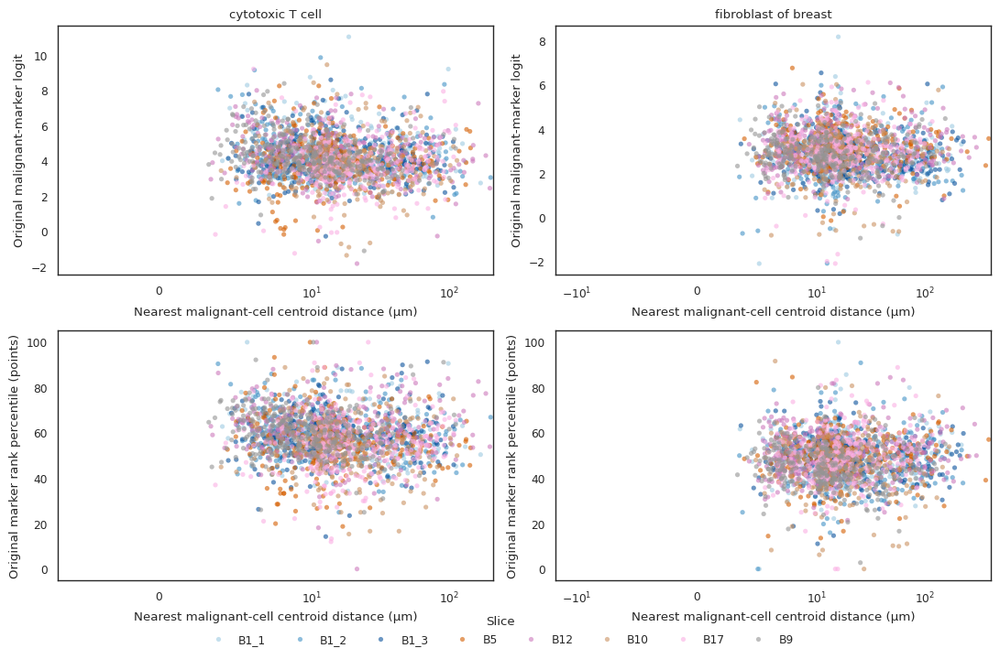

In [13]:
fig,axes=plt.subplots(2,2,figsize=(11,7),squeeze=False)
for col,(query_type,_) in enumerate(EXAMPLES):
    selected=distance_original.loc[distance_original.query_cell_type.eq(query_type)].copy()
    selected['malignant_marker_rank_percentile_points']=100*selected.malignant_marker_rank_percentile
    for row,metric,label in [(0,'malignant_marker_logit','Original malignant-marker logit'),
                             (1,'malignant_marker_rank_percentile_points','Original marker rank percentile (points)')]:
        ax=axes[row,col];data=selected.dropna(subset=[metric])
        if data.empty:
            ax.text(.5,.5,'Insufficient marker support',ha='center',va='center',transform=ax.transAxes)
        else:
            sns.scatterplot(data=data,x='query_distance_um',y=metric,hue='slice',hue_order=SLICE_ORDER,
                            palette=SLICE_PALETTE,s=14,alpha=.6,edgecolor='none',legend=(row==0 and col==0),ax=ax)
        ax.set_xscale('symlog',linthresh=10)
        ax.set(title=query_type if row==0 else '',xlabel='Nearest malignant-cell centroid distance (µm)',ylabel=label)
handles,labels=axes[0,0].get_legend_handles_labels()
if handles:
    axes[0,0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=8,bbox_to_anchor=(.5,-.03),frameon=False)
fig.tight_layout();save_numbered(fig,'original_malignant_distance_examples');plt.show()


### Swapped-context donor malignant fraction versus response

X is **donor malignant fraction − the query cell's true malignant fraction**, using the five nearest eligible neighbors of a **different annotated cell type** from the donor/query respectively. Fractions come directly from the saved encoded model contexts, so they match inference; the existing source eligibility rule (>10 counts) is retained. Counts are divided by five, and count differences are computed before division so equal deltas stay tied.

Responses use the **32-gene breast cancer panel**: top row is mean expressed-marker logit change from the original context; bottom row is marker rank-percentile change (percentage points). Population bins, query/section aggregation, and support thresholds are retained. `DONOR_FRACTION_X_MODE = "delta"` is the default; `"absolute"` remains available. Zero fraction change does not imply an identical context or zero response, because other neighbor identities/order can change. This definition applies to these swapped-donor plots; the separately labeled physical 20-neighbor analyses retain their definitions.

Columns follow `PANEL_QUERY_TYPES`, using the same three selected query groups as the later plots. T-cell subtypes are pooled when “T cells (pooled)” is selected. All query types are cached so changing the selected columns does not require inference.


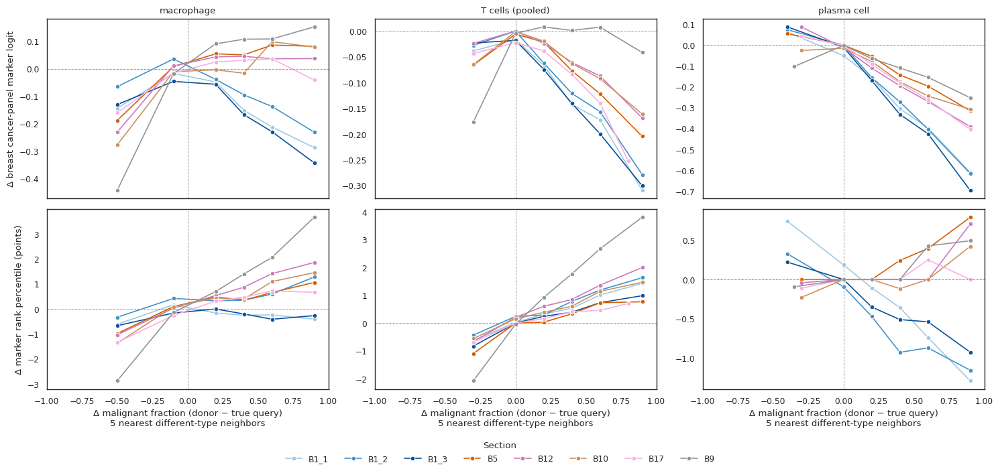

n_queries  \
slice                                           query_group                 metric                                    
GSM9509156_breast_breast_B17_B17_rctd_annotated T cells (pooled)            delta_marker_logit                  874   
                                                                            delta_marker_rank_percentile        857   
                                                capillary endothelial cell  delta_marker_logit                  292   
                                                                            delta_marker_rank_percentile        291   
                                                classical monocyte          delta_marker_logit                  290   
...                                                                                                             ...   
GSM9509174_breast_breast_B1_B1_3_rctd_annotated plasma cell                 delta_marker_rank_percentile        298   
                                                plasmacytoid dendritic cell delta_marker_logit                  300   
                                                                            delta_marker_rank_percentile        300   
                                                smooth muscle cell          delta_marker_logit                  299   
                                                                            delta_marker_rank_percentile        299   

                                                                                                          median_within_query_rho  
slice                                           query_group                 metric                                                 
GSM9509156_breast_breast_B17_B17_rctd_annotated T cells (pooled)            delta_marker_logit                          -0.476157  
                                                                            delta_marker_rank_percentile                 0.328531  
                                                capillary endothelial cell  delta_marker_logit                          -0.636467  
                                                                            delta_marker_rank_percentile                -0.344295  
                                                classical monocyte          delta_marker_logit                          -0.508507  
...                                                                                                                           ...  
GSM9509174_breast_breast_B1_B1_3_rctd_annotated plasma cell                 delta_marker_rank_percentile                -0.421998  
                                                plasmacytoid dendritic cell delta_marker_logit                          -0.268674  
                                                                            delta_marker_rank_percentile                 0.106672  
                                                smooth muscle cell          delta_marker_logit                          -0.419283  
                                                                            delta_marker_rank_percentile                 0.090696  

[192 rows x 2 columns]

In [14]:
if DONOR_FRACTION_X_MODE not in {"absolute", "delta"}:
    raise ValueError("DONOR_FRACTION_X_MODE must be absolute or delta")
x_column = "donor_malignant_fraction_k5" if DONOR_FRACTION_X_MODE == "absolute" else "delta_donor_malignant_fraction_k5"
x_label = "Donor malignant fraction (5 nearest different-type neighbors)" if DONOR_FRACTION_X_MODE == "absolute" else "Δ malignant fraction (donor − true query)\n5 nearest different-type neighbors"
fig, axes = plt.subplots(2, len(PANEL_QUERY_TYPES), figsize=(15, 7), squeeze=False, sharex=True)
donor_plot_tables = []
for col, query_type in enumerate(PANEL_QUERY_TYPES):
    selected = donor_fraction_contexts.loc[
        donor_fraction_contexts.query_group.eq(query_type) &
        donor_fraction_contexts.context_kind.eq("representative")].copy()
    selected["query_group"] = query_type
    selected["donor_bin"] = population_exposure_bins(selected, x_column)
    selected["delta_marker_rank_percentile_points"] = 100 * selected.delta_marker_rank_percentile
    for row, metric, label in [(0, "delta_marker_logit", "Δ breast cancer-panel marker logit"),
                               (1, "delta_marker_rank_percentile_points", "Δ marker rank percentile (points)")]:
        ax = axes[row, col]
        by_query = selected.dropna(subset=[metric]).groupby(
            ["slice", "query_cell_id", "donor_bin"], observed=True).agg(
                response=(metric, "mean"), x=(x_column, "median")).reset_index()
        by_slice = by_query.groupby(["slice", "donor_bin"], observed=True).agg(
            response=("response", "median"), x=("x", "median"), n_queries=("query_cell_id", "nunique")).reset_index()
        by_slice = by_slice.loc[by_slice.n_queries >= MIN_QUERIES_PER_DONOR_BIN]
        donor_plot_tables.append(by_slice.assign(query_cell_type=query_type, metric=metric))
        if not by_slice.empty:
            sns.lineplot(data=by_slice, x="x", y="response", hue="slice", hue_order=SLICE_ORDER,
                palette=SLICE_PALETTE, marker="o", estimator=None, legend=(row == 0 and col == 0), ax=ax)
        else:
            ax.text(0.5, 0.5, "Insufficient population-bin support", ha="center", va="center", transform=ax.transAxes)
        ax.axhline(0, color="0.6", linestyle="--", linewidth=0.7)
        if DONOR_FRACTION_X_MODE == "delta": ax.axvline(0, color="0.6", linestyle="--", linewidth=0.7)
        ax.set(title=query_type if row == 0 else "", xlabel=x_label, ylabel=label if col == 0 else "",
               xlim=(0, 1) if DONOR_FRACTION_X_MODE == "absolute" else (-1, 1))
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    axes[0, 0].get_legend().remove()
    fig.legend(handles, [SLICE_LABELS.get(label, label) for label in labels], title="Section",
               loc="lower center", ncol=8, bbox_to_anchor=(0.5, -0.01), frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])
save_numbered(fig, f"context_donor_malignant_fraction_k5_selected_types_{DONOR_FRACTION_X_MODE}")
plt.show()
donor_population_curves = pd.concat(donor_plot_tables, ignore_index=True)
donor_population_curves.to_csv(FIGURES / f"context_donor_malignant_fraction_k5_selected_types_{DONOR_FRACTION_X_MODE}_curves.csv", index=False)
display(donor_fraction_correlations.groupby(["slice", "query_group", "metric"]).agg(
    n_queries=("spearman_rho", "count"), median_within_query_rho=("spearman_rho", "median")))


## Are cells nearer malignant cells more context-responsive?

Here the x-axis is the **query cell's actual distance to the nearest annotated malignant centroid**, not the context donor's distance. The y-axis measures how strongly that query responds across substituted neighborhoods. This is different from comparing absolute original-context scores with proximity.

Primary measurements use an **identical context panel for all queries of the same type in the same slice**. The prespecified panel is reconstructed from donor IDs. When a query is itself one of the panel's donors, its original-context prediction fills that panel position; otherwise, extra original baselines and unchanged controls are excluded. Every query is explicitly checked to have the same donor IDs and ordering. No new inference is required.

- **All-gene logit SD:** average across expressed genes of each gene's SD across the common panel.
- **Malignant-marker logit SD:** SD across the panel of the mean expressed breast cancer-panel-marker logit score.
- **Pairwise rank distance:** mean of 1 − Spearman ρ over all pairs of panel contexts, restricted to the same expressed genes within a query (≥10 genes; average ranks for ties).

These measures do not subtract the original context, so variation in the original neighborhood does not determine responsiveness mechanically. They still depend on the query's expression profile, available expressed markers, and chosen context panel. Panels are matched within slice/type, not across types or slices. Malignant query cells remain excluded from distance associations because their self-inclusive distance is zero.

**Updated marker set:** the query-distance responsiveness analyses below use the 32 user-supplied genes in `requested_marker_genes_20261019.json`. Earlier marker-dependent summaries are also refreshed to the same 32-gene panel. Only expressed selected genes contribute to each query’s score.


In [15]:
QUERY_RESPONSIVENESS = RUN/'summaries_query_distance_responsiveness_markers32_20261019'
FIGURES = BREAST_MARKER_FIGURES
FIGURES.mkdir(exist_ok=True)
SELECTED_RESPONSE_MARKERS = json.loads((RUN/'requested_marker_genes_20261019.json').read_text())
if not (QUERY_RESPONSIVENESS/'complete.json').exists():
    raise FileNotFoundError(f'Query-distance responsiveness not available: {QUERY_RESPONSIVENESS}')
print(json.loads((QUERY_RESPONSIVENESS/'complete.json').read_text()))
query_distance_responses = pd.read_csv(QUERY_RESPONSIVENESS/'query_distance_responsiveness.csv')
query_distance_correlations = pd.read_csv(QUERY_RESPONSIVENESS/'distance_responsiveness_correlations.csv')
matched_panels = pd.read_csv(QUERY_RESPONSIVENESS/'matched_context_panels.csv')
display(matched_panels.drop(columns='donor_ids_json'))
PRIMARY_DISTANCE_RESPONSES = {
    'mean_gene_logit_sd':'All-gene logit SD',
    'malignant_marker_score_sd':'Selected-marker logit SD',
    'mean_pairwise_rank_distance':'Pairwise gene-rank distance',
}


{'n_slices': 8, 'n_queries': 33567, 'marker_genes': ['ABCC11', 'APOBEC3B', 'AR', 'CAV1', 'CCND1', 'CDH1', 'CEACAM6', 'CENPF', 'CXCL12', 'EGFR', 'ERBB2', 'ESR1', 'FOXA1', 'GATA3', 'KIT', 'KRT7', 'LDHB', 'LRRC15', 'MDM2', 'PCLAF', 'PGR', 'PTGDS', 'RUNX1', 'S100A4', 'SCD', 'SFRP1', 'SNAI1', 'TACSTD2', 'TCF4', 'TOP2A', 'ZEB1', 'ZEB2'], 'context_panels': 'Identical donor IDs within each slice and query type, including original rows only when that donor belongs to the shared panel', 'primary': 'Baseline-independent SD across contexts and mean pairwise rank distance', 'sensitivity': 'Existing original-context-relative logit/rank changes', 'logit_epsilon': 1e-06, 'distance': 'Actual query centroid distance in micrometers, same annotated malignant reference as prior section'}


,slice,query_cell_type,n_panel_contexts,n_queries
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",30,300
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,capillary endothelial cell,30,300
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,classical monocyte,30,300
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,30,300
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,fibroblast of breast,30,300
...,...,...,...,...
107,GSM9509166_breast_breast_B9_B9_rctd_annotated,natural killer cell,30,300
108,GSM9509166_breast_breast_B9_B9_rctd_annotated,pericyte,30,300
109,GSM9509166_breast_breast_B9_B9_rctd_annotated,plasma cell,30,300
110,GSM9509166_breast_breast_B9_B9_rctd_annotated,plasmacytoid dendritic cell,30,300


### Associations across cell types and slices

Tiles are within-slice/type correlations between actual query distance and responsiveness. **Negative values mean nearer cells tend to respond more strongly; positive values mean farther cells do.** Gray indicates insufficient support (fewer than ten queries or insufficient distance/response variation). Values are descriptive, without treating individual cells as independent biological replicates. A lack of association would not contradict the preceding donor-context distance response: the two analyses ask different questions.


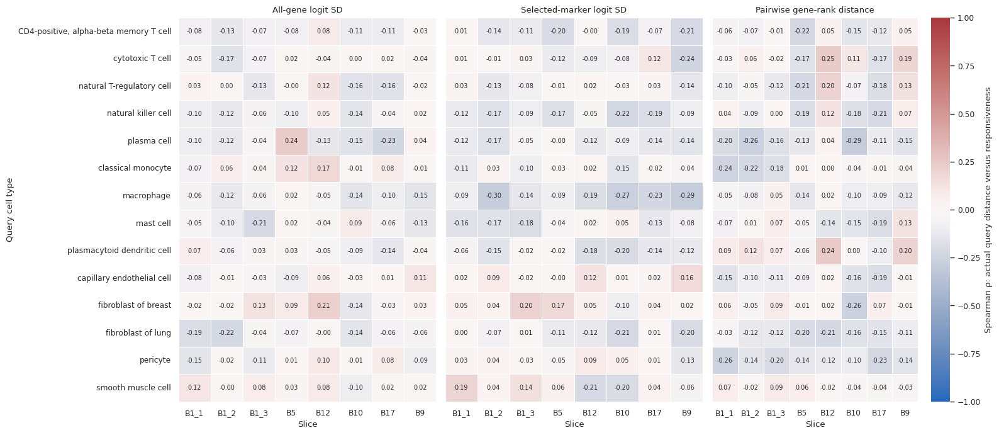

n_supported_slices  \
query_cell_type                        metric                                            
CD4-positive, alpha-beta memory T cell malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
capillary endothelial cell             malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
classical monocyte                     malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
cytotoxic T cell                       malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
fibroblast of breast                   malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
fibroblast of lung                     malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
macrophage                             malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
mast cell                              malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
natural T-regulatory cell              malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
natural killer cell                    malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
pericyte                               malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
plasma cell                            malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
plasmacytoid dendritic cell            malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   
smooth muscle cell                     malignant_marker_score_sd                     8   
                                       mean_gene_logit_sd                            8   
                                       mean_pairwise_rank_distance                   8   

                                                                    median_rho  \
query_cell_type          

In [16]:
fig,axes=plt.subplots(1,3,figsize=(16,7),sharey=True)
for ax,(metric,title) in zip(axes,PRIMARY_DISTANCE_RESPONSES.items()):
    selected=query_distance_correlations.loc[query_distance_correlations.metric.eq(metric)]
    heat=selected.pivot(index='query_cell_type',columns='slice',values='spearman_rho').reindex(index=nonmalignant_types,columns=SLICE_ORDER).rename(columns=SLICE_LABELS)
    ax.set_facecolor('0.9')
    sns.heatmap(heat,mask=heat.isna(),cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',linewidths=.5,
                annot_kws={'fontsize':7},ax=ax,cbar=(metric=='mean_pairwise_rank_distance'),
                cbar_kws={'label':'Spearman ρ: actual query distance versus responsiveness'})
    ax.set(title=title,xlabel='Slice',ylabel='Query cell type' if metric=='mean_gene_logit_sd' else '')
fig.tight_layout();save_numbered(fig,'query_distance_vs_context_responsiveness');plt.show()
display(query_distance_correlations.loc[query_distance_correlations.metric.isin(PRIMARY_DISTANCE_RESPONSES)].groupby(['query_cell_type','metric']).agg(
    n_supported_slices=('spearman_rho','count'),median_rho=('spearman_rho','median'),
    n_negative_slices=('spearman_rho',lambda x:int((x<0).sum()))))


### Predefined examples: actual query proximity versus response spread

Faint points are individual queries; colored curves show per-slice means in 25-µm query-distance bins with at least five supported queries. The full positive-distance range is retained on a symmetric-log x-axis. Marker responsiveness requires at least one expressed listed marker; pairwise ranks require ≥10 expressed genes. This is not a plot of absolute marker scores or original-context-relative changes.


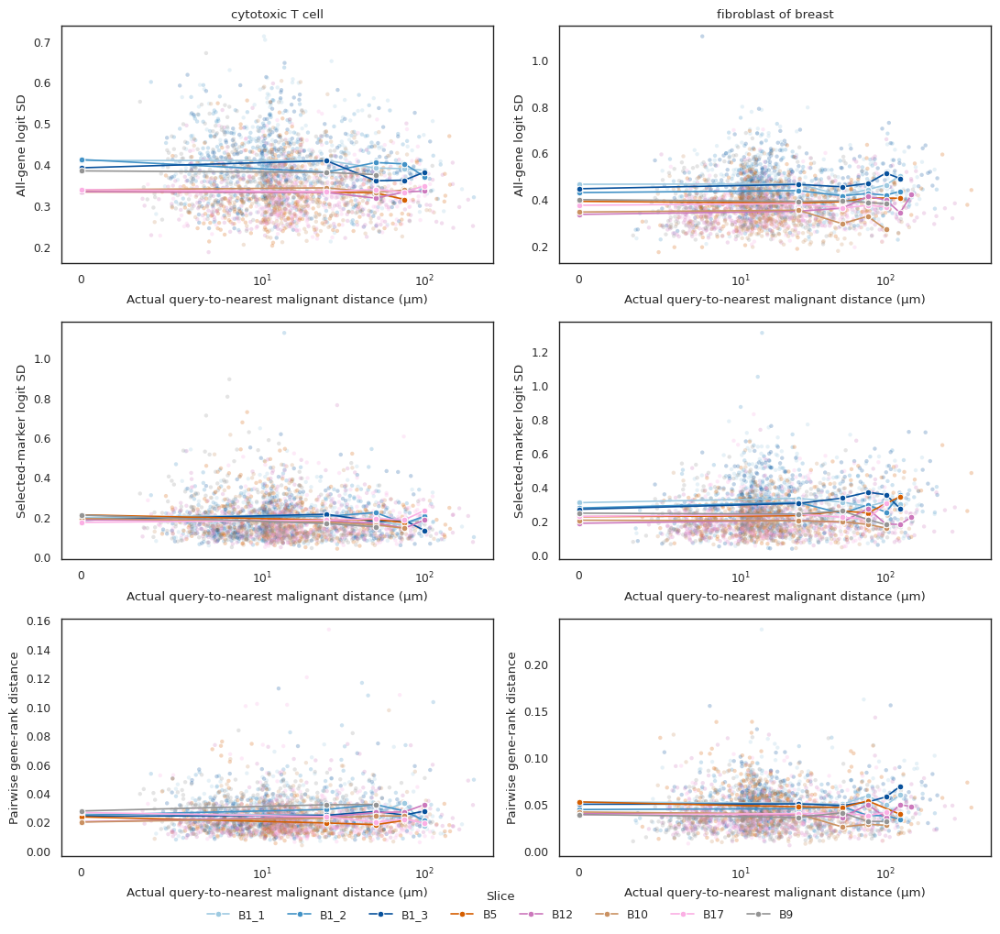

In [17]:
fig,axes=plt.subplots(3,2,figsize=(11,10),squeeze=False)
for col,(query_type,_) in enumerate(EXAMPLES):
    selected=query_distance_responses.loc[query_distance_responses.query_cell_type.eq(query_type)].copy()
    selected['distance_bin']=DISTANCE_BIN_WIDTH_UM*np.rint(selected.query_distance_um/DISTANCE_BIN_WIDTH_UM)
    for row,(metric,label) in enumerate(PRIMARY_DISTANCE_RESPONSES.items()):
        ax=axes[row,col];data=selected.dropna(subset=[metric])
        if not data.empty:
            sns.scatterplot(data=data,x='query_distance_um',y=metric,hue='slice',hue_order=SLICE_ORDER,
                            palette=SLICE_PALETTE,s=10,alpha=.25,edgecolor='none',legend=False,ax=ax)
            binned=data.groupby(['slice','distance_bin']).agg(response=(metric,'mean'),n_queries=('query_cell_id','nunique')).reset_index()
            binned=binned.loc[binned.n_queries>=MIN_QUERIES_PER_DISTANCE_BIN]
            if not binned.empty:
                sns.lineplot(data=binned,x='distance_bin',y='response',hue='slice',hue_order=SLICE_ORDER,
                             palette=SLICE_PALETTE,marker='o',estimator=None,legend=(row==0 and col==0),ax=ax)
        else:
            ax.text(.5,.5,'Insufficient support',ha='center',va='center',transform=ax.transAxes)
        ax.set_xscale('symlog',linthresh=10)
        ax.set(title=query_type if row==0 else '',xlabel='Actual query-to-nearest malignant distance (µm)',ylabel=label)
handles,labels=axes[0,0].get_legend_handles_labels()
if handles:
    axes[0,0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=8,bbox_to_anchor=(.5,-.02),frameon=False)
fig.tight_layout();save_numbered(fig,'query_distance_responsiveness_examples');plt.show()


### Sensitivity: change from the original neighborhood

The following table relates the earlier mean absolute logit change and original-relative rank distance to the query's actual proximity. These baseline-relative measures depend on how different the original neighborhood is from the sampled contexts. The matched-panel spread above is the primary analysis for this question. Signed malignant-marker context slopes are also retained in the exported query table for further inspection.


In [18]:
baseline_relative_metrics=['mean_absolute_delta_logit','mean_rank_distance']
display(query_distance_correlations.loc[query_distance_correlations.metric.isin(baseline_relative_metrics)].groupby(['query_cell_type','metric']).agg(
    n_supported_slices=('spearman_rho','count'),median_rho=('spearman_rho','median'),
    n_negative_slices=('spearman_rho',lambda x:int((x<0).sum()))))
display(query_distance_responses.loc[query_distance_responses.query_cell_type.isin([e[0] for e in EXAMPLES]),
    ['slice','query_cell_id','query_cell_type','query_distance_um','n_panel_contexts','n_expressed_genes',
     'n_expressed_malignant_markers',*PRIMARY_DISTANCE_RESPONSES,'mean_absolute_delta_logit','mean_rank_distance']])


n_supported_slices  \
query_cell_type                        metric                                          
CD4-positive, alpha-beta memory T cell mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
capillary endothelial cell             mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
classical monocyte                     mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
cytotoxic T cell                       mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
fibroblast of breast                   mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
fibroblast of lung                     mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
macrophage                             mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
mast cell                              mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
natural T-regulatory cell              mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
natural killer cell                    mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
pericyte                               mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
plasma cell                            mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
plasmacytoid dendritic cell            mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   
smooth muscle cell                     mean_absolute_delta_logit                   8   
                                       mean_rank_distance                          8   

                                                                  median_rho  \
query_cell_type                        metric                                  
CD4-positive, alpha-beta memory T cell mean_absolute_delta_logit    0.410215   
                                       mean_rank_distance           0.226616   
capillary endothelial cell             mean_absolute_delta_logit    0.597522   
                                       mean_rank_distance           0.340698   
classical monocyte                     mean_absolute_delta_logit    0.349306   
                                       mean_rank_distance           0.242176   
cytotoxic T cell                       mean_absolute_delta_logit    0.420779   
                                       mean_rank_distance           0.318001   
fibroblast of breast                   mean_absolute_delta_logit    0.378225   
                                       mean_rank_distance           0.277858   
fibroblast of lung                     mean_absolute_delta_logit    0.468817   
                                       mean_rank_distance           0.351063   
macrophage                             mean_absolute_delta_logit    0.422932   
                                       mean_rank_distance           0.368433   
mast cell                              mean_absolute_delta_logit    0.383927   
                                       mean_rank_distance        

,slice,query_cell_id,query_cell_type,query_distance_um,n_panel_contexts,n_expressed_genes,n_expressed_malignant_markers,mean_gene_logit_sd,malignant_marker_score_sd,mean_pairwise_rank_distance,mean_absolute_delta_logit,mean_rank_distance
900,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:aaejbnnc-1,cytotoxic T cell,8.896107,30,57,10,0.368586,0.099071,0.022841,0.360136,0.016989
901,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:aalmknae-1,cytotoxic T cell,34.408182,30,49,6,0.460702,0.288813,0.047668,0.531930,0.049806
902,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:afgedlpi-1,cytotoxic T cell,10.000475,30,74,7,0.368617,0.231827,0.022690,0.390031,0.018266
903,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:afhdeinb-1,cytotoxic T cell,19.242151,30,28,3,0.272092,0.178554,0.018401,0.316167,0.019704
904,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:agakdcmh-1,cytotoxic T cell,9.499289,30,57,8,0.461820,0.339768,0.022957,0.463942,0.021762
...,...,...,...,...,...,...,...,...,...,...,...,...
30862,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:oijnmajp-1,fibroblast of breast,78.156483,30,21,4,0.383298,0.189561,0.018370,0.682843,0.029481
30863,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:oikadbfm-1,fibroblast of breast,38.945553,30,46,10,0.381950,0.308953,0.020939,0.376573,0.016178
30864,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:oikfnbjf-1,fibroblast of breast,35.020785,30,36,6,0.358669,0.186953,0.011407,0.428782,0.014661
30865,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:oikfndfb-1,fibroblast of breast,34.941058,30,22,4,0.358280,0.251412,0.030683,0.460481,0.047130


## Focused panel: selected-marker context sensitivity near malignant cells

**Primary example: breast fibroblasts.** The left panel relates actual query-to-malignant-cell distance to the SD of the mean expressed selected-marker logit score across the same 30 contexts within each slice/type. Faint points are individual queries. Colored lines connect within-slice medians in prespecified distance bins (0–10, 10–25, 25–50, 50–100, 100–200, and ≥200 µm), retaining bins with ≥3 marker-supported queries; plotted x positions are the actual mean query distances in those bins. All individual queries remain visible even when their bin is too small for a line.

The right panel shows one within-slice Spearman correlation per section, using every marker-supported query rather than the binned values. Negative correlations mean nearby cells have greater context sensitivity. The B1 replicate rows are shaded together to make their relationship explicit. No pooled significance test treats sections as independent donors. The dotted line is the descriptive median section correlation.

This focused plot uses existing data; it uses the expanded query sample; no additional fitting is performed for this plot. Marker sets remain provisional breast cancer-panel genes. The figure establishes an association, rather than marker specificity against matched control genes or correction accuracy.


In [19]:
FOCUSED_QUERY_TYPE = 'fibroblast of breast'  # Optional alternative: 'cytotoxic T cell'.
FOCUSED_METRIC = 'malignant_marker_score_sd'
FOCUSED_DISTANCE_EDGES_UM = [0,10,25,50,100,200,np.inf]
FOCUSED_MIN_QUERIES_PER_BIN = 3
focused_cells = query_distance_responses.loc[
    query_distance_responses.query_cell_type.eq(FOCUSED_QUERY_TYPE)
].dropna(subset=['query_distance_um', FOCUSED_METRIC]).copy()
if focused_cells.empty:
    raise ValueError(f'No marker-supported queries for {FOCUSED_QUERY_TYPE}')
focused_cells['distance_bin'] = pd.cut(focused_cells.query_distance_um,
    FOCUSED_DISTANCE_EDGES_UM, right=False, include_lowest=True)
focused_bins = focused_cells.groupby(['slice','distance_bin'], observed=True).agg(
    mean_distance_um=('query_distance_um','mean'),
    median_responsiveness=(FOCUSED_METRIC,'median'),
    n_queries=('query_cell_id','nunique')).reset_index()
focused_bins = focused_bins.loc[focused_bins.n_queries >= FOCUSED_MIN_QUERIES_PER_BIN].copy()
focused_correlations = query_distance_correlations.loc[
    query_distance_correlations.query_cell_type.eq(FOCUSED_QUERY_TYPE)
    & query_distance_correlations.metric.eq(FOCUSED_METRIC)
].set_index('slice').reindex(SLICE_ORDER).reset_index()
focused_correlations['slice_label'] = focused_correlations['slice'].map(SLICE_LABELS)
focused_valid = focused_correlations.loc[focused_correlations.status.eq('ok')].copy()
focused_median_rho = focused_valid.spearman_rho.median()
focused_negative = int(focused_valid.spearman_rho.lt(0).sum())
display(focused_correlations[['slice_label','n_queries','spearman_rho','status']])


,slice_label,n_queries,spearman_rho,status
0,B1_1,300,0.051897,ok
1,B1_2,297,0.035634,ok
2,B1_3,299,0.197266,ok
3,B5,299,0.165650,ok
4,B12,299,0.047947,ok
5,B10,299,-0.097686,ok
6,B17,296,0.040874,ok
7,B9,300,0.016113,ok


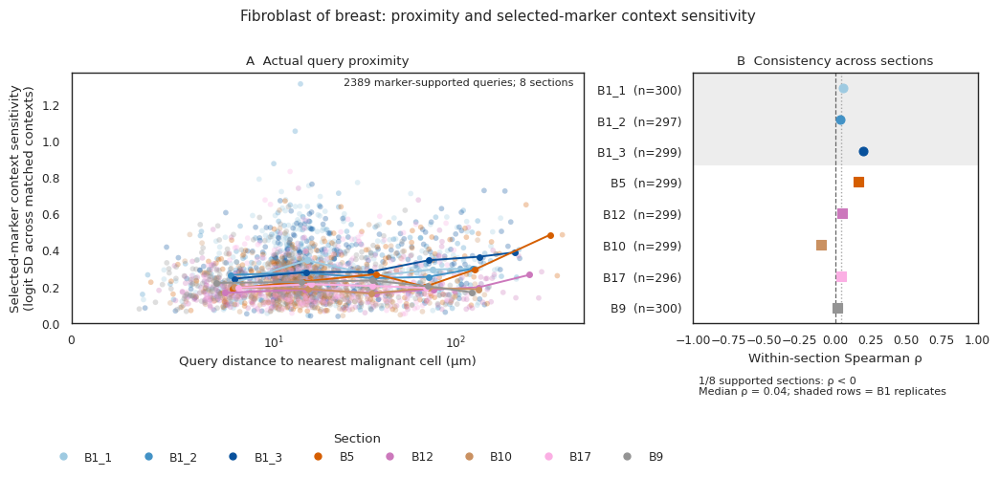

Focused panel exports: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/focused_fibroblast_of_breast_distance_2


In [20]:
fig, (ax_curve, ax_rho) = plt.subplots(1,2,figsize=(10.5,4.3),
    gridspec_kw={'width_ratios':[1.8,1.0]})
for slice_id in SLICE_ORDER:
    current=focused_cells.loc[focused_cells['slice'].eq(slice_id)]
    if current.empty:
        continue
    color=SLICE_PALETTE[slice_id]
    ax_curve.scatter(current.query_distance_um,current[FOCUSED_METRIC],
                     color=color,s=17,alpha=.3,edgecolors='none',zorder=1)
    line=focused_bins.loc[focused_bins['slice'].eq(slice_id)].sort_values('mean_distance_um')
    if not line.empty:
        ax_curve.plot(line.mean_distance_um,line.median_responsiveness,color=color,
                      marker='o',markersize=4,linewidth=1.4,zorder=2)
ax_curve.set_xscale('symlog',linthresh=10)
ax_curve.set_xlim(left=0)
ax_curve.set_ylim(bottom=0)
ax_curve.set(xlabel='Query distance to nearest malignant cell (µm)',
             ylabel='Selected-marker context sensitivity\n(logit SD across matched contexts)',
             title='A  Actual query proximity')
ax_curve.text(.98,.98,f'{len(focused_cells)} marker-supported queries; '
              f'{focused_cells["slice"].nunique()} sections',
              ha='right',va='top',transform=ax_curve.transAxes,fontsize=8)
# Explicitly group related B1 sections while retaining each section's estimate.
replicate_positions=[i for i,s in enumerate(SLICE_ORDER) if SLICE_LABELS[s].startswith('B1_')]
if replicate_positions:
    ax_rho.axhspan(min(replicate_positions)-.45,max(replicate_positions)+.45,
                   color='0.93',zorder=0)
ax_rho.axvline(0,color='0.4',linestyle='--',linewidth=.9,zorder=1)
if pd.notna(focused_median_rho):
    ax_rho.axvline(focused_median_rho,color='0.65',linestyle=':',linewidth=1,zorder=1)
for position,slice_id in enumerate(SLICE_ORDER):
    row=focused_correlations.loc[focused_correlations['slice'].eq(slice_id)].iloc[0]
    if row.status=='ok' and pd.notna(row.spearman_rho):
        ax_rho.scatter(row.spearman_rho,position,color=SLICE_PALETTE[slice_id],s=42,
                       marker='o' if position in replicate_positions else 's',zorder=3)
    else:
        ax_rho.text(.02,position,'Insufficient support',ha='left',va='center',fontsize=7)
labels=[f'{SLICE_LABELS[s]}  (n={int(focused_correlations.loc[focused_correlations["slice"].eq(s),"n_queries"].iloc[0])})'
        for s in SLICE_ORDER]
ax_rho.set_yticks(range(len(SLICE_ORDER)),labels)
ax_rho.set_ylim(len(SLICE_ORDER)-.5,-.5)
ax_rho.set_xlim(-1,1)
ax_rho.set(xlabel='Within-section Spearman ρ',ylabel='',title='B  Consistency across sections')
ax_rho.text(.02,-.21,f'{focused_negative}/{len(focused_valid)} supported sections: ρ < 0\n'
             f'Median ρ = {focused_median_rho:.2f}; shaded rows = B1 replicates',
             transform=ax_rho.transAxes,ha='left',va='top',fontsize=8)
fig.suptitle(f'{FOCUSED_QUERY_TYPE.capitalize()}: proximity and selected-marker context sensitivity',
             fontsize=11,y=1.01)
handles=[plt.Line2D([0],[0],marker='o',linestyle='',markersize=5,color=SLICE_PALETTE[s],label=SLICE_LABELS[s])
         for s in SLICE_ORDER if s in set(focused_cells['slice'])]
fig.legend(handles=handles,title='Section',loc='lower center',ncol=8,
           bbox_to_anchor=(.36,-.12),frameon=False)
fig.tight_layout()
# Export the exact cells, bin summaries, and correlations alongside the figure.
focused_tag=FOCUSED_QUERY_TYPE.replace(' ','_')
export_index=1
while any((FIGURES/f'focused_{focused_tag}_distance_{export_index}{suffix}').exists()
          for suffix in ['.pdf','.png','_cells.csv','_bins.csv','_correlations.csv']):
    export_index+=1
focused_stem=FIGURES/f'focused_{focused_tag}_distance_{export_index}'
fig.savefig(focused_stem.with_suffix('.pdf'),bbox_inches='tight')
fig.savefig(focused_stem.with_suffix('.png'),dpi=300,bbox_inches='tight')
focused_cells.to_csv(str(focused_stem)+'_cells.csv',index=False)
focused_bins.to_csv(str(focused_stem)+'_bins.csv',index=False)
focused_correlations.to_csv(str(focused_stem)+'_correlations.csv',index=False)
plt.show()
print('Focused panel exports:',focused_stem)


In [21]:
focused_caption = (
    f'Context sensitivity of expressed breast cancer-panel marker scores in {FOCUSED_QUERY_TYPE} query cells '
    f'was negatively associated with query distance to the nearest annotated malignant-cell centroid '
    f'in {focused_negative} of {len(focused_valid)} supported sections '
    f'(median within-section Spearman ρ = {focused_median_rho:.2f}). '
    'Sensitivity is the SD of the mean marker logit across the same 30 observed context donors '
    'within each section and query type. The B1 sections are related replicates; '
    'section-level correlations are descriptive, without an independence-based pooled significance test.'
)
print(focused_caption)


Context sensitivity of expressed breast cancer-panel marker scores in fibroblast of breast query cells was negatively associated with query distance to the nearest annotated malignant-cell centroid in 1 of 8 supported sections (median within-section Spearman ρ = 0.04). Sensitivity is the SD of the mean marker logit across the same 30 observed context donors within each section and query type. The B1 sections are related replicates; section-level correlations are descriptive, without an independence-based pooled significance test.


## Focused panels for every tested cell type

Use identical plotting rules for all 14 non-malignant types. The full set of PNG/PDF panels and cell/bin/correlation tables is exported; the two original examples are shown inline. The overview includes every type, including weak or opposite associations. No favorable-direction filter is applied. A section needs ≥10 marker-supported queries for its correlation; absent markers or insufficient support remain explicitly missing.


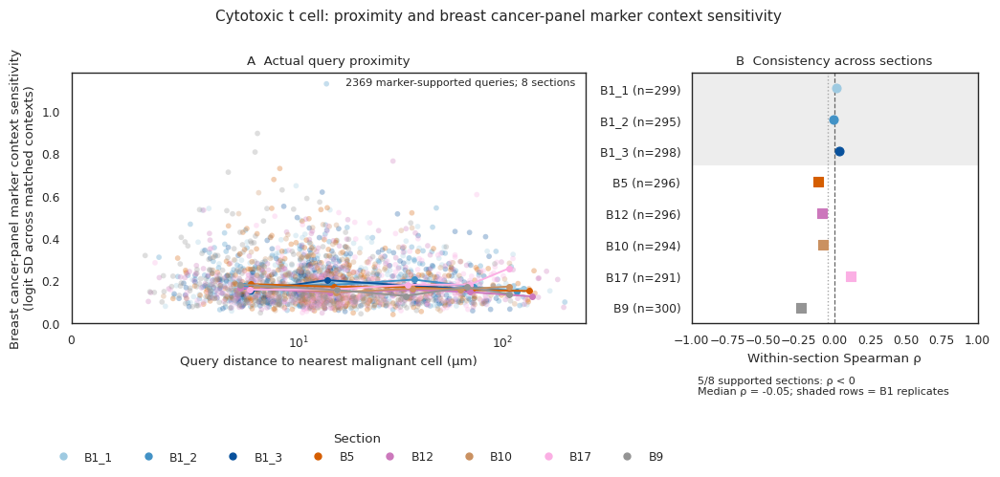

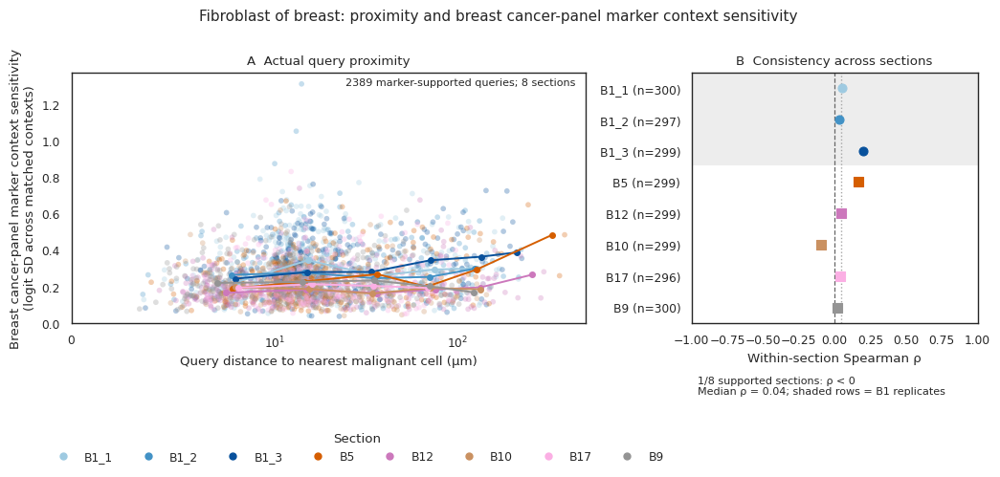

,query_cell_type,status,n_marker_supported_queries,n_supported_sections,n_negative_sections,median_rho,png,pdf
0,"CD4-positive, alpha-beta memory T cell",ok,2354,8,7,-0.123306,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
1,cytotoxic T cell,ok,2369,8,5,-0.045836,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
2,natural T-regulatory cell,ok,2368,8,5,-0.021204,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
3,natural killer cell,ok,2325,8,8,-0.143526,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
4,plasma cell,ok,2366,8,8,-0.117059,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
5,classical monocyte,ok,2374,8,6,-0.032186,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
6,macrophage,ok,2387,8,8,-0.207842,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
7,mast cell,ok,2382,8,6,-0.106961,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
8,plasmacytoid dendritic cell,ok,2375,8,8,-0.127950,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...
9,capillary endothelial cell,ok,2387,8,2,0.021966,/home/jwinchel/Syndri/context_analysis/results...,/home/jwinchel/Syndri/context_analysis/results...


In [22]:
from focused_proximity import focused_panel, export_focused
FOCUSED_QUERY_TYPES = TYPE_ORDER
DISPLAY_FOCUSED_PANELS = ['fibroblast of breast','cytotoxic T cell']
all_focused_rows = []
for query_type in FOCUSED_QUERY_TYPES:
    result = focused_panel(query_type, query_distance_responses, query_distance_correlations,
        SLICE_ORDER, SLICE_LABELS, SLICE_PALETTE, marker_label="Breast cancer-panel marker")
    focused_fig, focused_data, focused_bin_data, focused_rho_data, audit = result
    row = dict(query_cell_type=query_type, **audit)
    if focused_fig is not None:
        stem = export_focused(focused_fig, focused_data, focused_bin_data, focused_rho_data,
                               FIGURES/'focused_all_types', query_type)
        row.update(png=str(stem)+'.png',pdf=str(stem)+'.pdf')
        if query_type in DISPLAY_FOCUSED_PANELS:
            plt.figure(focused_fig.number);plt.show()
        else:
            plt.close(focused_fig)
    all_focused_rows.append(row)
all_focused_summary = pd.DataFrame(all_focused_rows)
all_focused_summary.to_csv(FIGURES/'focused_all_types'/'all_types_summary.csv',index=False)
display(all_focused_summary)


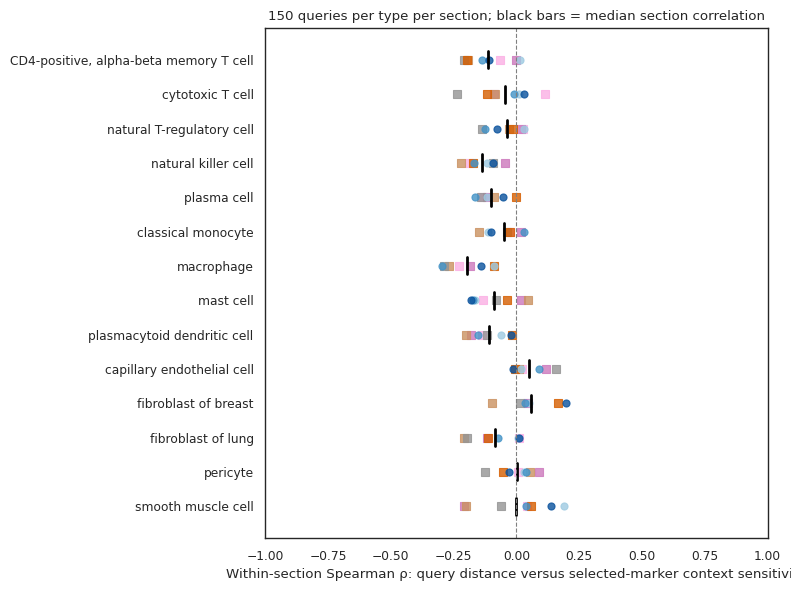

In [23]:
fig,ax=plt.subplots(figsize=(8,6))
all_rho=query_distance_correlations.loc[query_distance_correlations.metric.eq('malignant_marker_score_sd')]
for y,query_type in enumerate(TYPE_ORDER):
    part=all_rho.loc[all_rho.query_cell_type.eq(query_type)&all_rho.status.eq('ok')]
    for _,row in part.iterrows():
        label=SLICE_LABELS[row['slice']]
        ax.scatter(row.spearman_rho,y,color=SLICE_PALETTE[row['slice']],
                   marker='o' if label.startswith('B1_') else 's',s=26,alpha=.8)
    if not part.empty:
        ax.plot([part.spearman_rho.mean()]*2,[y-.25,y+.25],color='black',linewidth=2)
ax.axvline(0,color='0.5',linestyle='--',linewidth=.8)
ax.set_yticks(range(len(TYPE_ORDER)),TYPE_ORDER);ax.invert_yaxis();ax.set_xlim(-1,1)
ax.set(xlabel='Within-section Spearman ρ: query distance versus selected-marker context sensitivity',
       ylabel='',title='150 queries per type per section; black bars = median section correlation')
fig.tight_layout();save_numbered(fig,'all_types_focused_correlation_overview');plt.show()


## Proximity and malignant exposure: paired panels with forest summary

Columns follow **`PANEL_QUERY_TYPES` in the configuration cell**, in left-to-right order. Top row: actual query distance to the nearest annotated malignant-cell centroid (µm). Bottom row: **malignant cells / total cells within ≤15 µm**, excluding the query itself. All finite-coordinate cells contribute to the denominator, without a transcript-count or annotation filter. Queries with no neighbors have undefined fractions and are omitted from the bottom row.

Both rows show selected marker sensitivity: SD of the mean expressed marker logit across the existing 30 substituted contexts. Faint points are individual marker-supported queries. Colored lines connect section-level medians, using population quantile bins for both exposure axes, requiring at least three queries per bin. Y-axis limits are shared across all six panels; the chosen axis transformations are retained.

The forest plot retains **distance** associations for all query groups. Black dots are median within-section Spearman ρ; whiskers are the section IQR, not confidence intervals; faint gray points are individual section correlations. Counts are negative / supported sections. Negative distance correlations indicate greater sensitivity nearer malignant cells; positive fraction associations indicate greater sensitivity with greater malignant exposure. Sections require ≥10 queries and ≥3 distinct distances and responses; summaries require ≥3 supported sections. Related B1 sections remain separate sections, not independent biological replicates.

The three T-cell subtypes are pooled for section correlations; subtype differences may contribute to the association, and context donors remain subtype-specific. Marker sensitivity measures responsiveness, not prediction accuracy. Malignant queries and a separate non-malignant epithelial query class are unavailable. Figures and underlying tables are exported under a new numbered prefix.

Selected markers: ABCC11, APOBEC3B, AR, CAV1, CCND1, CDH1, CEACAM6, CENPF, CXCL12, EGFR, ERBB2, ESR1, FOXA1, GATA3, KIT, KRT7, LDHB, LRRC15, MDM2, PCLAF, PGR, PTGDS, RUNX1, S100A4, SCD, SFRP1, SNAI1, TACSTD2, TCF4, TOP2A, ZEB1, ZEB2. These are a user-specified panel, not an exclusively epithelial or tumor-specific gene set.

**Choose cell types:** edit the three entries in `PANEL_QUERY_TYPES` near the top, using `AVAILABLE_PANEL_QUERY_TYPES` for valid names. Rerun the configuration cell, the query-distance data-loading cell, and this plotting cell; then rerun any ribbon/transcript-fraction versions you want to refresh. The same three choices apply to every paired six-panel version. The forest plot continues to include all query groups.

All six panels share sensitivity y-limits from the pooled 5th–95th percentiles across the three selected cell types. Each row shares x-limits from its pooled 5th–95th exposure percentiles across those same types; distance and fraction keep separate x units. This changes display limits only; all supported queries still contribute to curves, ribbons, and correlations.

**Population bins:** `EXPOSURE_POPULATION_BINS = 6` in configuration requests six approximately equal-query bins per cell type and exposure, pooling supported queries across the selected sections. Sections share the boundaries. Identical exposure values stay together; duplicate quantile boundaries are merged, so tied values may produce fewer or unequal bins. Each section contributes one median per supported bin, and ribbons still weight sections equally. Saved `population_bin_coverage.csv` files record actual populations and observed x ranges. Correlations use the original unbinned values.


Queries without neighbors: 1795


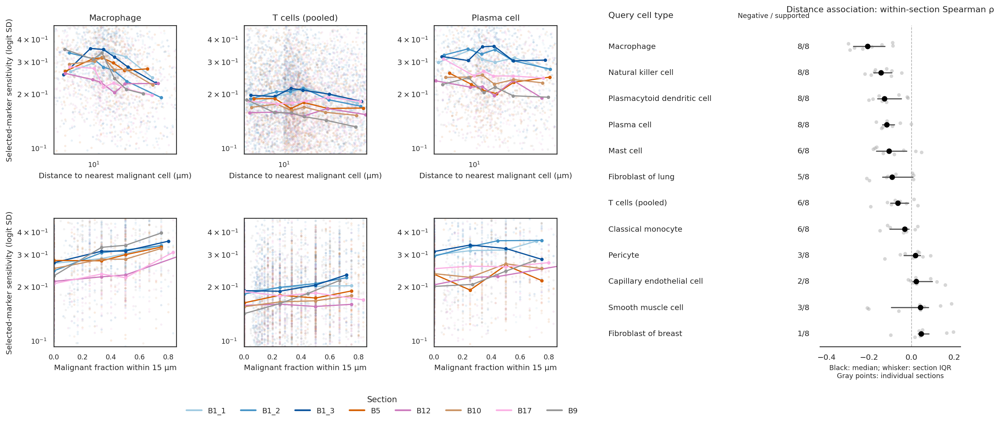

,median_rho,n_supported_sections,n_negative_sections,rho_q25,rho_q75
query_group,,,,,
T cells (pooled),-0.065001,8,6,-0.099410,-0.015207
natural killer cell,-0.143526,8,8,-0.178244,-0.094318
plasma cell,-0.117059,8,8,-0.136653,-0.080529
classical monocyte,-0.032186,8,6,-0.103535,-0.013550
macrophage,-0.207842,8,8,-0.273705,-0.126612
mast cell,-0.106961,8,6,-0.165766,-0.022683
plasmacytoid dendritic cell,-0.127950,8,8,-0.159882,-0.049573
capillary endothelial cell,0.021966,8,2,0.005894,0.097481
fibroblast of breast,0.044411,8,1,0.030754,0.080335


Figure and tables: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/representative_proximity/paired_exposure_2_


In [24]:
from scipy.stats import spearmanr
from matplotlib.lines import Line2D

PROXIMITY_MARKER_METRIC = "malignant_marker_score_sd"
PROXIMITY_T_CELL_TYPES = ["CD4-positive, alpha-beta memory T cell",
                          "cytotoxic T cell", "natural T-regulatory cell"]
PROXIMITY_REPRESENTATIVES = ["T cells (pooled)", "fibroblast of breast", "macrophage",
                            "capillary endothelial cell", "natural killer cell", "plasma cell"]
PROXIMITY_MIN_BIN_QUERIES = 3
proximity_cells = query_distance_responses.copy()
proximity_cells["query_group"] = proximity_cells["query_cell_type"].replace(
    {t: "T cells (pooled)" for t in PROXIMITY_T_CELL_TYPES})
proximity_groups = list(dict.fromkeys("T cells (pooled)" if t in PROXIMITY_T_CELL_TYPES else t
                                      for t in TYPE_ORDER))
proximity_cells = proximity_cells.loc[
    np.isfinite(proximity_cells["query_distance_um"]) &
    np.isfinite(proximity_cells[PROXIMITY_MARKER_METRIC])].copy()
proximity_cells["distance_bin"] = population_exposure_bins(proximity_cells, "query_distance_um")
proximity_bins = proximity_cells.groupby(["query_group", "slice", "distance_bin"], observed=True).agg(
    distance_um=("query_distance_um", "median"),
    sensitivity=(PROXIMITY_MARKER_METRIC, "median"),
    n_queries=("query_cell_id", "nunique")).reset_index()
proximity_bins = proximity_bins.loc[proximity_bins.n_queries >= PROXIMITY_MIN_BIN_QUERIES]
proximity_rows = []
for query_group in proximity_groups:
    for slice_id in SLICE_ORDER:
        part = proximity_cells.loc[proximity_cells.query_group.eq(query_group) & proximity_cells["slice"].eq(slice_id)]
        supported = (len(part) >= MIN_SUPPORTED_QUERIES_PER_SLICE and
                     part.query_distance_um.nunique() >= 3 and part[PROXIMITY_MARKER_METRIC].nunique() >= 3)
        rho = float(spearmanr(part.query_distance_um, part[PROXIMITY_MARKER_METRIC]).statistic) if supported else np.nan
        proximity_rows.append(dict(query_group=query_group, slice=slice_id,
            n_queries=len(part), spearman_rho=rho, status="ok" if supported else "insufficient_support"))
proximity_section_statistics = pd.DataFrame(proximity_rows)
proximity_summary = proximity_section_statistics.groupby("query_group", sort=False).agg(
    median_rho=("spearman_rho", "median"), n_supported_sections=("spearman_rho", "count"),
    n_negative_sections=("spearman_rho", lambda x: int(x.lt(0).sum()))).reindex(proximity_groups)
proximity_summary["plotted_rho"] = proximity_summary.median_rho.where(
    proximity_summary.n_supported_sections >= MIN_SLICES_PER_HEATMAP_TILE)

# Whiskers describe between-section dispersion, not a confidence interval.
proximity_quartiles = proximity_section_statistics.groupby("query_group")["spearman_rho"].quantile([0.25, 0.75]).unstack()
proximity_summary["rho_q25"] = proximity_quartiles[0.25]
proximity_summary["rho_q75"] = proximity_quartiles[0.75]
forest_summary = proximity_summary.sort_values("plotted_rho", na_position="last")
# Match the forest row order, reading scatter panels left-to-right, top-to-bottom.
ordered_representatives = [t for t in forest_summary.index if t in PROXIMITY_REPRESENTATIVES]

from matplotlib.ticker import MultipleLocator

MALIGNANT_RADIUS_UM = 15
nearby_counts_path = QUERY_RESPONSIVENESS / "query_malignant_neighbor_fraction_15um.csv"
if not nearby_counts_path.exists():
    import anndata as ad
    from scipy.spatial import cKDTree
    count_frames = []
    for entry in design["slices"]:
        source = ad.read_h5ad(entry["input"], backed="r")
        try:
            obs = source.obs.copy()
        finally:
            source.file.close()
        obs.index = obs.index.astype(str)
        coords = obs[["x_centroid", "y_centroid"]].apply(pd.to_numeric, errors="coerce")
        finite = np.isfinite(coords.to_numpy()).all(axis=1)
        tumor = finite & obs.harmony_cell_type.astype(str).eq("malignant cell").to_numpy()
        tree = cKDTree(coords.to_numpy()[tumor])
        all_cell_tree = cKDTree(coords.to_numpy()[finite])
        current = query_distance_responses.loc[
            query_distance_responses["slice"].eq(entry["slice"]),
            ["slice", "query_cell_id", "query_cell_type", "query_distance_um"]].copy()
        query_coords = coords.reindex(current.query_cell_id).to_numpy()
        if not np.isfinite(query_coords).all():
            raise ValueError("Missing query coordinates")
        current["malignant_neighbors_15um"] = tree.query_ball_point(
            query_coords, r=MALIGNANT_RADIUS_UM, return_length=True)
        current["malignant_neighbors_15um"] -= current.query_cell_type.eq("malignant cell").astype(int)
        current["total_neighbors_15um"] = all_cell_tree.query_ball_point(
            query_coords, r=MALIGNANT_RADIUS_UM, return_length=True) - 1
        current["malignant_fraction_15um"] = (
            current["malignant_neighbors_15um"] / current["total_neighbors_15um"].replace(0, np.nan))
        if not current["malignant_neighbors_15um"].le(current["total_neighbors_15um"]).all():
            raise ValueError("Malignant count exceeds total neighboring cells")
        if not np.allclose(tree.query(query_coords)[0], current.query_distance_um):
            raise ValueError("Source/query distance mismatch")
        count_frames.append(current)
    pd.concat(count_frames, ignore_index=True).to_csv(nearby_counts_path, index=False)
nearby_counts = pd.read_csv(nearby_counts_path)
nearby_sensitivity_cells = proximity_cells.merge(
    nearby_counts[["slice", "query_cell_id", "malignant_neighbors_15um",
                   "total_neighbors_15um", "malignant_fraction_15um"]],
    on=["slice", "query_cell_id"], how="left", validate="one_to_one")
if nearby_sensitivity_cells["malignant_neighbors_15um"].isna().any():
    raise ValueError("Missing 15-µm malignant-neighbor counts")
# Undefined fractions (no other cells within 15 µm) are omitted, not set to zero.
print("Queries without neighbors:", int(nearby_sensitivity_cells.total_neighbors_15um.eq(0).sum()))
nearby_sensitivity_cells = nearby_sensitivity_cells.dropna(subset=["malignant_fraction_15um"]).copy()
nearby_sensitivity_cells["fraction_bin"] = population_exposure_bins(
    nearby_sensitivity_cells, "malignant_fraction_15um")
nearby_sensitivity_bins = nearby_sensitivity_cells.groupby(
    ["query_group", "slice", "fraction_bin"], observed=True).agg(
        malignant_fraction_15um=("malignant_fraction_15um", "median"),
        sensitivity=(PROXIMITY_MARKER_METRIC, "median"),
        n_queries=("query_cell_id", "nunique")).reset_index()
nearby_sensitivity_bins = nearby_sensitivity_bins.loc[
    nearby_sensitivity_bins.n_queries >= PROXIMITY_MIN_BIN_QUERIES].copy()
if len(PANEL_QUERY_TYPES) != 3 or len(set(PANEL_QUERY_TYPES)) != 3:
    raise ValueError("Choose exactly three distinct cell types in PANEL_QUERY_TYPES (configuration cell).")
unknown_panel_types = set(PANEL_QUERY_TYPES) - set(proximity_groups)
if unknown_panel_types:
    raise ValueError(f"Unavailable panel types: {sorted(unknown_panel_types)}. Options: {proximity_groups}")
fig = plt.figure(figsize=(16, 7), dpi=160)
outer_layout = fig.add_gridspec(1, 2, width_ratios=[3, 2.1], wspace=0.12)
layout = outer_layout[0].subgridspec(2, 3, wspace=0.55, hspace=0.50)
for col, query_group in enumerate(PANEL_QUERY_TYPES):
    top_ax = None
    for row in [0, 1]:
        ax = fig.add_subplot(layout[row, col], sharey=top_ax)
        if row == 0:
            top_ax = ax
        cells = proximity_cells if row == 0 else nearby_sensitivity_cells
        bins = proximity_bins if row == 0 else nearby_sensitivity_bins
        x_col = "query_distance_um" if row == 0 else "malignant_fraction_15um"
        bin_x = "distance_um" if row == 0 else "malignant_fraction_15um"
        for slice_id in SLICE_ORDER:
            part = cells.loc[cells.query_group.eq(query_group) & cells["slice"].eq(slice_id)]
            color = SLICE_PALETTE[slice_id]
            ax.scatter(part[x_col], part[PROXIMITY_MARKER_METRIC], color=color,
                       s=7, alpha=0.12, edgecolors="none", rasterized=True)
            line = bins.loc[bins.query_group.eq(query_group) & bins["slice"].eq(slice_id)].sort_values(bin_x)
            ax.plot(line[bin_x], line.sensitivity, color=color, linewidth=1.4, marker="o", markersize=3)
        ax.set_yscale("log")
        if row == 0:
            ax.set_xscale("symlog", linthresh=10)
            ax.set_xlim(left=0)
            ax.set_title(query_group.capitalize(), fontsize=10)
            ax.set_xlabel("Distance to nearest malignant cell (µm)", fontsize=9)
        else:
            ax.set_xlim(-0.02, 1.02)
            ax.xaxis.set_major_locator(MultipleLocator(0.2))
            ax.set_xlabel("Malignant fraction within 15 µm", fontsize=9)
        ax.set_ylabel("Selected-marker sensitivity (logit SD)" if col == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        set_sensitivity_display_range(ax, proximity_cells.loc[
            proximity_cells.query_group.isin(PANEL_QUERY_TYPES), PROXIMITY_MARKER_METRIC])
        set_shared_exposure_display_range(ax, cells, x_col)

forest_layout = outer_layout[1].subgridspec(1, 2, width_ratios=[1.45, 1], wspace=0.05)
ax_forest_labels = fig.add_subplot(forest_layout[0])
ax_summary = fig.add_subplot(forest_layout[1], sharey=ax_forest_labels)
for y, (query_group, row) in enumerate(forest_summary.iterrows()):
    ax_forest_labels.text(0, y, query_group.capitalize(), va="center", fontsize=9)
    ax_forest_labels.text(0.99, y,
        f"{int(row.n_negative_sections)}/{int(row.n_supported_sections)}",
        ha="right", va="center", fontsize=9)
    # Stable vertical offsets separate section estimates without moving their rho values.
    section_values = proximity_section_statistics.loc[
        proximity_section_statistics.query_group.eq(query_group)
    ].set_index("slice").reindex(SLICE_ORDER)["spearman_rho"].dropna()
    section_offsets = np.linspace(-0.14, 0.14, len(section_values))
    ax_summary.scatter(section_values.to_numpy(), y + section_offsets,
                       color="0.65", alpha=0.45, s=18, edgecolors="none", zorder=1)
    if pd.notna(row.plotted_rho):
        ax_summary.plot([row.rho_q25, row.rho_q75], [y, y], color="0.35", linewidth=1.4)
        ax_summary.scatter(row.plotted_rho, y, color="black", s=32, zorder=3)
    else:
        ax_summary.text(0, y, "Insufficient support", va="center", ha="center", fontsize=7, color="0.5")
ax_forest_labels.set_xlim(0, 1)
ax_forest_labels.set_ylim(len(forest_summary) - 0.5, -0.8)
ax_forest_labels.axis("off")
ax_forest_labels.text(0, 1.025, "Query cell type", transform=ax_forest_labels.transAxes, fontsize=10)
ax_forest_labels.text(0.99, 1.025, "Negative / supported", ha="right",
                     transform=ax_forest_labels.transAxes, fontsize=8)
ax_summary.axvline(0, color="0.7", linestyle="--", linewidth=0.8, zorder=0)
forest_low = np.floor(min(-0.1, proximity_section_statistics.spearman_rho.min()) * 5) / 5
forest_high = max(0.1, np.ceil(proximity_section_statistics.spearman_rho.max() * 10) / 10)
ax_summary.set_xlim(forest_low - 0.03, forest_high + 0.03)
ax_summary.tick_params(axis="y", left=False, labelleft=False)
for spine in ["left", "right", "top"]:
    ax_summary.spines[spine].set_visible(False)
ax_summary.set_title("Distance association: within-section Spearman ρ", fontsize=10, pad=16)
ax_summary.set_xlabel("Black: median; whisker: section IQR\nGray points: individual sections", fontsize=8)
ax_summary.tick_params(axis="x", labelsize=9)
fig.legend(handles=[Line2D([0], [0], color=SLICE_PALETTE[s], linewidth=2, label=SLICE_LABELS[s])
                   for s in SLICE_ORDER], loc="lower center", bbox_to_anchor=(0.39, -0.015), ncol=8, frameon=False, title="Section")
fig.subplots_adjust(left=0.055, right=0.98, bottom=0.16, top=0.91)

export_index = 1
proximity_output = FIGURES / "representative_proximity"
proximity_output.mkdir(exist_ok=True)
while list(proximity_output.glob(f"paired_exposure_{export_index}_*")):
    export_index += 1
proximity_prefix = proximity_output / f"paired_exposure_{export_index}_"
fig.savefig(str(proximity_prefix) + "figure.png", dpi=300, bbox_inches="tight")
fig.savefig(str(proximity_prefix) + "figure.pdf", bbox_inches="tight")
proximity_cells.to_csv(str(proximity_prefix) + "cells.csv", index=False)
proximity_bins.to_csv(str(proximity_prefix) + "bins.csv", index=False)
proximity_section_statistics.to_csv(str(proximity_prefix) + "section_correlations.csv", index=False)
proximity_summary.to_csv(str(proximity_prefix) + "summary.csv")
nearby_sensitivity_cells.to_csv(str(proximity_prefix) + "fraction_cells.csv", index=False)
nearby_sensitivity_bins.to_csv(str(proximity_prefix) + "fraction_bins.csv", index=False)
pd.concat(population_bin_coverage.values(), ignore_index=True).to_csv(
    str(proximity_prefix) + "population_bin_coverage.csv", index=False)
plt.show()
display(proximity_summary.drop(columns="plotted_rho"))
print("Figure and tables:", proximity_prefix)


## Alternative: section-median curves with IQR ribbons

Same three cell types, two exposure definitions, and distance-association forest plot as above. For each x-axis bin, first take the existing median sensitivity within each section (≥3 supported queries), then give sections equal weight: the center line is the **median of section medians**, and the ribbon spans their **25th–75th percentiles**. X positions are median section-level x values within each common bin. At least three sections must support a bin; unsupported bins remain gaps. Faint gray points show individual queries. The ribbon describes between-section variability, **not a confidence interval**, and related B1 replicates remain separate sections. Aggregation is on the original sensitivity scale; the y-axis is displayed on a log scale. Per-bin section counts are saved in `ribbon_summary` and the exported CSV. The original section-colored figure is retained above.

All six panels share sensitivity y-limits from the pooled 5th–95th percentiles across the three selected cell types. Each row shares x-limits from its pooled 5th–95th exposure percentiles across those same types; distance and fraction keep separate x units. This changes display limits only; all supported queries still contribute to curves, ribbons, and correlations.

**Population bins:** `EXPOSURE_POPULATION_BINS = 6` in configuration requests six approximately equal-query bins per cell type and exposure, pooling supported queries across the selected sections. Sections share the boundaries. Identical exposure values stay together; duplicate quantile boundaries are merged, so tied values may produce fewer or unequal bins. Each section contributes one median per supported bin, and ribbons still weight sections equally. Saved `population_bin_coverage.csv` files record actual populations and observed x ranges. Correlations use the original unbinned values.


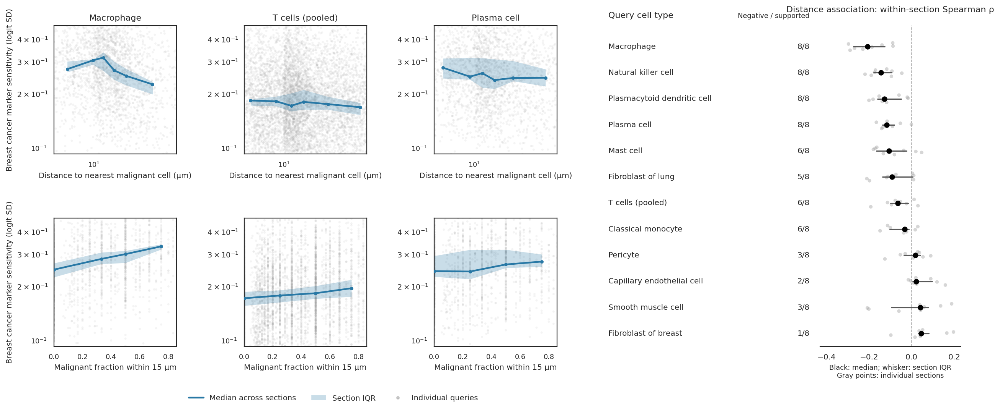

Ribbon figure and section-balanced bin summaries: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/representative_proximity/paired_exposure_ribbon_2_


In [25]:
from matplotlib.patches import Patch

RIBBON_MIN_SECTIONS = 3
ribbon_tables = []
for exposure, bins, bin_col, x_col in [
    ("distance", proximity_bins, "distance_bin", "distance_um"),
    ("fraction", nearby_sensitivity_bins, "fraction_bin", "malignant_fraction_15um"),
]:
    # Each input row is one section's median sensitivity in a common x bin.
    summary = bins.groupby(["query_group", bin_col], observed=True).agg(
        x=(x_col, "median"), sensitivity_median=("sensitivity", "median"),
        sensitivity_q25=("sensitivity", lambda x: x.quantile(0.25)),
        sensitivity_q75=("sensitivity", lambda x: x.quantile(0.75)),
        n_sections=("slice", "nunique")).reset_index()
    summary["exposure_bin"] = summary[bin_col].astype(str)
    summary["exposure"] = exposure
    ribbon_tables.append(summary.drop(columns=bin_col))
ribbon_summary = pd.concat(ribbon_tables, ignore_index=True)
fig = plt.figure(figsize=(16, 7), dpi=160)
outer_layout = fig.add_gridspec(1, 2, width_ratios=[3, 2.1], wspace=0.12)
layout = outer_layout[0].subgridspec(2, 3, wspace=0.55, hspace=0.50)
ribbon_color = "#2878a5"
for col, query_group in enumerate(PANEL_QUERY_TYPES):
    top_ax = None
    for row, exposure in enumerate(["distance", "fraction"]):
        ax = fig.add_subplot(layout[row, col], sharey=top_ax)
        if row == 0:
            top_ax = ax
        cells = proximity_cells if row == 0 else nearby_sensitivity_cells
        x_col = "query_distance_um" if row == 0 else "malignant_fraction_15um"
        points = cells.loc[cells.query_group.eq(query_group)]
        ax.scatter(points[x_col], points[PROXIMITY_MARKER_METRIC], color="0.6",
                   s=7, alpha=0.10, edgecolors="none", rasterized=True, zorder=1)
        line = ribbon_summary.loc[ribbon_summary.query_group.eq(query_group) &
                                  ribbon_summary.exposure.eq(exposure)].sort_values("x")
        supported = line.n_sections >= RIBBON_MIN_SECTIONS
        # NaNs leave gaps at bins without enough sections.
        median = line.sensitivity_median.where(supported).to_numpy(dtype=float)
        lower = line.sensitivity_q25.where(supported).to_numpy(dtype=float)
        upper = line.sensitivity_q75.where(supported).to_numpy(dtype=float)
        ax.fill_between(line.x.to_numpy(dtype=float), lower, upper,
                        color=ribbon_color, alpha=0.25, linewidth=0, zorder=2)
        ax.plot(line.x, median, color=ribbon_color, linewidth=2, marker="o", markersize=3, zorder=3)
        ax.set_yscale("log")
        if row == 0:
            ax.set_xscale("symlog", linthresh=10)
            ax.set_xlim(left=0)
            ax.set_title(query_group.capitalize(), fontsize=10)
            ax.set_xlabel("Distance to nearest malignant cell (µm)", fontsize=9)
        else:
            ax.set_xlim(-0.02, 1.02)
            ax.xaxis.set_major_locator(MultipleLocator(0.2))
            ax.set_xlabel("Malignant fraction within 15 µm", fontsize=9)
        ax.set_ylabel("Breast cancer marker sensitivity (logit SD)" if col == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        set_sensitivity_display_range(ax, proximity_cells.loc[
            proximity_cells.query_group.isin(PANEL_QUERY_TYPES), PROXIMITY_MARKER_METRIC])
        set_shared_exposure_display_range(ax, cells, x_col)

forest_layout = outer_layout[1].subgridspec(1, 2, width_ratios=[1.45, 1], wspace=0.05)
ax_forest_labels = fig.add_subplot(forest_layout[0])
ax_summary = fig.add_subplot(forest_layout[1], sharey=ax_forest_labels)
for y, (query_group, row) in enumerate(forest_summary.iterrows()):
    ax_forest_labels.text(0, y, query_group.capitalize(), va="center", fontsize=9)
    ax_forest_labels.text(0.99, y,
        f"{int(row.n_negative_sections)}/{int(row.n_supported_sections)}",
        ha="right", va="center", fontsize=9)
    # Stable vertical offsets separate section estimates without moving their rho values.
    section_values = proximity_section_statistics.loc[
        proximity_section_statistics.query_group.eq(query_group)
    ].set_index("slice").reindex(SLICE_ORDER)["spearman_rho"].dropna()
    section_offsets = np.linspace(-0.14, 0.14, len(section_values))
    ax_summary.scatter(section_values.to_numpy(), y + section_offsets,
                       color="0.65", alpha=0.45, s=18, edgecolors="none", zorder=1)
    if pd.notna(row.plotted_rho):
        ax_summary.plot([row.rho_q25, row.rho_q75], [y, y], color="0.35", linewidth=1.4)
        ax_summary.scatter(row.plotted_rho, y, color="black", s=32, zorder=3)
    else:
        ax_summary.text(0, y, "Insufficient support", va="center", ha="center", fontsize=7, color="0.5")
ax_forest_labels.set_xlim(0, 1)
ax_forest_labels.set_ylim(len(forest_summary) - 0.5, -0.8)
ax_forest_labels.axis("off")
ax_forest_labels.text(0, 1.025, "Query cell type", transform=ax_forest_labels.transAxes, fontsize=10)
ax_forest_labels.text(0.99, 1.025, "Negative / supported", ha="right",
                     transform=ax_forest_labels.transAxes, fontsize=8)
ax_summary.axvline(0, color="0.7", linestyle="--", linewidth=0.8, zorder=0)
forest_low = np.floor(min(-0.1, proximity_section_statistics.spearman_rho.min()) * 5) / 5
forest_high = max(0.1, np.ceil(proximity_section_statistics.spearman_rho.max() * 10) / 10)
ax_summary.set_xlim(forest_low - 0.03, forest_high + 0.03)
ax_summary.tick_params(axis="y", left=False, labelleft=False)
for spine in ["left", "right", "top"]:
    ax_summary.spines[spine].set_visible(False)
ax_summary.set_title("Distance association: within-section Spearman ρ", fontsize=10, pad=16)
ax_summary.set_xlabel("Black: median; whisker: section IQR\nGray points: individual sections", fontsize=8)
ax_summary.tick_params(axis="x", labelsize=9)
fig.legend(handles=[
    Line2D([0], [0], color=ribbon_color, linewidth=2, label="Median across sections"),
    Patch(facecolor=ribbon_color, alpha=0.25, label="Section IQR"),
    Line2D([0], [0], marker="o", linestyle="", color="0.6", alpha=0.5, markersize=3, label="Individual queries"),
], loc="lower center", bbox_to_anchor=(0.34, 0.015), ncol=3, frameon=False)
fig.subplots_adjust(left=0.055, right=0.98, bottom=0.16, top=0.91)
ribbon_index = 1
while list(proximity_output.glob(f"paired_exposure_ribbon_{ribbon_index}_*")):
    ribbon_index += 1
ribbon_prefix = proximity_output / f"paired_exposure_ribbon_{ribbon_index}_"
fig.savefig(str(ribbon_prefix) + "figure.png", dpi=300, bbox_inches="tight")
fig.savefig(str(ribbon_prefix) + "figure.pdf", bbox_inches="tight")
ribbon_summary.to_csv(str(ribbon_prefix) + "bin_summary.csv", index=False)
pd.concat(population_bin_coverage.values(), ignore_index=True).to_csv(
    str(ribbon_prefix) + "population_bin_coverage.csv", index=False)
plt.show()
print("Ribbon figure and section-balanced bin summaries:", ribbon_prefix)


## Alternative: neighborhood marker-transcript fraction

Same three query types and median/IQR ribbon layout. The **bottom-row x-axis** is the sum of raw transcripts for the specified 32-gene panel divided by the sum of **all measured-gene transcripts** in neighboring cells within ≤15 µm of the query centroid, excluding the query itself. Neighboring cells contribute regardless of annotation or count QC. This pools transcripts before taking the ratio, rather than averaging per-cell fractions. It counts all transcripts assigned to qualifying neighboring cells; it is not a circle drawn around individual transcript coordinates. The numerator includes marker expression in all neighboring cell types, not only cells annotated malignant. These selected genes are not exclusively malignant markers.

The response remains the SD of the mean expressed selected-marker logit across substituted contexts. Bottom-row section medians use population quantile transcript-fraction bins (≥3 queries per section/bin). Center curves are medians across section medians; ribbons are the section IQR, with ≥3 supporting sections, as above. Queries with no neighborhood transcripts are excluded. The **top row and forest plot retain the distance analysis**. The 32-gene list, raw matrix sources, radius, marker coverage, numerator, denominator, and fraction are retained with the output tables.

All six panels share sensitivity y-limits from the pooled 5th–95th percentiles across the three selected cell types. Each row shares x-limits from its pooled 5th–95th exposure percentiles across those same types; distance and fraction keep separate x units. This changes display limits only; all supported queries still contribute to curves, ribbons, and correlations.

**Population bins:** `EXPOSURE_POPULATION_BINS = 6` in configuration requests six approximately equal-query bins per cell type and exposure, pooling supported queries across the selected sections. Sections share the boundaries. Identical exposure values stay together; duplicate quantile boundaries are merged, so tied values may produce fewer or unequal bins. Each section contributes one median per supported bin, and ribbons still weight sections equally. Saved `population_bin_coverage.csv` files record actual populations and observed x ranges. Correlations use the original unbinned values.


Marker-supported queries without neighborhood transcripts: 1795


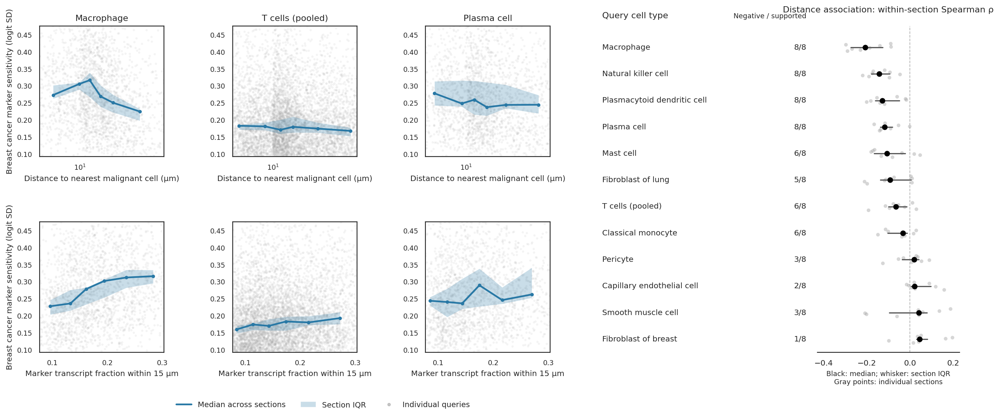

Ribbon figure and section-balanced bin summaries: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/representative_proximity/transcript_exposure_ribbon_2_


In [26]:
# Raw assigned transcripts from neighboring cells whose centroids are within 15 µm.
import anndata as ad
from scipy import sparse
from scipy.spatial import cKDTree

TRANSCRIPT_RADIUS_UM = 15
transcript_fraction_path = QUERY_RESPONSIVENESS / "query_selected_marker_transcript_fraction_15um.csv"
transcript_fraction_metadata = transcript_fraction_path.with_suffix(".json")
expected_transcript_metadata = dict(marker_genes=SELECTED_RESPONSE_MARKERS, radius_um=TRANSCRIPT_RADIUS_UM,
    counts="raw source X", neighborhood="cell centroids within radius, excluding query")
if transcript_fraction_path.exists():
    if not transcript_fraction_metadata.exists() or json.loads(transcript_fraction_metadata.read_text()) != expected_transcript_metadata:
        raise ValueError("Cached transcript fraction uses a different definition")
else:
    transcript_rows = []
    transcript_coverage = []
    for entry in design["slices"]:
        source = ad.read_h5ad(entry["input"], backed="r")
        try:
            obs = source.obs.copy()
            names = source.var.get("feature_name", pd.Series(source.var_names, index=source.var_names)).fillna("").astype(str).to_numpy()
            names = np.where(names == "", source.var_names.astype(str), names)
            marker_mask = np.isin(names, SELECTED_RESPONSE_MARKERS)
            counts = source.X.to_memory() if hasattr(source.X, "to_memory") else source.X[:]
            if sparse.issparse(counts):
                total_per_cell = np.asarray(counts.sum(axis=1)).ravel().astype(float)
                marker_per_cell = np.asarray(counts[:, marker_mask].sum(axis=1)).ravel().astype(float)
            else:
                total_per_cell = np.asarray(counts).sum(axis=1).astype(float)
                marker_per_cell = np.asarray(counts)[:, marker_mask].sum(axis=1).astype(float)
            del counts
        finally:
            source.file.close()
        if (total_per_cell < 0).any() or (marker_per_cell > total_per_cell).any():
            raise ValueError("Invalid raw transcript totals")
        transcript_coverage.append(dict(slice=entry["slice"], n_panel_genes=len(names),
            n_requested_markers=len(SELECTED_RESPONSE_MARKERS), n_present_markers=int(marker_mask.sum()),
            missing_markers=", ".join(g for g in SELECTED_RESPONSE_MARKERS if g not in set(names))))
        obs.index = obs.index.astype(str)
        if not obs.index.is_unique:
            raise ValueError("Duplicate source cell IDs")
        coords = obs[["x_centroid", "y_centroid"]].apply(pd.to_numeric, errors="coerce").to_numpy()
        finite_positions = np.flatnonzero(np.isfinite(coords).all(axis=1))
        tree = cKDTree(coords[finite_positions])
        queries = query_distance_responses.loc[query_distance_responses["slice"].eq(entry["slice"])]
        query_positions = obs.index.get_indexer(queries.query_cell_id)
        if (query_positions < 0).any() or not np.isfinite(coords[query_positions]).all():
            raise ValueError("Missing query source coordinates")
        neighborhoods = tree.query_ball_point(coords[query_positions], r=TRANSCRIPT_RADIUS_UM)
        for (_, query), position, neighbors in zip(queries.iterrows(), query_positions, neighborhoods):
            positions = finite_positions[np.asarray(neighbors, dtype=int)]
            positions = positions[positions != position]
            total = float(total_per_cell[positions].sum())
            marker = float(marker_per_cell[positions].sum())
            transcript_rows.append(dict(slice=entry["slice"], query_cell_id=query.query_cell_id,
                neighborhood_cells=len(positions), neighborhood_total_transcripts=total,
                neighborhood_marker_transcripts=marker,
                marker_transcript_fraction_15um=marker / total if total > 0 else np.nan))
        print("Transcript fractions:", entry["label"], len(queries), flush=True)
    pd.DataFrame(transcript_rows).to_csv(transcript_fraction_path, index=False)
    pd.DataFrame(transcript_coverage).to_csv(transcript_fraction_path.with_name("transcript_fraction_marker_coverage.csv"), index=False)
    transcript_fraction_metadata.write_text(json.dumps(expected_transcript_metadata, indent=2) + "\n")
transcript_exposure_cells = proximity_cells.merge(pd.read_csv(transcript_fraction_path),
    on=["slice", "query_cell_id"], how="left", validate="one_to_one")
if transcript_exposure_cells.neighborhood_total_transcripts.isna().any():
    raise ValueError("Missing neighborhood transcript totals")
print("Marker-supported queries without neighborhood transcripts:",
      int(transcript_exposure_cells.marker_transcript_fraction_15um.isna().sum()))
transcript_exposure_cells = transcript_exposure_cells.dropna(subset=["marker_transcript_fraction_15um"]).copy()
transcript_exposure_cells["transcript_fraction_bin"] = population_exposure_bins(
    transcript_exposure_cells, "marker_transcript_fraction_15um")
transcript_exposure_bins = transcript_exposure_cells.groupby(
    ["query_group", "slice", "transcript_fraction_bin"], observed=True).agg(
        marker_transcript_fraction_15um=("marker_transcript_fraction_15um", "median"),
        sensitivity=(PROXIMITY_MARKER_METRIC, "median"), n_queries=("query_cell_id", "nunique")).reset_index()
transcript_exposure_bins = transcript_exposure_bins.loc[
    transcript_exposure_bins.n_queries >= PROXIMITY_MIN_BIN_QUERIES].copy()

from matplotlib.patches import Patch

RIBBON_MIN_SECTIONS = 3
ribbon_tables = []
for exposure, bins, bin_col, x_col in [
    ("distance", proximity_bins, "distance_bin", "distance_um"),
    ("fraction", transcript_exposure_bins, "transcript_fraction_bin", "marker_transcript_fraction_15um"),
]:
    # Each input row is one section's median sensitivity in a common x bin.
    summary = bins.groupby(["query_group", bin_col], observed=True).agg(
        x=(x_col, "median"), sensitivity_median=("sensitivity", "median"),
        sensitivity_q25=("sensitivity", lambda x: x.quantile(0.25)),
        sensitivity_q75=("sensitivity", lambda x: x.quantile(0.75)),
        n_sections=("slice", "nunique")).reset_index()
    summary["exposure_bin"] = summary[bin_col].astype(str)
    summary["exposure"] = exposure
    ribbon_tables.append(summary.drop(columns=bin_col))
ribbon_summary = pd.concat(ribbon_tables, ignore_index=True)
transcript_plot_max = max(0.1, np.ceil(transcript_exposure_cells.loc[
    transcript_exposure_cells.query_group.isin(PANEL_QUERY_TYPES),
    "marker_transcript_fraction_15um"].max() * 10) / 10)
fig = plt.figure(figsize=(16, 7), dpi=160)
outer_layout = fig.add_gridspec(1, 2, width_ratios=[3, 2.1], wspace=0.12)
layout = outer_layout[0].subgridspec(2, 3, wspace=0.55, hspace=0.50)
ribbon_color = "#2878a5"
for col, query_group in enumerate(PANEL_QUERY_TYPES):
    top_ax = None
    for row, exposure in enumerate(["distance", "fraction"]):
        ax = fig.add_subplot(layout[row, col], sharey=top_ax)
        if row == 0:
            top_ax = ax
        cells = proximity_cells if row == 0 else transcript_exposure_cells
        x_col = "query_distance_um" if row == 0 else "marker_transcript_fraction_15um"
        points = cells.loc[cells.query_group.eq(query_group)]
        ax.scatter(points[x_col], points[PROXIMITY_MARKER_METRIC], color="0.6",
                   s=7, alpha=0.10, edgecolors="none", rasterized=True, zorder=1)
        line = ribbon_summary.loc[ribbon_summary.query_group.eq(query_group) &
                                  ribbon_summary.exposure.eq(exposure)].sort_values("x")
        supported = line.n_sections >= RIBBON_MIN_SECTIONS
        # NaNs leave gaps at bins without enough sections.
        median = line.sensitivity_median.where(supported).to_numpy(dtype=float)
        lower = line.sensitivity_q25.where(supported).to_numpy(dtype=float)
        upper = line.sensitivity_q75.where(supported).to_numpy(dtype=float)
        ax.fill_between(line.x.to_numpy(dtype=float), lower, upper,
                        color=ribbon_color, alpha=0.25, linewidth=0, zorder=2)
        ax.plot(line.x, median, color=ribbon_color, linewidth=2, marker="o", markersize=3, zorder=3)
        # ax.set_yscale("log")
        if row == 0:
            ax.set_xscale("symlog", linthresh=10)
            ax.set_xlim(left=0)
            ax.set_title(query_group.capitalize(), fontsize=10)
            ax.set_xlabel("Distance to nearest malignant cell (µm)", fontsize=9)
        else:
            ax.set_xlim(-0.01, min(1.01, transcript_plot_max + 0.01))
            ax.xaxis.set_major_locator(MultipleLocator(0.1))
            ax.set_xlabel("Marker transcript fraction within 15 µm", fontsize=9)
        ax.set_ylabel("Breast cancer marker sensitivity (logit SD)" if col == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        set_sensitivity_display_range(ax, proximity_cells.loc[
            proximity_cells.query_group.isin(PANEL_QUERY_TYPES), PROXIMITY_MARKER_METRIC])
        set_shared_exposure_display_range(ax, cells, x_col)

forest_layout = outer_layout[1].subgridspec(1, 2, width_ratios=[1.45, 1], wspace=0.05)
ax_forest_labels = fig.add_subplot(forest_layout[0])
ax_summary = fig.add_subplot(forest_layout[1], sharey=ax_forest_labels)
for y, (query_group, row) in enumerate(forest_summary.iterrows()):
    ax_forest_labels.text(0, y, query_group.capitalize(), va="center", fontsize=9)
    ax_forest_labels.text(0.99, y,
        f"{int(row.n_negative_sections)}/{int(row.n_supported_sections)}",
        ha="right", va="center", fontsize=9)
    # Stable vertical offsets separate section estimates without moving their rho values.
    section_values = proximity_section_statistics.loc[
        proximity_section_statistics.query_group.eq(query_group)
    ].set_index("slice").reindex(SLICE_ORDER)["spearman_rho"].dropna()
    section_offsets = np.linspace(-0.14, 0.14, len(section_values))
    ax_summary.scatter(section_values.to_numpy(), y + section_offsets,
                       color="0.65", alpha=0.45, s=18, edgecolors="none", zorder=1)
    if pd.notna(row.plotted_rho):
        ax_summary.plot([row.rho_q25, row.rho_q75], [y, y], color="0.35", linewidth=1.4)
        ax_summary.scatter(row.plotted_rho, y, color="black", s=32, zorder=3)
    else:
        ax_summary.text(0, y, "Insufficient support", va="center", ha="center", fontsize=7, color="0.5")
ax_forest_labels.set_xlim(0, 1)
ax_forest_labels.set_ylim(len(forest_summary) - 0.5, -0.8)
ax_forest_labels.axis("off")
ax_forest_labels.text(0, 1.025, "Query cell type", transform=ax_forest_labels.transAxes, fontsize=10)
ax_forest_labels.text(0.99, 1.025, "Negative / supported", ha="right",
                     transform=ax_forest_labels.transAxes, fontsize=8)
ax_summary.axvline(0, color="0.7", linestyle="--", linewidth=0.8, zorder=0)
forest_low = np.floor(min(-0.1, proximity_section_statistics.spearman_rho.min()) * 5) / 5
forest_high = max(0.1, np.ceil(proximity_section_statistics.spearman_rho.max() * 10) / 10)
ax_summary.set_xlim(forest_low - 0.03, forest_high + 0.03)
ax_summary.tick_params(axis="y", left=False, labelleft=False)
for spine in ["left", "right", "top"]:
    ax_summary.spines[spine].set_visible(False)
ax_summary.set_title("Distance association: within-section Spearman ρ", fontsize=10, pad=16)
ax_summary.set_xlabel("Black: median; whisker: section IQR\nGray points: individual sections", fontsize=8)
ax_summary.tick_params(axis="x", labelsize=9)
fig.legend(handles=[
    Line2D([0], [0], color=ribbon_color, linewidth=2, label="Median across sections"),
    Patch(facecolor=ribbon_color, alpha=0.25, label="Section IQR"),
    Line2D([0], [0], marker="o", linestyle="", color="0.6", alpha=0.5, markersize=3, label="Individual queries"),
], loc="lower center", bbox_to_anchor=(0.34, 0.015), ncol=3, frameon=False)
fig.subplots_adjust(left=0.055, right=0.98, bottom=0.16, top=0.91)
ribbon_index = 1
while list(proximity_output.glob(f"transcript_exposure_ribbon_{ribbon_index}_*")):
    ribbon_index += 1
ribbon_prefix = proximity_output / f"transcript_exposure_ribbon_{ribbon_index}_"
fig.savefig(str(ribbon_prefix) + "figure.png", dpi=300, bbox_inches="tight")
fig.savefig(str(ribbon_prefix) + "figure.pdf", bbox_inches="tight")
ribbon_summary.to_csv(str(ribbon_prefix) + "bin_summary.csv", index=False)
transcript_exposure_cells.to_csv(str(ribbon_prefix) + "cells.csv", index=False)
transcript_exposure_bins.to_csv(str(ribbon_prefix) + "section_bins.csv", index=False)
pd.concat(population_bin_coverage.values(), ignore_index=True).to_csv(
    str(ribbon_prefix) + "population_bin_coverage.csv", index=False)
plt.show()
print("Ribbon figure and section-balanced bin summaries:", ribbon_prefix)


## Alternative: neighborhood marker-transcript fraction within 20 µm

Same three query types and median/IQR ribbon layout. The **bottom-row x-axis** is the sum of raw transcripts for the specified 32-gene panel divided by the sum of **all measured-gene transcripts** in neighboring cells within ≤20 µm of the query centroid, excluding the query itself. Neighboring cells contribute regardless of annotation or count QC. This pools transcripts before taking the ratio, rather than averaging per-cell fractions. It counts all transcripts assigned to qualifying neighboring cells; it is not a circle drawn around individual transcript coordinates. The numerator includes marker expression in all neighboring cell types, not only cells annotated malignant. These selected genes are not exclusively malignant markers.

The response remains the SD of the mean expressed selected-marker logit across substituted contexts. Bottom-row section medians use population quantile transcript-fraction bins (≥3 queries per section/bin). Center curves are medians across section medians; ribbons are the section IQR, with ≥3 supporting sections, as above. Queries with no neighborhood transcripts are excluded. The **top row and forest plot retain the distance analysis**. The 32-gene list, raw matrix sources, radius, marker coverage, numerator, denominator, and fraction are retained with the output tables.

This is an additional 20-µm version; the 15-µm analysis is retained above. Only the bottom-row neighborhood transcript fraction changes.

All six panels share sensitivity y-limits from the pooled 5th–95th percentiles across the three selected cell types. Each row shares x-limits from its pooled 5th–95th exposure percentiles across those same types; distance and fraction keep separate x units. This changes display limits only; all supported queries still contribute to curves, ribbons, and correlations.

**Population bins:** `EXPOSURE_POPULATION_BINS = 6` in configuration requests six approximately equal-query bins per cell type and exposure, pooling supported queries across the selected sections. Sections share the boundaries. Identical exposure values stay together; duplicate quantile boundaries are merged, so tied values may produce fewer or unequal bins. Each section contributes one median per supported bin, and ribbons still weight sections equally. Saved `population_bin_coverage.csv` files record actual populations and observed x ranges. Correlations use the original unbinned values.


Marker-supported queries without neighborhood transcripts: 324


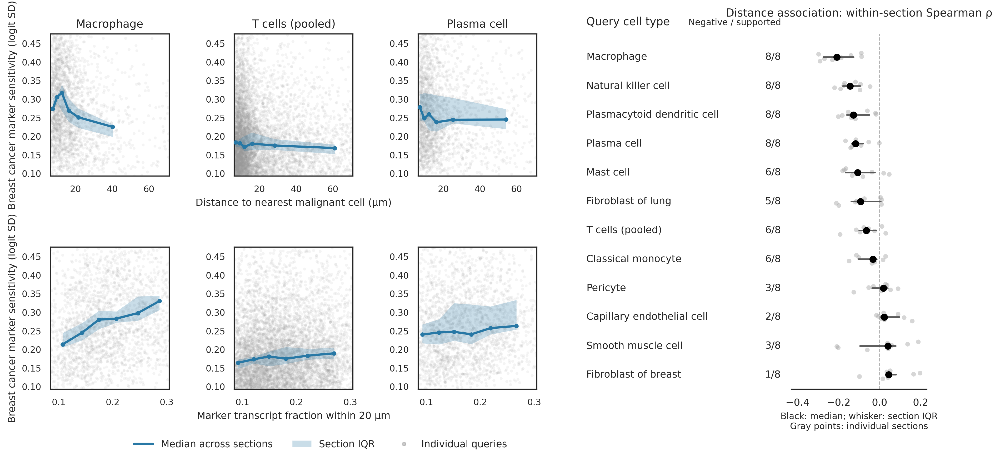

Ribbon figure and section-balanced bin summaries: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/representative_proximity/transcript_exposure20um_ribbon_2_


In [27]:
# Raw assigned transcripts from neighboring cells whose centroids are within 20 µm.
import anndata as ad
from scipy import sparse
from scipy.spatial import cKDTree

TRANSCRIPT_RADIUS_UM = 20
transcript_fraction_path = QUERY_RESPONSIVENESS / "query_selected_marker_transcript_fraction_20um.csv"
transcript_fraction_metadata = transcript_fraction_path.with_suffix(".json")
expected_transcript_metadata = dict(marker_genes=SELECTED_RESPONSE_MARKERS, radius_um=TRANSCRIPT_RADIUS_UM,
    counts="raw source X", neighborhood="cell centroids within radius, excluding query")
if transcript_fraction_path.exists():
    if not transcript_fraction_metadata.exists() or json.loads(transcript_fraction_metadata.read_text()) != expected_transcript_metadata:
        raise ValueError("Cached transcript fraction uses a different definition")
else:
    transcript_rows = []
    transcript_coverage = []
    for entry in design["slices"]:
        source = ad.read_h5ad(entry["input"], backed="r")
        try:
            obs = source.obs.copy()
            names = source.var.get("feature_name", pd.Series(source.var_names, index=source.var_names)).fillna("").astype(str).to_numpy()
            names = np.where(names == "", source.var_names.astype(str), names)
            marker_mask = np.isin(names, SELECTED_RESPONSE_MARKERS)
            counts = source.X.to_memory() if hasattr(source.X, "to_memory") else source.X[:]
            if sparse.issparse(counts):
                total_per_cell = np.asarray(counts.sum(axis=1)).ravel().astype(float)
                marker_per_cell = np.asarray(counts[:, marker_mask].sum(axis=1)).ravel().astype(float)
            else:
                total_per_cell = np.asarray(counts).sum(axis=1).astype(float)
                marker_per_cell = np.asarray(counts)[:, marker_mask].sum(axis=1).astype(float)
            del counts
        finally:
            source.file.close()
        if (total_per_cell < 0).any() or (marker_per_cell > total_per_cell).any():
            raise ValueError("Invalid raw transcript totals")
        transcript_coverage.append(dict(slice=entry["slice"], n_panel_genes=len(names),
            n_requested_markers=len(SELECTED_RESPONSE_MARKERS), n_present_markers=int(marker_mask.sum()),
            missing_markers=", ".join(g for g in SELECTED_RESPONSE_MARKERS if g not in set(names))))
        obs.index = obs.index.astype(str)
        if not obs.index.is_unique:
            raise ValueError("Duplicate source cell IDs")
        coords = obs[["x_centroid", "y_centroid"]].apply(pd.to_numeric, errors="coerce").to_numpy()
        finite_positions = np.flatnonzero(np.isfinite(coords).all(axis=1))
        tree = cKDTree(coords[finite_positions])
        queries = query_distance_responses.loc[query_distance_responses["slice"].eq(entry["slice"])]
        query_positions = obs.index.get_indexer(queries.query_cell_id)
        if (query_positions < 0).any() or not np.isfinite(coords[query_positions]).all():
            raise ValueError("Missing query source coordinates")
        neighborhoods = tree.query_ball_point(coords[query_positions], r=TRANSCRIPT_RADIUS_UM)
        for (_, query), position, neighbors in zip(queries.iterrows(), query_positions, neighborhoods):
            positions = finite_positions[np.asarray(neighbors, dtype=int)]
            positions = positions[positions != position]
            total = float(total_per_cell[positions].sum())
            marker = float(marker_per_cell[positions].sum())
            transcript_rows.append(dict(slice=entry["slice"], query_cell_id=query.query_cell_id,
                neighborhood_cells=len(positions), neighborhood_total_transcripts=total,
                neighborhood_marker_transcripts=marker,
                marker_transcript_fraction_20um=marker / total if total > 0 else np.nan))
        print("Transcript fractions:", entry["label"], len(queries), flush=True)
    pd.DataFrame(transcript_rows).to_csv(transcript_fraction_path, index=False)
    pd.DataFrame(transcript_coverage).to_csv(transcript_fraction_path.with_name("transcript_fraction_marker_coverage.csv"), index=False)
    transcript_fraction_metadata.write_text(json.dumps(expected_transcript_metadata, indent=2) + "\n")
transcript_exposure_cells = proximity_cells.merge(pd.read_csv(transcript_fraction_path),
    on=["slice", "query_cell_id"], how="left", validate="one_to_one")
if transcript_exposure_cells.neighborhood_total_transcripts.isna().any():
    raise ValueError("Missing neighborhood transcript totals")
print("Marker-supported queries without neighborhood transcripts:",
      int(transcript_exposure_cells.marker_transcript_fraction_20um.isna().sum()))
transcript_exposure_cells = transcript_exposure_cells.dropna(subset=["marker_transcript_fraction_20um"]).copy()
transcript_exposure_cells["transcript_fraction_bin"] = population_exposure_bins(
    transcript_exposure_cells, "marker_transcript_fraction_20um")
transcript_exposure_bins = transcript_exposure_cells.groupby(
    ["query_group", "slice", "transcript_fraction_bin"], observed=True).agg(
        marker_transcript_fraction_20um=("marker_transcript_fraction_20um", "median"),
        sensitivity=(PROXIMITY_MARKER_METRIC, "median"), n_queries=("query_cell_id", "nunique")).reset_index()
transcript_exposure_bins = transcript_exposure_bins.loc[
    transcript_exposure_bins.n_queries >= PROXIMITY_MIN_BIN_QUERIES].copy()

from matplotlib.patches import Patch

RIBBON_MIN_SECTIONS = 3
ribbon_tables = []
for exposure, bins, bin_col, x_col in [
    ("distance", proximity_bins, "distance_bin", "distance_um"),
    ("fraction", transcript_exposure_bins, "transcript_fraction_bin", "marker_transcript_fraction_20um"),
]:
    # Each input row is one section's median sensitivity in a common x bin.
    summary = bins.groupby(["query_group", bin_col], observed=True).agg(
        x=(x_col, "median"), sensitivity_median=("sensitivity", "median"),
        sensitivity_q25=("sensitivity", lambda x: x.quantile(0.25)),
        sensitivity_q75=("sensitivity", lambda x: x.quantile(0.75)),
        n_sections=("slice", "nunique")).reset_index()
    summary["exposure_bin"] = summary[bin_col].astype(str)
    summary["exposure"] = exposure
    ribbon_tables.append(summary.drop(columns=bin_col))
ribbon_summary = pd.concat(ribbon_tables, ignore_index=True)
transcript_plot_max = max(0.1, np.ceil(transcript_exposure_cells.loc[
    transcript_exposure_cells.query_group.isin(PANEL_QUERY_TYPES),
    "marker_transcript_fraction_20um"].max() * 10) / 10)
fig = plt.figure(figsize=(12, 6), dpi=300)
outer_layout = fig.add_gridspec(1, 2, width_ratios=[3, 2.1], wspace=0.12)
layout = outer_layout[0].subgridspec(2, 3, wspace=0.55, hspace=0.50)
ribbon_color = "#2878a5"
for col, query_group in enumerate(PANEL_QUERY_TYPES):
    top_ax = None
    for row, exposure in enumerate(["distance", "fraction"]):
        ax = fig.add_subplot(layout[row, col], sharey=top_ax)
        if row == 0:
            top_ax = ax
        cells = proximity_cells if row == 0 else transcript_exposure_cells
        x_col = "query_distance_um" if row == 0 else "marker_transcript_fraction_20um"
        points = cells.loc[cells.query_group.eq(query_group)]
        ax.scatter(points[x_col], points[PROXIMITY_MARKER_METRIC], color="0.6",
                   s=7, alpha=0.10, edgecolors="none", rasterized=True, zorder=1)
        line = ribbon_summary.loc[ribbon_summary.query_group.eq(query_group) &
                                  ribbon_summary.exposure.eq(exposure)].sort_values("x")
        supported = line.n_sections >= RIBBON_MIN_SECTIONS
        # NaNs leave gaps at bins without enough sections.
        median = line.sensitivity_median.where(supported).to_numpy(dtype=float)
        lower = line.sensitivity_q25.where(supported).to_numpy(dtype=float)
        upper = line.sensitivity_q75.where(supported).to_numpy(dtype=float)
        ax.fill_between(line.x.to_numpy(dtype=float), lower, upper,
                        color=ribbon_color, alpha=0.25, linewidth=0, zorder=2)
        ax.plot(line.x, median, color=ribbon_color, linewidth=2, marker="o", markersize=3, zorder=3)
        # ax.set_yscale("log")
        if row == 0:
            # ax.set_xscale("symlog", linthresh=10)
            ax.set_xlim(left=0)
            ax.set_title(query_group.capitalize(), fontsize=10)
            ax.set_xlabel("Distance to nearest malignant cell (µm)" if col == 1 else "", fontsize=9)
        else:
            ax.set_xlim(-0.01, min(1.01, transcript_plot_max + 0.01))
            ax.xaxis.set_major_locator(MultipleLocator(0.1))
            ax.set_xlabel("Marker transcript fraction within 20 µm" if col == 1 else "", fontsize=9)
        ax.set_ylabel("Breast cancer marker sensitivity (logit SD)" if col == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        set_sensitivity_display_range(ax, proximity_cells.loc[
            proximity_cells.query_group.isin(PANEL_QUERY_TYPES), PROXIMITY_MARKER_METRIC])
        set_shared_exposure_display_range(ax, cells, x_col)

forest_layout = outer_layout[1].subgridspec(1, 2, width_ratios=[1.45, 1], wspace=0.05)
ax_forest_labels = fig.add_subplot(forest_layout[0])
ax_summary = fig.add_subplot(forest_layout[1], sharey=ax_forest_labels)
for y, (query_group, row) in enumerate(forest_summary.iterrows()):
    ax_forest_labels.text(0, y, query_group.capitalize(), va="center", fontsize=9)
    ax_forest_labels.text(0.99, y,
        f"{int(row.n_negative_sections)}/{int(row.n_supported_sections)}",
        ha="right", va="center", fontsize=9)
    # Stable vertical offsets separate section estimates without moving their rho values.
    section_values = proximity_section_statistics.loc[
        proximity_section_statistics.query_group.eq(query_group)
    ].set_index("slice").reindex(SLICE_ORDER)["spearman_rho"].dropna()
    section_offsets = np.linspace(-0.14, 0.14, len(section_values))
    ax_summary.scatter(section_values.to_numpy(), y + section_offsets,
                       color="0.65", alpha=0.45, s=18, edgecolors="none", zorder=1)
    if pd.notna(row.plotted_rho):
        ax_summary.plot([row.rho_q25, row.rho_q75], [y, y], color="0.35", linewidth=1.4)
        ax_summary.scatter(row.plotted_rho, y, color="black", s=32, zorder=3)
    else:
        ax_summary.text(0, y, "Insufficient support", va="center", ha="center", fontsize=7, color="0.5")
ax_forest_labels.set_xlim(0, 1)
ax_forest_labels.set_ylim(len(forest_summary) - 0.5, -0.8)
ax_forest_labels.axis("off")
ax_forest_labels.text(0, 1.025, "Query cell type", transform=ax_forest_labels.transAxes, fontsize=10)
ax_forest_labels.text(0.99, 1.025, "Negative / supported", ha="right",
                     transform=ax_forest_labels.transAxes, fontsize=8)
ax_summary.axvline(0, color="0.7", linestyle="--", linewidth=0.8, zorder=0)
forest_low = np.floor(min(-0.1, proximity_section_statistics.spearman_rho.min()) * 5) / 5
forest_high = max(0.1, np.ceil(proximity_section_statistics.spearman_rho.max() * 10) / 10)
ax_summary.set_xlim(forest_low - 0.03, forest_high + 0.03)
ax_summary.tick_params(axis="y", left=False, labelleft=False)
for spine in ["left", "right", "top"]:
    ax_summary.spines[spine].set_visible(False)
ax_summary.set_title("Distance association: within-section Spearman ρ", fontsize=10, pad=16)
ax_summary.set_xlabel("Black: median; whisker: section IQR\nGray points: individual sections", fontsize=8)
ax_summary.tick_params(axis="x", labelsize=9)
fig.legend(handles=[
    Line2D([0], [0], color=ribbon_color, linewidth=2, label="Median across sections"),
    Patch(facecolor=ribbon_color, alpha=0.25, label="Section IQR"),
    Line2D([0], [0], marker="o", linestyle="", color="0.6", alpha=0.5, markersize=3, label="Individual queries"),
], loc="lower center", bbox_to_anchor=(0.34, 0.015), ncol=3, frameon=False)
fig.subplots_adjust(left=0.055, right=0.98, bottom=0.16, top=0.91)
ribbon_index = 1
while list(proximity_output.glob(f"transcript_exposure20um_ribbon_{ribbon_index}_*")):
    ribbon_index += 1
ribbon_prefix = proximity_output / f"transcript_exposure20um_ribbon_{ribbon_index}_"
fig.savefig(str(ribbon_prefix) + "figure.png", dpi=300, bbox_inches="tight")
fig.savefig(str(ribbon_prefix) + "figure.pdf", bbox_inches="tight")
ribbon_summary.to_csv(str(ribbon_prefix) + "bin_summary.csv", index=False)
transcript_exposure_cells.to_csv(str(ribbon_prefix) + "cells.csv", index=False)
transcript_exposure_bins.to_csv(str(ribbon_prefix) + "section_bins.csv", index=False)
pd.concat(population_bin_coverage.values(), ignore_index=True).to_csv(
    str(ribbon_prefix) + "population_bin_coverage.csv", index=False)
plt.show()
print("Ribbon figure and section-balanced bin summaries:", ribbon_prefix)


## Alternative: malignant-cell count among the 20 nearest neighbors

Same selected cell types, 32-gene logit sensitivity, distance panels, and distance-association forest plot. Bottom-row x-axis: **number of cells annotated malignant among the 20 nearest cells**, excluding the query itself. Neighbors are selected by 2D Euclidean centroid distance within the same section, allowing all cell types and no transcript-count filter. There is **no fixed radius**: “20” refers to a cell count, not 20 µm. Queries with fewer than 20 available other cells are omitted; the distance to the 20th neighbor is retained in the cache for auditing.

The count ranges from 0 to 20. Approximately equal-population bins are defined per query type with shared boundaries across sections; integer ties stay together and can produce unequal or fewer bins. The curves and ribbons retain equal section weights, section median/IQR aggregation, and the configured query/bin and section-support thresholds. Shared x-limits within each row and a common y-range use the pooled central 90% across the chosen query types, as above. The forest plot still summarizes **distance** associations. Numerator counts, actual neighborhood size, radius to the 20th neighbor, and binned data are saved separately from the earlier versions.


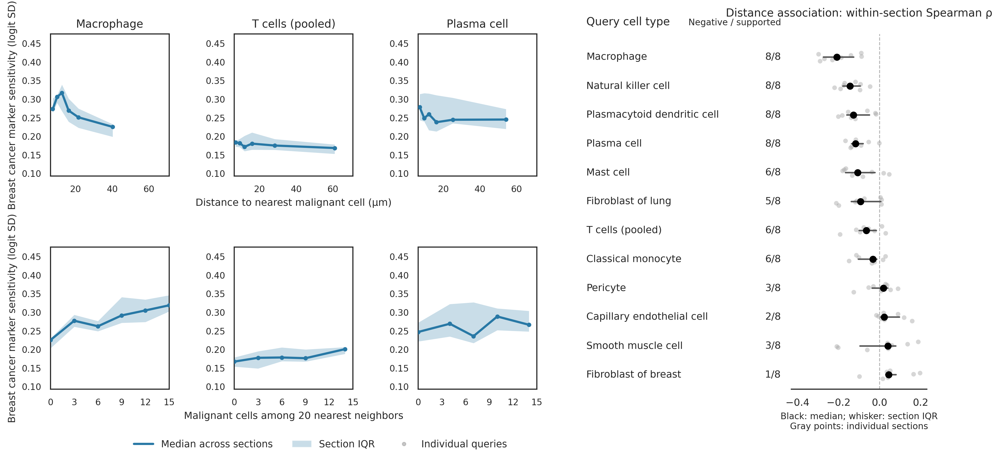

Ribbon figure and section-balanced bin summaries: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/representative_proximity/nearest20_malignant_count_ribbon_2_


In [28]:
import anndata as ad
from scipy.spatial import cKDTree
from matplotlib.ticker import MaxNLocator

K_NEAREST_CELLS = 20
nearest20_path = QUERY_RESPONSIVENESS / "query_malignant_cells_among_20_nearest.csv"
if not nearest20_path.exists():
    nearest20_frames = []
    for entry in design["slices"]:
        source = ad.read_h5ad(entry["input"], backed="r")
        try:
            obs = source.obs.copy()
        finally:
            source.file.close()
        obs.index = obs.index.astype(str)
        if not obs.index.is_unique:
            raise ValueError("Duplicate source cell IDs")
        coords = obs[["x_centroid", "y_centroid"]].apply(pd.to_numeric, errors="coerce").to_numpy()
        finite_positions = np.flatnonzero(np.isfinite(coords).all(axis=1))
        tree = cKDTree(coords[finite_positions])
        current = query_distance_responses.loc[query_distance_responses["slice"].eq(entry["slice"]),
            ["slice", "query_cell_id"]].copy()
        positions = obs.index.get_indexer(current.query_cell_id)
        if (positions < 0).any() or not np.isfinite(coords[positions]).all():
            raise ValueError("Missing query centroid")
        distances, indices = tree.query(coords[positions], k=min(K_NEAREST_CELLS + 1, len(finite_positions)))
        if np.ndim(indices) == 1:
            indices, distances = indices[:, None], distances[:, None]
        tumor = obs.harmony_cell_type.astype(str).eq("malignant cell").to_numpy()
        counts, radii, neighborhood_sizes = [], [], []
        for position, neighbor_indices, neighbor_distances in zip(positions, indices, distances):
            neighbor_positions = finite_positions[neighbor_indices]
            keep = neighbor_positions != position
            neighbors = neighbor_positions[keep][:K_NEAREST_CELLS]
            radii_here = neighbor_distances[keep][:K_NEAREST_CELLS]
            neighborhood_sizes.append(len(neighbors))
            counts.append(int(tumor[neighbors].sum()) if len(neighbors) == K_NEAREST_CELLS else np.nan)
            radii.append(float(radii_here[-1]) if len(neighbors) == K_NEAREST_CELLS else np.nan)
        current["malignant_neighbors_k20"] = counts
        current["n_nearest_neighbors"] = neighborhood_sizes
        current["distance_to_20th_neighbor_um"] = radii
        nearest20_frames.append(current)
    pd.concat(nearest20_frames, ignore_index=True).to_csv(nearest20_path, index=False)
    nearest20_path.with_suffix(".json").write_text(json.dumps(dict(
        k=K_NEAREST_CELLS, exclude_query=True, neighbor_pool="all finite-coordinate cells within the same section",
        annotation="harmony_cell_type == malignant cell", coordinate_columns=["x_centroid", "y_centroid"],
        distance="2D Euclidean centroid distance; no maximum radius", counts_filter=None,
        fewer_than_20="missing", tied_distances="cKDTree selection among tied neighbors"), indent=2) + "\n")
nearest20_cells = proximity_cells.merge(pd.read_csv(nearest20_path),
    on=["slice", "query_cell_id"], how="left", validate="one_to_one")
if nearest20_cells.n_nearest_neighbors.isna().any():
    raise ValueError("Unmatched nearest-neighbor data")
nearest20_cells = nearest20_cells.dropna(subset=["malignant_neighbors_k20"]).copy()
if not nearest20_cells.malignant_neighbors_k20.between(0, 20).all():
    raise ValueError("Invalid malignant-neighbor counts")
nearest20_cells["malignant_neighbor_bin"] = population_exposure_bins(nearest20_cells, "malignant_neighbors_k20")
nearest20_bins = nearest20_cells.groupby(["query_group", "slice", "malignant_neighbor_bin"], observed=True).agg(
    malignant_neighbors_k20=("malignant_neighbors_k20", "median"),
    sensitivity=(PROXIMITY_MARKER_METRIC, "median"), n_queries=("query_cell_id", "nunique")).reset_index()
nearest20_bins = nearest20_bins.loc[nearest20_bins.n_queries >= PROXIMITY_MIN_BIN_QUERIES].copy()

from matplotlib.patches import Patch

RIBBON_MIN_SECTIONS = 3
ribbon_tables = []
for exposure, bins, bin_col, x_col in [
    ("distance", proximity_bins, "distance_bin", "distance_um"),
    ("nearest20", nearest20_bins, "malignant_neighbor_bin", "malignant_neighbors_k20"),
]:
    # Each input row is one section's median sensitivity in a common x bin.
    summary = bins.groupby(["query_group", bin_col], observed=True).agg(
        x=(x_col, "median"), sensitivity_median=("sensitivity", "median"),
        sensitivity_q25=("sensitivity", lambda x: x.quantile(0.25)),
        sensitivity_q75=("sensitivity", lambda x: x.quantile(0.75)),
        n_sections=("slice", "nunique")).reset_index()
    summary["exposure_bin"] = summary[bin_col].astype(str)
    summary["exposure"] = exposure
    ribbon_tables.append(summary.drop(columns=bin_col))
ribbon_summary = pd.concat(ribbon_tables, ignore_index=True)
fig = plt.figure(figsize=(12, 6), dpi=300)
outer_layout = fig.add_gridspec(1, 2, width_ratios=[3, 2.1], wspace=0.12)
layout = outer_layout[0].subgridspec(2, 3, wspace=0.55, hspace=0.50)
ribbon_color = "#2878a5"
for col, query_group in enumerate(PANEL_QUERY_TYPES):
    top_ax = None
    for row, exposure in enumerate(["distance", "nearest20"]):
        ax = fig.add_subplot(layout[row, col], sharey=top_ax)
        if row == 0:
            top_ax = ax
        cells = proximity_cells if row == 0 else nearest20_cells
        x_col = "query_distance_um" if row == 0 else "malignant_neighbors_k20"
        points = cells.loc[cells.query_group.eq(query_group)]
        # ax.scatter(points[x_col], points[PROXIMITY_MARKER_METRIC], color="0.6",
        #            s=7, alpha=0.10, edgecolors="none", rasterized=True, zorder=1)
        line = ribbon_summary.loc[ribbon_summary.query_group.eq(query_group) &
                                  ribbon_summary.exposure.eq(exposure)].sort_values("x")
        supported = line.n_sections >= RIBBON_MIN_SECTIONS
        # NaNs leave gaps at bins without enough sections.
        median = line.sensitivity_median.where(supported).to_numpy(dtype=float)
        lower = line.sensitivity_q25.where(supported).to_numpy(dtype=float)
        upper = line.sensitivity_q75.where(supported).to_numpy(dtype=float)
        ax.fill_between(line.x.to_numpy(dtype=float), lower, upper,
                        color=ribbon_color, alpha=0.25, linewidth=0, zorder=2)
        ax.plot(line.x, median, color=ribbon_color, linewidth=2, marker="o", markersize=3, zorder=3)
        # ax.set_yscale("log")
        if row == 0:
            # ax.set_xscale("symlog", linthresh=10)
            ax.set_xlim(left=0)
            ax.set_title(query_group.capitalize(), fontsize=10)
            ax.set_xlabel("Distance to nearest malignant cell (µm)" if col == 1 else "", fontsize=9)
        else:
            ax.set_xlim(-0.5, 20.5)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
            ax.set_xlabel("Malignant cells among 20 nearest neighbors" if col == 1 else "", fontsize=9)
        ax.set_ylabel("Breast cancer marker sensitivity (logit SD)" if col == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        set_sensitivity_display_range(ax, proximity_cells.loc[
            proximity_cells.query_group.isin(PANEL_QUERY_TYPES), PROXIMITY_MARKER_METRIC])
        set_shared_exposure_display_range(ax, cells, x_col)

forest_layout = outer_layout[1].subgridspec(1, 2, width_ratios=[1.45, 1], wspace=0.05)
ax_forest_labels = fig.add_subplot(forest_layout[0])
ax_summary = fig.add_subplot(forest_layout[1], sharey=ax_forest_labels)
for y, (query_group, row) in enumerate(forest_summary.iterrows()):
    ax_forest_labels.text(0, y, query_group.capitalize(), va="center", fontsize=9)
    ax_forest_labels.text(0.99, y,
        f"{int(row.n_negative_sections)}/{int(row.n_supported_sections)}",
        ha="right", va="center", fontsize=9)
    # Stable vertical offsets separate section estimates without moving their rho values.
    section_values = proximity_section_statistics.loc[
        proximity_section_statistics.query_group.eq(query_group)
    ].set_index("slice").reindex(SLICE_ORDER)["spearman_rho"].dropna()
    section_offsets = np.linspace(-0.14, 0.14, len(section_values))
    ax_summary.scatter(section_values.to_numpy(), y + section_offsets,
                       color="0.65", alpha=0.45, s=18, edgecolors="none", zorder=1)
    if pd.notna(row.plotted_rho):
        ax_summary.plot([row.rho_q25, row.rho_q75], [y, y], color="0.35", linewidth=1.4)
        ax_summary.scatter(row.plotted_rho, y, color="black", s=32, zorder=3)
    else:
        ax_summary.text(0, y, "Insufficient support", va="center", ha="center", fontsize=7, color="0.5")
ax_forest_labels.set_xlim(0, 1)
ax_forest_labels.set_ylim(len(forest_summary) - 0.5, -0.8)
ax_forest_labels.axis("off")
ax_forest_labels.text(0, 1.025, "Query cell type", transform=ax_forest_labels.transAxes, fontsize=10)
ax_forest_labels.text(0.99, 1.025, "Negative / supported", ha="right",
                     transform=ax_forest_labels.transAxes, fontsize=8)
ax_summary.axvline(0, color="0.7", linestyle="--", linewidth=0.8, zorder=0)
forest_low = np.floor(min(-0.1, proximity_section_statistics.spearman_rho.min()) * 5) / 5
forest_high = max(0.1, np.ceil(proximity_section_statistics.spearman_rho.max() * 10) / 10)
ax_summary.set_xlim(forest_low - 0.03, forest_high + 0.03)
ax_summary.tick_params(axis="y", left=False, labelleft=False)
for spine in ["left", "right", "top"]:
    ax_summary.spines[spine].set_visible(False)
ax_summary.set_title("Distance association: within-section Spearman ρ", fontsize=10, pad=16)
ax_summary.set_xlabel("Black: median; whisker: section IQR\nGray points: individual sections", fontsize=8)
ax_summary.tick_params(axis="x", labelsize=9)
fig.legend(handles=[
    Line2D([0], [0], color=ribbon_color, linewidth=2, label="Median across sections"),
    Patch(facecolor=ribbon_color, alpha=0.25, label="Section IQR"),
    Line2D([0], [0], marker="o", linestyle="", color="0.6", alpha=0.5, markersize=3, label="Individual queries"),
], loc="lower center", bbox_to_anchor=(0.34, 0.015), ncol=3, frameon=False)
fig.subplots_adjust(left=0.055, right=0.98, bottom=0.16, top=0.91)
ribbon_index = 1
while list(proximity_output.glob(f"nearest20_malignant_count_ribbon_{ribbon_index}_*")):
    ribbon_index += 1
ribbon_prefix = proximity_output / f"nearest20_malignant_count_ribbon_{ribbon_index}_"
fig.savefig(str(ribbon_prefix) + "figure.png", dpi=300, bbox_inches="tight")
fig.savefig(str(ribbon_prefix) + "figure.pdf", bbox_inches="tight")
ribbon_summary.to_csv(str(ribbon_prefix) + "bin_summary.csv", index=False)
nearest20_cells.to_csv(str(ribbon_prefix) + "cells.csv", index=False)
nearest20_bins.to_csv(str(ribbon_prefix) + "section_bins.csv", index=False)
proximity_section_statistics.to_csv(str(ribbon_prefix) + "distance_section_correlations.csv", index=False)
pd.concat(population_bin_coverage.values(), ignore_index=True).to_csv(
    str(ribbon_prefix) + "population_bin_coverage.csv", index=False)
plt.show()
print("Ribbon figure and section-balanced bin summaries:", ribbon_prefix)


## Gene-level context-swap response versus malignant count in donor neighborhoods

Rows are query cell types (T-cell subtypes pooled); columns are individual genes. For each query and gene expressed in its raw counts, fit a linear slope of its predicted admixture **logit** across the same substituted contexts against the **number of malignant cells among the context donor's actual 20 nearest neighbors**, excluding that donor itself. Units are **logit change per additional malignant neighbor**. Subtracting the query's original-context gene logit gives the same slope because that baseline is constant within the query.

A positive slope means the gene becomes more strongly predicted as admixture when supplied contexts from donor locations with more malignant neighbors; a negative slope means the reverse. Each tile is the **median of query-level slopes within each section, followed by the median across sections**. This gives sections equal weight. A section/gene needs ≥10 supported queries; a tile needs ≥3 sections. Context panels must have ≥10 matched donors and ≥3 distinct malignant-neighbor counts. Only expressed query genes are scored; unsupported combinations stay missing (gray), not zero. The model still receives its existing **five-cell substituted contexts**: the physical 20-neighbor count describes the donor location, not a change to the model input size or an isolated causal manipulation of malignant abundance.

Pooled T-cell sections pool query-level slopes before taking medians, retaining the original subtype-specific context panels. All tested query types are shown, independent of `PANEL_QUERY_TYPES`. The first heatmap uses the user-selected 32-gene panel. “Other measured genes” means its complement, **not a validated non-malignant gene set**. Other-gene columns are split across readable pages; a full-width overview is exported. Both sets share a symmetric color scale centered on zero. Gene-level query slopes, section medians, support counts, matched donor IDs, and physical-neighborhood caches are saved. These heatmaps measure context responsiveness rather than biological accuracy.


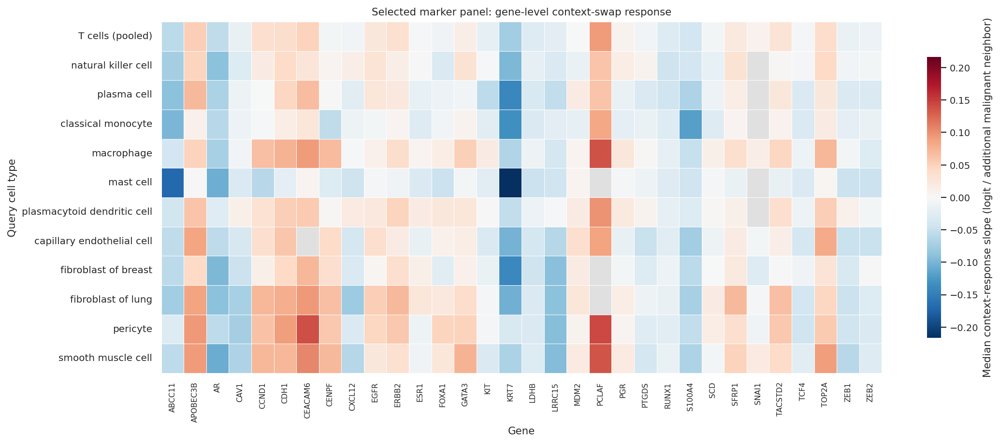

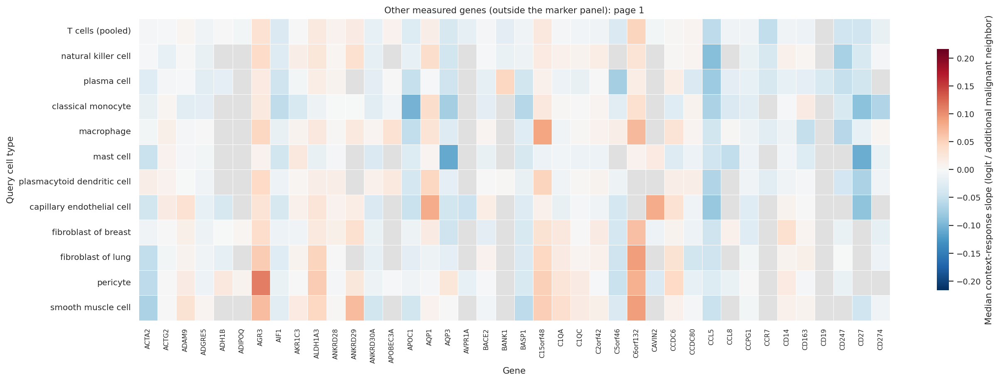

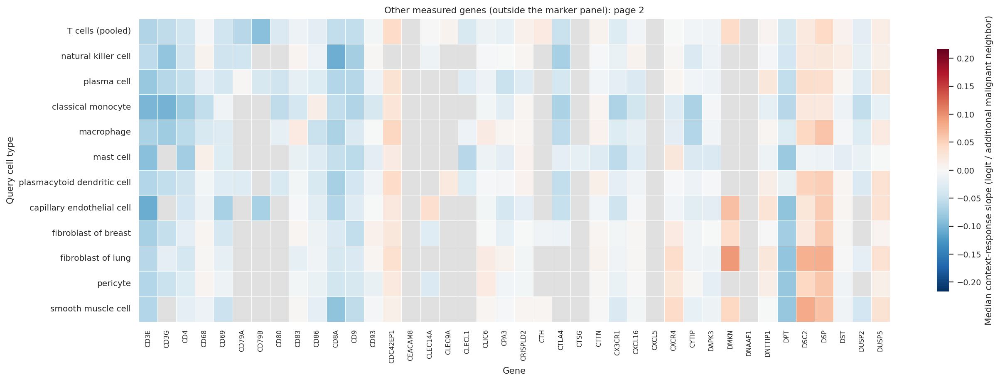

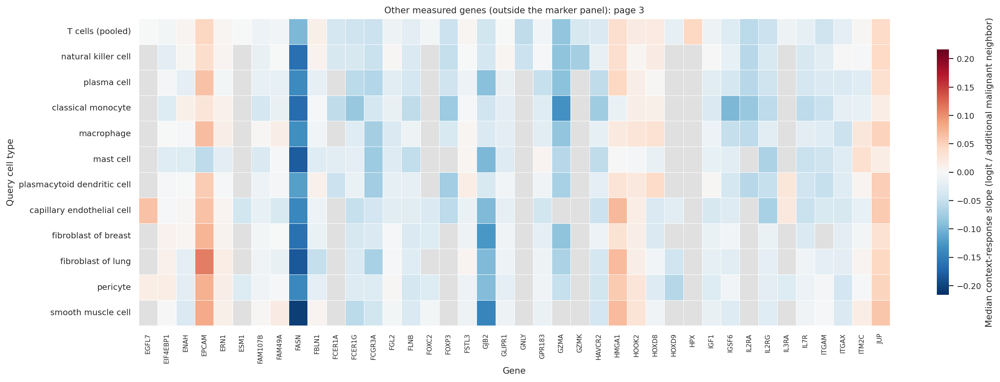

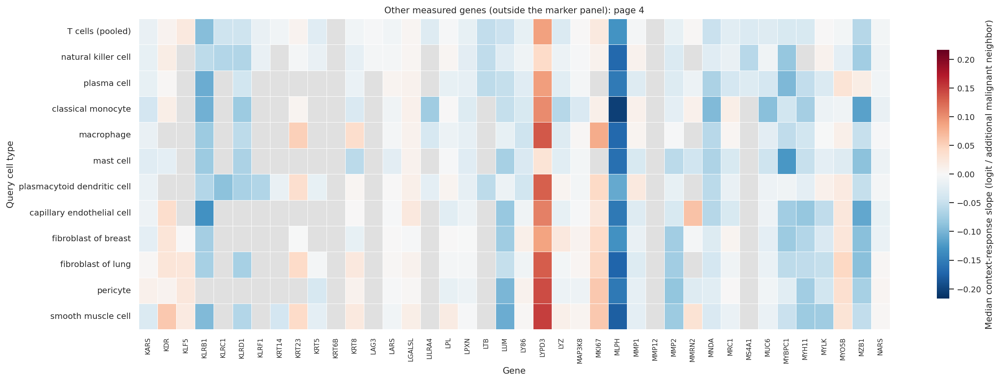

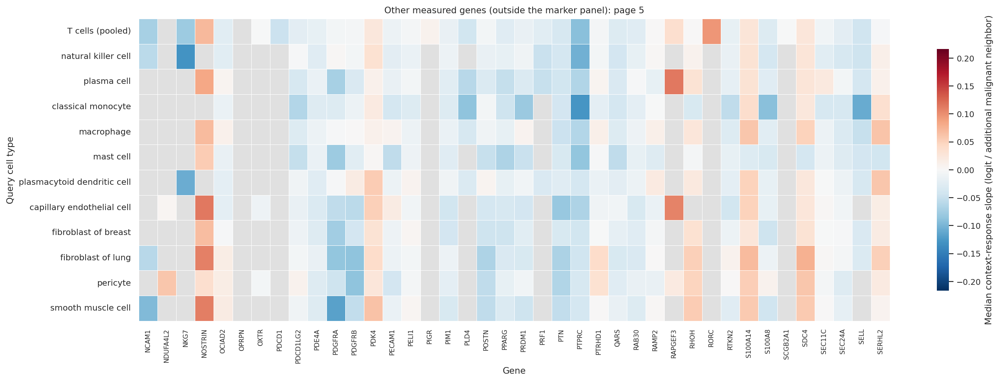

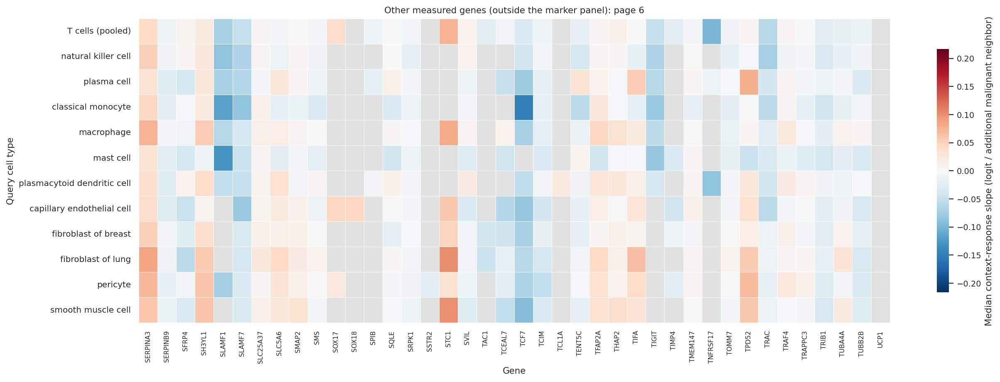

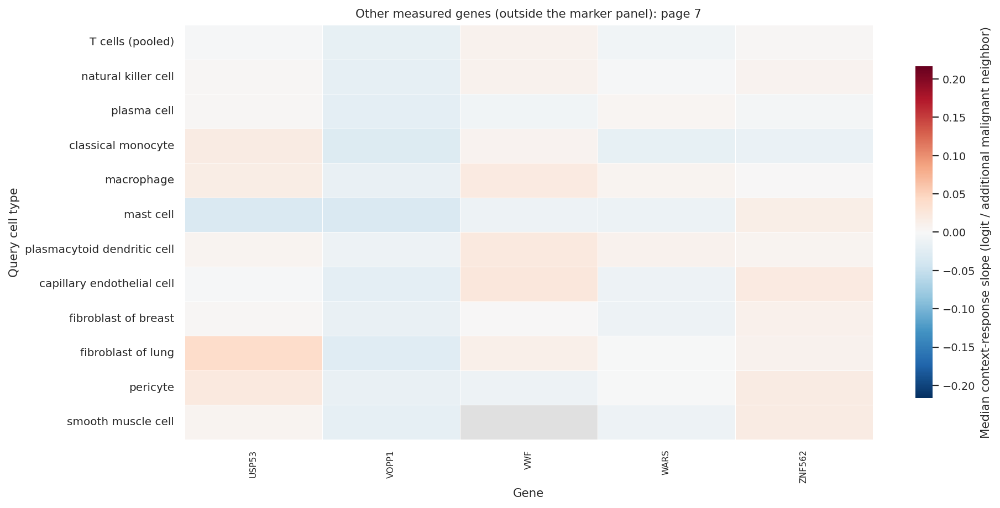

Marker / other genes: 32 245
Heatmaps and tables: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/gene_context_swap_physical20/heatmaps_2_


In [29]:
from gene_context_slopes import compute_gene_context_slopes

GENE_SLOPE_RESULTS = RUN / "gene_context_swap_physical20_markers32_20261019"
GENE_HEATMAP_COLUMNS_PER_PAGE = 40
slice_gene_slopes = compute_gene_context_slopes(
    RUN, GENE_SLOPE_RESULTS, SELECTED_RESPONSE_MARKERS,
    pool_t_cells=True, min_queries=MIN_SUPPORTED_QUERIES_PER_SLICE, context_predictor="donor_physical20")
gene_slope_summary = slice_gene_slopes.groupby(["query_group", "gene", "gene_set"], observed=True).agg(
    median_context_slope=("median_slope", "median"),
    n_supported_sections=("median_slope", "count"),
    n_supported_queries=("n_queries", "sum")).reset_index()
gene_slope_summary["plotted_slope"] = gene_slope_summary.median_context_slope.where(
    gene_slope_summary.n_supported_sections >= MIN_SLICES_PER_HEATMAP_TILE)
gene_heatmap_rows = list(dict.fromkeys("T cells (pooled)" if t in {
    "CD4-positive, alpha-beta memory T cell", "cytotoxic T cell", "natural T-regulatory cell"} else t
    for t in TYPE_ORDER))
gene_heatmap_values = gene_slope_summary.pivot(index="query_group", columns="gene", values="plotted_slope").reindex(index=gene_heatmap_rows)
gene_heatmap_support = gene_slope_summary.pivot(index="query_group", columns="gene", values="n_supported_sections").reindex(index=gene_heatmap_rows)
gene_heatmap_limit = max(float(gene_slope_summary.plotted_slope.abs().max()), 0.001)
marker_heatmap_genes = [g for g in SELECTED_RESPONSE_MARKERS if g in gene_heatmap_values.columns]
other_heatmap_genes = sorted(set(gene_heatmap_values.columns) - set(SELECTED_RESPONSE_MARKERS))
GENE_HEATMAP_FIGURES = FIGURES / "gene_context_swap_physical20"
GENE_HEATMAP_FIGURES.mkdir(exist_ok=True)
gene_heatmap_index = 1
while list(GENE_HEATMAP_FIGURES.glob(f"heatmaps_{gene_heatmap_index}_*")):
    gene_heatmap_index += 1
gene_heatmap_prefix = GENE_HEATMAP_FIGURES / f"heatmaps_{gene_heatmap_index}_"
gene_heatmap_values.to_csv(str(gene_heatmap_prefix) + "all_gene_slopes.csv")
gene_heatmap_support.to_csv(str(gene_heatmap_prefix) + "all_gene_section_support.csv")
gene_slope_summary.to_csv(str(gene_heatmap_prefix) + "summary.csv", index=False)

def draw_gene_slope_heatmap(genes, title, tag, inline=True):
    width = max(12, 0.31 * len(genes) + 4)
    fig, ax = plt.subplots(figsize=(width, max(5, 0.32 * len(gene_heatmap_rows) + 2)), dpi=160)
    ax.set_facecolor("0.88")
    sns.heatmap(gene_heatmap_values.reindex(columns=genes), ax=ax, cmap="RdBu_r", center=0,
                vmin=-gene_heatmap_limit, vmax=gene_heatmap_limit,
                linewidths=0.25, linecolor="white", xticklabels=True, yticklabels=True,
                cbar_kws={"label":"Median context-response slope (logit / additional malignant neighbor)", "shrink":0.8})
    ax.set(title=title, xlabel="Gene", ylabel="Query cell type")
    ax.tick_params(axis="x", rotation=90, labelsize=7 if len(genes) <= 40 else 5)
    ax.tick_params(axis="y", rotation=0, labelsize=9)
    fig.tight_layout()
    fig.savefig(str(gene_heatmap_prefix) + tag + ".png", dpi=200, bbox_inches="tight")
    fig.savefig(str(gene_heatmap_prefix) + tag + ".pdf", bbox_inches="tight")
    if inline:
        plt.show()
    else:
        plt.close(fig)

draw_gene_slope_heatmap(marker_heatmap_genes, "Selected marker panel: gene-level context-swap response", "selected_markers")
for start in range(0, len(other_heatmap_genes), GENE_HEATMAP_COLUMNS_PER_PAGE):
    page = start // GENE_HEATMAP_COLUMNS_PER_PAGE + 1
    draw_gene_slope_heatmap(other_heatmap_genes[start:start + GENE_HEATMAP_COLUMNS_PER_PAGE],
        f"Other measured genes (outside the marker panel): page {page}", f"other_genes_page_{page}")
if other_heatmap_genes:
    draw_gene_slope_heatmap(other_heatmap_genes, "Other measured genes: full overview", "other_genes_full", inline=False)
print("Marker / other genes:", len(marker_heatmap_genes), len(other_heatmap_genes))
print("Heatmaps and tables:", gene_heatmap_prefix)


## Encoded malignant-token proportion and position

This analysis uses the actual **five ordered neighbor-type tokens** supplied during inference, not the physical 20-neighbor descriptor. The saved neighbor builder walks neighbors in increasing distance, and tokenization preserves that list. In a context swap, the order is inherited from the **context donor**; it does not represent the substituted cells' distances to the fixed query. Rank 1 means the earliest/nearest eligible neighbor token (same-type neighbors and cells with ≤10 source counts were excluded by the existing preparation).

Response is the mean selected-marker logit over genes expressed in a fixed query, using the 32-gene panel. All comparisons hold the query expression fixed and use the same matched donor panel. The composition curves subtract each query's mean over contexts; this is equivalent to centering the change from its original context and removes between-query baseline shifts. Curves first average repeated composition levels within query, then take the median across queries within section; the final line and IQR summarize section medians, with ≥3 supported sections.

**Position analysis:** a separate within-query linear model fits the response to an intercept plus five binary malignant-slot indicators. It requires a full-rank design, so unsupported fits remain missing. A slot's relative coefficient is its coefficient minus the mean of all five coefficients. Positive relative values mean stronger association for malignancy in that slot than the average slot, conditional on malignant occupancy of the other slots. These are observational coefficients: other non-malignant cell identities also change between contexts.

The diagnostics also include within-query Spearman correlations with malignant proportion, an **exactly-one-malignant-token** rank test (≥4 such contexts and ≥3 distinct positions), and a partial Spearman correlation of mean malignant rank with response, controlling categorical malignant count among mixed contexts (≥8 contexts, ≥3 distinct mean ranks). Each statistic is summarized by query medians within section, then section medians; ≥10 supported queries/section and ≥3 sections are required for heatmap tiles. Gray means insufficient support, not no effect. Larger rank means later/farther: a negative rank association supports stronger response when malignant tokens occur earlier. No p-values treat the many queries as independent biological replicates.

Exact composition matching is unavailable in this experiment: donor selection deliberately sampled distinct full cell-type compositions. Therefore these analyses can identify associations with position, but a position-only permutation experiment would be needed to isolate an order effect from changing the other neighbor identities.


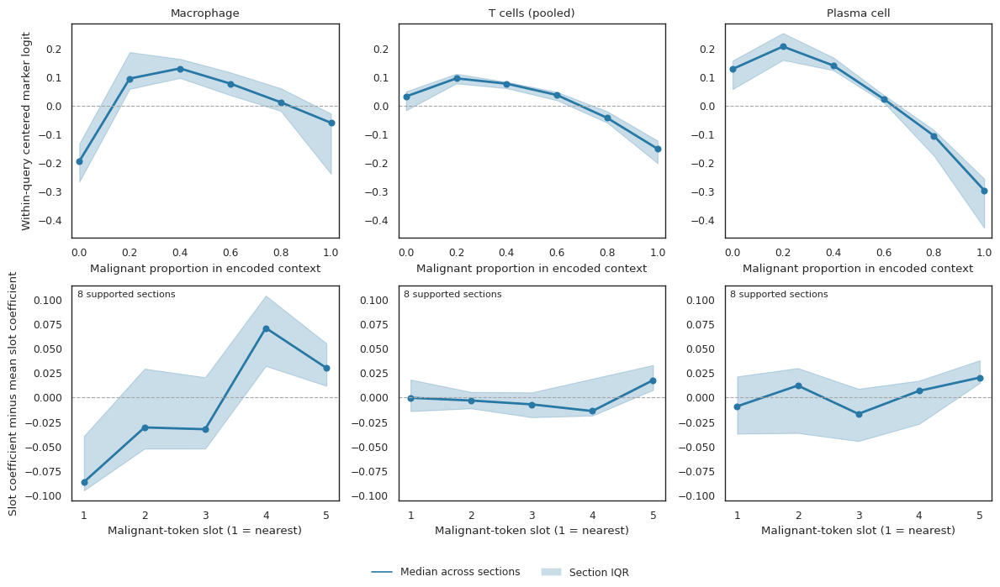

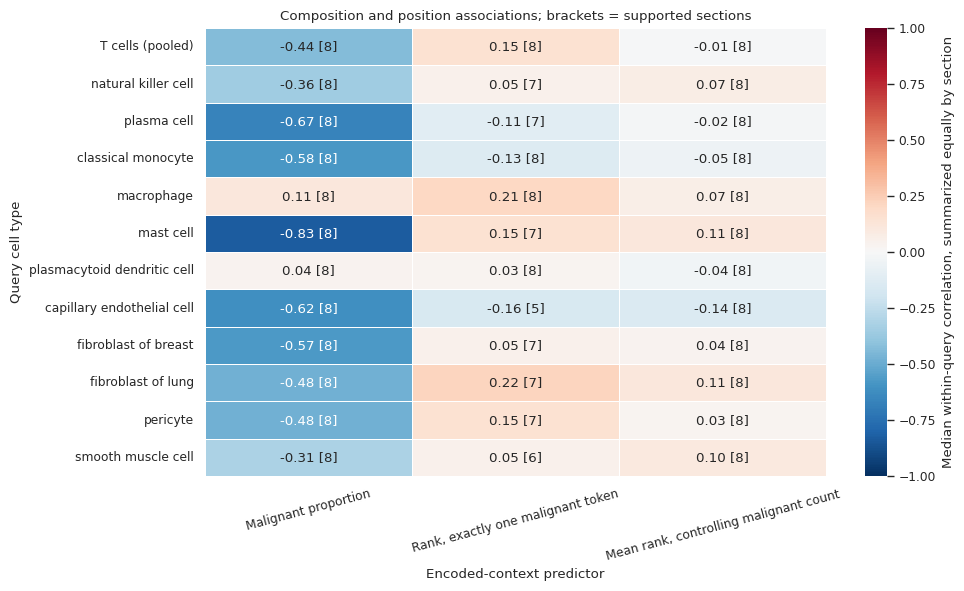

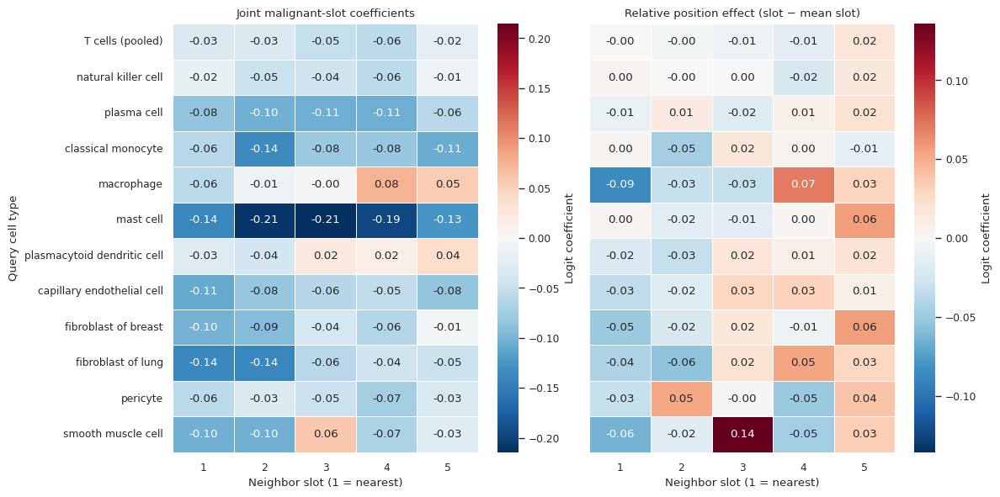

,query_group,median_value,n_sections
3,T cells (pooled),0.153897,8
8,capillary endothelial cell,-0.158114,5
13,classical monocyte,-0.132850,8
18,fibroblast of breast,0.051299,7
23,fibroblast of lung,0.223607,7
28,macrophage,0.205196,8
33,mast cell,0.153897,7
38,natural killer cell,0.051299,7
43,pericyte,0.153897,7
48,plasma cell,-0.111803,7


metric,early_minus_late_slot_coefficient,exact_one_rank_slope,rho_encoded_malignant_proportion,rho_exact_one_rank,rho_rank_adjusted_for_count
query_group,,,,,
T cells (pooled),-0.008214,0.016632,-0.435853,0.153897,-0.013920
capillary endothelial cell,-0.056036,-0.023937,-0.616459,-0.158114,-0.142805
classical monocyte,0.049036,-0.035703,-0.580263,-0.132850,-0.048354
fibroblast of breast,-0.095238,0.001869,-0.571788,0.051299,0.036550
fibroblast of lung,-0.090172,0.009674,-0.478025,0.223607,0.110612
macrophage,-0.072390,0.015773,0.112449,0.205196,0.068354
mast cell,-0.059237,0.020051,-0.829431,0.153897,0.113249
natural killer cell,-0.017693,0.001924,-0.358215,0.051299,0.072443
pericyte,-0.042638,0.017365,-0.479716,0.153897,0.026768


Encoded rank figures and tables: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/figures_stratified_markers32/encoded_context_rank/analysis_2_


In [30]:
from encoded_context_rank import analyze_encoded_context_rank
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ENCODED_RANK_RESULTS = RUN / "encoded_context_rank_markers32_20261019"
analyze_encoded_context_rank(RUN, ENCODED_RANK_RESULTS, SELECTED_RESPONSE_MARKERS,
                             min_queries=MIN_SUPPORTED_QUERIES_PER_SLICE)
encoded_query_statistics = pd.read_csv(ENCODED_RANK_RESULTS / "query_statistics.csv")
encoded_section_statistics = pd.read_csv(ENCODED_RANK_RESULTS / "section_statistics.csv")
encoded_section_curves = pd.read_csv(ENCODED_RANK_RESULTS / "section_curves.csv")
encoded_slot_sections = pd.read_csv(ENCODED_RANK_RESULTS / "section_slot_coefficients.csv")
encoded_support_audit = pd.read_csv(ENCODED_RANK_RESULTS / "support_audit.csv")
encoded_type_order = list(dict.fromkeys("T cells (pooled)" if t in {
    "CD4-positive, alpha-beta memory T cell", "cytotoxic T cell", "natural T-regulatory cell"} else t
    for t in TYPE_ORDER))
encoded_summary = encoded_section_statistics.groupby(["query_group", "metric"], observed=True).agg(
    median_value=("median_value", "median"), n_sections=("median_value", "count"),
    negative_sections=("median_value", lambda x: int(x.lt(0).sum()))).reset_index()
encoded_summary["plotted_value"] = encoded_summary.median_value.where(
    encoded_summary.n_sections >= MIN_SLICES_PER_HEATMAP_TILE)
encoded_slot_summary = encoded_slot_sections.groupby(["query_group", "slot"], observed=True).agg(
    median_coefficient=("median_coefficient", "median"),
    median_relative_coefficient=("median_relative_coefficient", "median"),
    q25=("median_relative_coefficient", lambda x: x.quantile(0.25)),
    q75=("median_relative_coefficient", lambda x: x.quantile(0.75)),
    n_sections=("median_relative_coefficient", "count")).reset_index()
encoded_curves_summary = encoded_section_curves.groupby(["query_group", "curve", "x"], observed=True).agg(
    median=("median_response", "median"), q25=("median_response", lambda x: x.quantile(0.25)),
    q75=("median_response", lambda x: x.quantile(0.75)), n_sections=("median_response", "count")).reset_index()
encoded_export_dir = FIGURES / "encoded_context_rank"
encoded_export_dir.mkdir(exist_ok=True)
encoded_index = 1
while list(encoded_export_dir.glob(f"analysis_{encoded_index}_*")):
    encoded_index += 1
encoded_prefix = encoded_export_dir / f"analysis_{encoded_index}_"
encoded_summary.to_csv(str(encoded_prefix) + "correlation_summary.csv", index=False)
encoded_slot_summary.to_csv(str(encoded_prefix) + "slot_summary.csv", index=False)
encoded_curves_summary.to_csv(str(encoded_prefix) + "curve_summary.csv", index=False)

def export_encoded_figure(fig, suffix):
    fig.savefig(str(encoded_prefix) + suffix + ".png", dpi=220, bbox_inches="tight")
    fig.savefig(str(encoded_prefix) + suffix + ".pdf", bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7), squeeze=False)
for col, cell_type in enumerate(PANEL_QUERY_TYPES):
    top = encoded_curves_summary.loc[encoded_curves_summary.query_group.eq(cell_type) &
                                    encoded_curves_summary.curve.eq("composition")].sort_values("x")
    valid = top.n_sections.ge(MIN_SLICES_PER_HEATMAP_TILE)
    axes[0, col].fill_between(top.x, top.q25.where(valid), top.q75.where(valid), color="#2878a5", alpha=0.25)
    axes[0, col].plot(top.x, top["median"].where(valid), marker="o", color="#2878a5", linewidth=2)
    axes[0, col].set(title=cell_type.capitalize(), xlabel="Malignant proportion in encoded context",
                     ylabel="Within-query centered marker logit" if col == 0 else "", xlim=(-0.03, 1.03))
    axes[0, col].set_xticks(np.linspace(0, 1, 6))
    bottom = encoded_slot_summary.loc[encoded_slot_summary.query_group.eq(cell_type)].sort_values("slot")
    valid = bottom.n_sections.ge(MIN_SLICES_PER_HEATMAP_TILE)
    axes[1, col].fill_between(bottom.slot, bottom.q25.where(valid), bottom.q75.where(valid), color="#2878a5", alpha=0.25)
    axes[1, col].plot(bottom.slot, bottom.median_relative_coefficient.where(valid), marker="o", color="#2878a5", linewidth=2)
    axes[1, col].set(xlabel="Malignant-token slot (1 = nearest)",
                     ylabel="Slot coefficient minus mean slot coefficient" if col == 0 else "", xticks=range(1, 6))
    axes[1, col].text(0.02, 0.98, f'{int(bottom.n_sections.max()) if len(bottom) else 0} supported sections',
                     transform=axes[1, col].transAxes, va="top", fontsize=8)
    for ax in axes[:, col]:
        ax.axhline(0, color="0.65", linestyle="--", linewidth=0.8)
for row in range(2):
    limits = [ax.get_ylim() for ax in axes[row]]
    low, high = min(v[0] for v in limits), max(v[1] for v in limits)
    for ax in axes[row]: ax.set_ylim(low, high)
fig.legend(handles=[Line2D([0], [0], color="#2878a5", label="Median across sections"),
                    Patch(facecolor="#2878a5", alpha=0.25, label="Section IQR")],
           loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])
export_encoded_figure(fig, "composition_and_slot_curves")

correlation_labels = {
    "rho_encoded_malignant_proportion": "Malignant proportion",
    "rho_exact_one_rank": "Rank, exactly one malignant token",
    "rho_rank_adjusted_for_count": "Mean rank, controlling malignant count",
}
heat = encoded_summary.pivot(index="query_group", columns="metric", values="plotted_value").reindex(
    index=encoded_type_order, columns=list(correlation_labels))
support = encoded_summary.pivot(index="query_group", columns="metric", values="n_sections").reindex_like(heat)
annotation = heat.copy().astype(object)
for cell_type in heat.index:
    for metric in heat.columns:
        value, count = heat.loc[cell_type, metric], support.loc[cell_type, metric]
        annotation.loc[cell_type, metric] = f"{value:.2f} [{int(count)}]" if pd.notna(value) else ""
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("0.88")
sns.heatmap(heat.rename(columns=correlation_labels), annot=annotation.to_numpy(), fmt="",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            cbar_kws={"label":"Median within-query correlation, summarized equally by section"})
ax.set(xlabel="Encoded-context predictor", ylabel="Query cell type",
       title="Composition and position associations; brackets = supported sections")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
export_encoded_figure(fig, "correlation_heatmap")

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
raw_slots = encoded_slot_summary.pivot(index="query_group", columns="slot", values="median_coefficient").reindex(index=encoded_type_order)
relative_slots = encoded_slot_summary.pivot(index="query_group", columns="slot", values="median_relative_coefficient").reindex(index=encoded_type_order)
slot_support = encoded_slot_summary.pivot(index="query_group", columns="slot", values="n_sections").reindex(index=encoded_type_order)
raw_slots = raw_slots.where(slot_support >= MIN_SLICES_PER_HEATMAP_TILE)
relative_slots = relative_slots.where(slot_support >= MIN_SLICES_PER_HEATMAP_TILE)
for ax, values, title in zip(axes, [raw_slots, relative_slots],
        ["Joint malignant-slot coefficients", "Relative position effect (slot − mean slot)"]):
    ax.set_facecolor("0.88")
    limit = max(float(np.nanmax(np.abs(values.to_numpy()))), 0.001)
    sns.heatmap(values, ax=ax, cmap="RdBu_r", center=0, vmin=-limit, vmax=limit,
                annot=True, fmt=".2f", linewidths=0.5, cbar_kws={"label":"Logit coefficient"})
    ax.set(title=title, xlabel="Neighbor slot (1 = nearest)", ylabel="Query cell type" if ax is axes[0] else "")
fig.tight_layout()
export_encoded_figure(fig, "slot_coefficient_heatmaps")

# Keep the sparse fixed-composition comparison explicit rather than implying missing support is zero.
exact_support = encoded_summary.loc[encoded_summary.metric.eq("rho_exact_one_rank"),
                                    ["query_group", "median_value", "n_sections"]]
display(exact_support)
display(encoded_summary.pivot(index="query_group", columns="metric", values="plotted_value"))
print("Encoded rank figures and tables:", encoded_prefix)


## Marker-ranking AUROC response stratified by query marker burden

Three panels show low, medium, and high raw 32-gene-panel burden, with quantiles defined separately per slice and exact query cell type. Colors identify the query’s **original** encoded malignant-neighbor group (0, 1–2, 3–5).

X = swapped donor malignant-token count − original query malignant-token count, among the five nearest eligible different-cell-type neighbors. Y = within-cell marker-ranking AUROC in the substituted context minus AUROC in the original context. Positives are expressed genes in the 32-gene panel; negatives are all other expressed genes. The raw-query expressed-gene set is held fixed across contexts. Use Syndri admixture logits as scores (unclipped, preserving ties); their ranking is identical to that of the saved probabilities. AUROC is the probability that a positive gene outranks a negative, giving half credit for ties. Positive ΔAUROC means panel genes rank higher relative to other genes. Queries lacking either positives or negatives are undefined and excluded.

At each integer x, average selected donor responses within each query, take the median across queries within each slice/type/group, then the median across supported cell types within each section. Lines show the median across sections; ribbons show section IQR, **not confidence intervals**. Require ≥5 queries per contributing type/section point and ≥3 sections per displayed point. Query groups have different feasible x ranges. A zero x means unchanged malignant count, but other token identities/order can change, so y need not be zero. This is a descriptive context-swap response, not an estimate of contamination accuracy.

`BURDEN_QUERY_TYPES` optionally restricts cell types; default pools all tested types with equal weight at the type/section aggregation steps. Tied burden distributions with fewer than three quantiles are excluded from these three panels.


Saved: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/burden_stratified_context_auroc_response


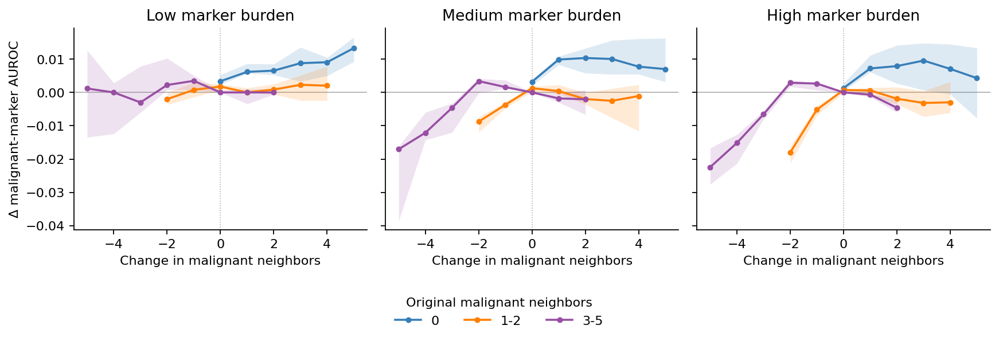

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BURDEN_QUERY_TYPES = ['']  # All types; or e.g. ["fibroblast of breast", "macrophage"].
BURDEN_MIN_QUERIES = 5  # Per slice/type/burden/original-neighbor group/x value.
BURDEN_MIN_SECTIONS = 3
burden_run = Path("/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748")
import sys
if str(burden_run) not in sys.path:
    sys.path.insert(0, str(burden_run))
from marker_auroc_responses import compute_marker_auroc_responses
compute_marker_auroc_responses(burden_run)
burden_output = burden_run / "burden_stratified_context_auroc_response"
burden_output.mkdir(exist_ok=True)
burden_data = pd.read_csv(burden_run / "marker_auroc_context_responses" / "marker_auroc_context_responses.csv.gz")
# Include the original row only when that query is a selected shared-panel donor;
# exclude the duplicated unchanged control. This retains every selected donor once.
burden_data = burden_data.loc[
    burden_data.context_selected_for_shared_panel.eq(True)
    & burden_data.context_kind.ne("unchanged_control")
    & burden_data.query_burden_quantile.isin(["low", "medium", "high"])
].copy()
if BURDEN_QUERY_TYPES is not None:
    burden_data = burden_data.loc[burden_data.query_cell_type.isin(BURDEN_QUERY_TYPES)].copy()
burden_data["delta_malignant_neighbors"] = (
    burden_data.context_malignant_token_count - burden_data.query_malignant_token_count
).astype(int)
burden_data = burden_data.loc[np.isfinite(burden_data.delta_marker_auroc)]
if burden_data.empty:
    raise ValueError("No finite responses for the selected query types and burden quantiles")
burden_keys = ["slice", "query_cell_type", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
# Repeated donors at the same malignant count receive equal weight within query.
burden_query = burden_data.groupby(burden_keys + ["query_cell_id"], observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "mean"), n_contexts=("delta_marker_auroc", "size")
).reset_index()
burden_type = burden_query.groupby(burden_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_queries=("query_cell_id", "nunique")
).reset_index()
burden_supported = burden_type.loc[burden_type.n_queries.ge(BURDEN_MIN_QUERIES)]
burden_section_keys = ["slice", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_sections = burden_supported.groupby(burden_section_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_cell_types=("query_cell_type", "nunique")
).reset_index()
burden_summary = burden_sections.groupby(burden_section_keys[1:], observed=True).agg(
    median=("delta_marker_auroc", "median"),
    q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
    q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
    n_sections=("slice", "nunique")
).reset_index()
for name, table in [("query_responses", burden_query), ("cell_type_section_responses", burden_type),
                    ("section_responses", burden_sections), ("summary", burden_summary)]:
    table.to_csv(burden_output / f"{name}.csv.gz", index=False, compression="gzip")

burden_colors = {"0": "#377eb8", "1-2": "#ff7f00", "3-5": "#984ea3"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True, dpi=180)
for ax, quantile in zip(axes, ["low", "medium", "high"]):
    for group, color in burden_colors.items():
        current = burden_summary.loc[
            burden_summary.query_burden_quantile.eq(quantile)
            & burden_summary.query_neighbor_level.eq(group)
        ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
        # Reindexing prevents lines bridging unsupported integer x values.
        current.loc[current.n_sections.fillna(0).lt(BURDEN_MIN_SECTIONS), ["median", "q25", "q75"]] = np.nan
        x = current.index.to_numpy()
        ax.plot(x, current["median"], marker="o", ms=3.5, lw=1.6, color=color, label=group)
        ax.fill_between(x, current.q25.to_numpy(float), current.q75.to_numpy(float), color=color, alpha=.16, linewidth=0)
    ax.axhline(0, color=".65", lw=.7, zorder=0)
    ax.axvline(0, color=".65", lw=.7, ls=":", zorder=0)
    ax.set_title(f"{quantile.capitalize()} marker burden")
    ax.set_xlabel("Change in malignant neighbors")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Δ malignant-marker AUROC")
fig.legend(*axes[0].get_legend_handles_labels(), title="Original malignant neighbors", loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.04))
fig.tight_layout(rect=[0, .13, 1, 1])
for suffix in ["png", "pdf"]:
    fig.savefig(burden_output / f"burden_quantile_delta_marker_auroc.{suffix}", bbox_inches="tight")
plt.show()
print("Saved:", burden_output)


## Cell-family burden-stratified marker AUROC responses

Rows group the query types into **Lymphoid** (T subtypes, NK, plasma/B), **Myeloid** (macrophage, monocyte, DC, mast), **Stromal** (fibroblast, pericyte, smooth muscle), and **Vascular** (endothelial). Mast cells are grouped with myeloid here as a broad immune grouping; the DC type available is plasmacytoid DC. There is no separate B-cell query type in this run; plasma cells represent that lineage.

Columns retain the low/medium/high burden quantiles defined **per exact cell type per slice**. The x-axis, colors, fixed expressed-gene AUROC definition, and original-relative y-axis match the adjacent plots.

Average donors at each x within each query, then take the query median per type/section/burden/original-neighbor group (require ≥5 queries). **Average these cell-type medians equally within each family and section**. Lines are the median across sections, with section IQR ribbons; require ≥3 sections. This gives types equal weight rather than pooling their cells. Available contributing types can vary across points; counts are saved in `cell_family_grid_section_responses.csv.gz`. Shared axes facilitate comparison. Edit `BURDEN_FAMILY_QUERY_TYPES` to restrict contributing types and `BURDEN_FAMILY_ORDER` to set row order.


Saved grid for 4 cell families to /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/burden_stratified_context_auroc_response


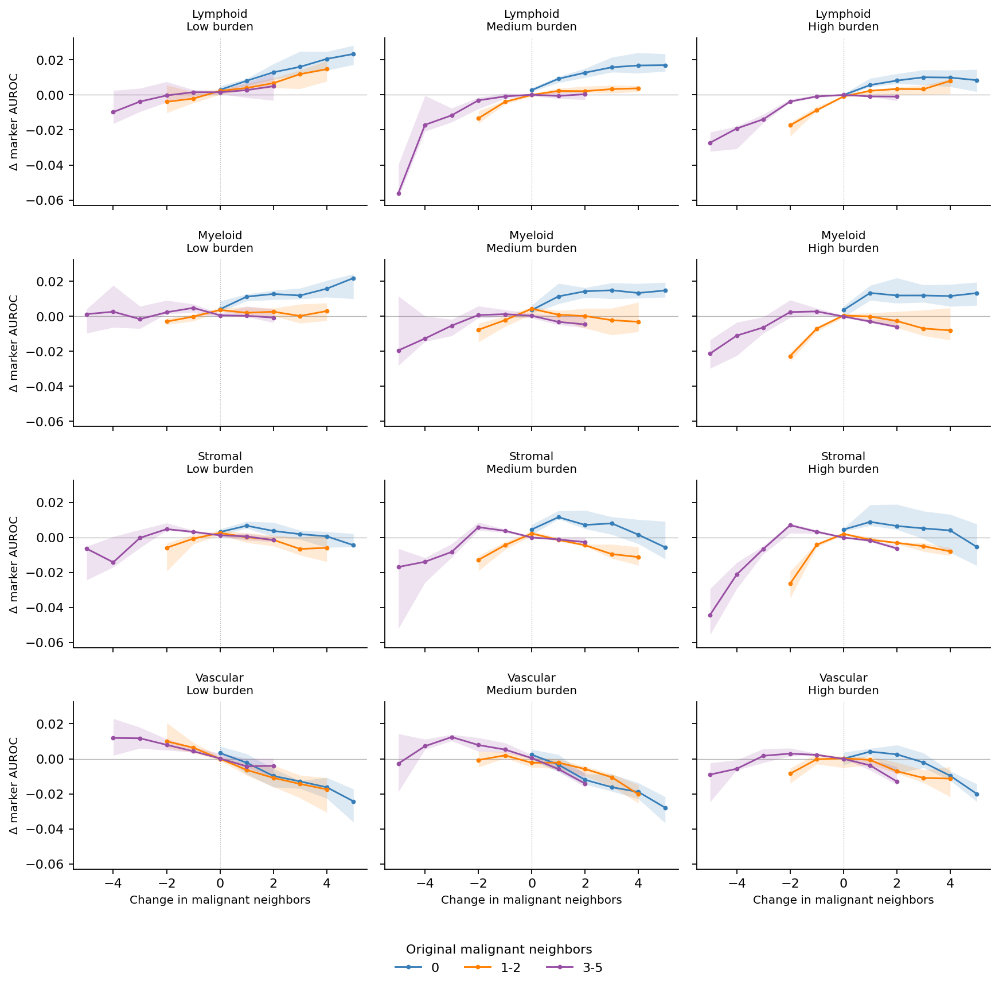

In [ ]:
# One cell family per row; equal-weight mean of supported cell-type medians per section.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BURDEN_FAMILY_QUERY_TYPES = None  # Optional subset of exact cell types contributing to families.
BURDEN_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
BURDEN_FAMILY_MAP = {'CD4-positive, alpha-beta memory T cell': 'Lymphoid', 'cytotoxic T cell': 'Lymphoid', 'natural T-regulatory cell': 'Lymphoid', 'natural killer cell': 'Lymphoid', 'plasma cell': 'Lymphoid', 'macrophage': 'Myeloid', 'classical monocyte': 'Myeloid', 'plasmacytoid dendritic cell': 'Myeloid', 'mast cell': 'Myeloid', 'fibroblast of breast': 'Stromal', 'fibroblast of lung': 'Stromal', 'pericyte': 'Stromal', 'smooth muscle cell': 'Stromal', 'capillary endothelial cell': 'Vascular'}
BURDEN_FAMILY_MIN_QUERIES = 5
BURDEN_FAMILY_MIN_SECTIONS = 3
burden_family_run = Path("/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748")
import sys
if str(burden_family_run) not in sys.path:
    sys.path.insert(0, str(burden_family_run))
from marker_auroc_responses import compute_marker_auroc_responses
compute_marker_auroc_responses(burden_family_run)
burden_family_out = burden_family_run / "burden_stratified_context_auroc_response"
# Read the full responses so this grid is independent of the pooled plot's type filter.
burden_family_rows = pd.read_csv(burden_family_run / "marker_auroc_context_responses" / "marker_auroc_context_responses.csv.gz")
burden_family_rows = burden_family_rows.loc[
    burden_family_rows.context_selected_for_shared_panel.eq(True)
    & burden_family_rows.context_kind.ne("unchanged_control")
    & burden_family_rows.query_burden_quantile.isin(["low", "medium", "high"])
    & np.isfinite(burden_family_rows.delta_marker_auroc)
].copy()
burden_family_rows["delta_malignant_neighbors"] = (
    burden_family_rows.context_malignant_token_count - burden_family_rows.query_malignant_token_count
).astype(int)
burden_family_types = sorted(burden_family_rows.query_cell_type.unique()) if BURDEN_FAMILY_QUERY_TYPES is None else list(BURDEN_FAMILY_QUERY_TYPES)
missing_types = set(burden_family_types) - set(burden_family_rows.query_cell_type)
if missing_types or not burden_family_types:
    raise ValueError(f"Empty selection or unavailable cell types: {missing_types}")
burden_family_keys = ["slice", "query_cell_type", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_family_queries = burden_family_rows.groupby(burden_family_keys + ["query_cell_id"], observed=True).delta_marker_auroc.mean().reset_index()
burden_family_sections = burden_family_queries.groupby(burden_family_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_queries=("query_cell_id", "nunique")
).reset_index()
# Keep per-type query support thresholds before averaging types within a family.
burden_family_sections["query_family"] = burden_family_sections.query_cell_type.map(BURDEN_FAMILY_MAP)
if burden_family_sections.query_family.isna().any():
    raise ValueError("Unmapped query cell types; update BURDEN_FAMILY_MAP explicitly")
if BURDEN_FAMILY_QUERY_TYPES is not None:
    burden_family_sections = burden_family_sections.loc[burden_family_sections.query_cell_type.isin(BURDEN_FAMILY_QUERY_TYPES)]
burden_family_type_sections = burden_family_sections.copy()
burden_family_sections = burden_family_sections.loc[burden_family_sections.n_queries.ge(BURDEN_FAMILY_MIN_QUERIES)].groupby(
    ["slice", "query_family", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"], observed=True
).agg(delta_marker_auroc=("delta_marker_auroc", "mean"),
      n_cell_types=("query_cell_type", "nunique"), n_queries=("n_queries", "sum")).reset_index()
burden_family_keys = ["slice", "query_family", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_family_types = [family for family in BURDEN_FAMILY_ORDER if family in set(burden_family_sections.query_family)]
burden_family_summary = burden_family_sections.loc[burden_family_sections.n_queries.ge(BURDEN_FAMILY_MIN_QUERIES)].groupby(
    burden_family_keys[1:], observed=True
).agg(median=("delta_marker_auroc", "median"),
      q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
      q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
      n_sections=("slice", "nunique")).reset_index()
burden_family_out.mkdir(exist_ok=True)
pd.DataFrame(list(BURDEN_FAMILY_MAP.items()), columns=["query_cell_type", "query_family"]).to_csv(burden_family_out / "cell_family_mapping.csv", index=False)
burden_family_type_sections.to_csv(burden_family_out / "cell_family_contributing_type_responses.csv.gz", index=False, compression="gzip")
burden_family_sections.to_csv(burden_family_out / "cell_family_grid_section_responses.csv.gz", index=False, compression="gzip")
burden_family_summary.to_csv(burden_family_out / "cell_family_grid_summary.csv", index=False)
fig, axes = plt.subplots(len(burden_family_types), 3, figsize=(11, 2.7 * len(burden_family_types)),
                         sharex=True, sharey=True, squeeze=False, dpi=150)
burden_family_colors = {"0": "#377eb8", "1-2": "#ff7f00", "3-5": "#984ea3"}
for row, query_type in enumerate(burden_family_types):
    for col, quantile in enumerate(["low", "medium", "high"]):
        ax = axes[row, col]
        for group, color in burden_family_colors.items():
            current = burden_family_summary.loc[
                burden_family_summary.query_family.eq(query_type)
                & burden_family_summary.query_burden_quantile.eq(quantile)
                & burden_family_summary.query_neighbor_level.eq(group)
            ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
            current.loc[current.n_sections.fillna(0).lt(BURDEN_FAMILY_MIN_SECTIONS), ["median", "q25", "q75"]] = np.nan
            ax.plot(current.index, current["median"], color=color, marker="o", ms=2.5, lw=1.3, label=group)
            ax.fill_between(current.index.to_numpy(), current.q25.to_numpy(float), current.q75.to_numpy(float), color=color, alpha=.16, linewidth=0)
        ax.axhline(0, color=".7", lw=.6, zorder=0)
        ax.axvline(0, color=".7", lw=.6, ls=":", zorder=0)
        ax.set_title(f"{query_type}\n{quantile.capitalize()} burden", fontsize=9)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.spines[["top", "right"]].set_visible(False)
        if col == 0:
            ax.set_ylabel("Δ marker AUROC", fontsize=9)
        if row == len(burden_family_types) - 1:
            ax.set_xlabel("Change in malignant neighbors", fontsize=9)
fig.legend(*axes[0, 0].get_legend_handles_labels(), title="Original malignant neighbors", loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, 0))
fig.tight_layout(rect=[0, .065, 1, 1], h_pad=1.5)
for suffix in ["png", "pdf"]:
    fig.savefig(burden_family_out / f"cell_family_burden_quantile_delta_marker_auroc.{suffix}", bbox_inches="tight")
plt.show()
print(f"Saved grid for {len(burden_family_types)} cell families to {burden_family_out}")


## Alternative: equal-original-stratum superclass AUROC curves

Three burden panels overlay Lymphoid, Myeloid, Stromal, and Vascular. X is donor minus original malignant count among the five encoded neighbors; Y is Δ marker AUROC relative to the query’s original context. The 32-gene panel and fixed raw-expressed gene eligibility match the preceding AUROC plots.

For every section × superclass × burden × x, first retain the separate original-context strata (0, 1–2, 3–5). Each stratum response is the preceding grid's equal-weight average of supported exact-cell-type query medians. Require ≥3 sections for each stratum/x combination, as in that grid. **Within each section**, take the arithmetic mean of the available stratum responses, giving each stratum one equal vote, independently of its cell or donor count. Only contributing strata enter the denominator; do not extrapolate or pad impossible values.

**Lines show the median of those section-level equal-stratum averages; ribbons show their 25th–75th percentiles (section IQR, not confidence intervals).** Require ≥3 sections per displayed point. This updates the earlier center (mean of stratum section-medians) to the median of section-wise stratum means so line and ribbon summarize the same distribution.

The contributing stratum mix can change across x and sections. `combined_family_auroc_section_curves.csv` records each section's response, contributor count and identities; `combined_family_auroc_curves.csv` stores line/ribbon values and section support. `combined_family_auroc_stratum_support.csv` retains the separate stratum support gate. A zero Δ malignant count can still change other token identities/order, so ΔAUROC need not be zero there.

Colors match the Xenium UMAP family palettes: lymphoid blue, myeloid/innate red, stromal green, and vascular light green (the capillary-endothelial shade).


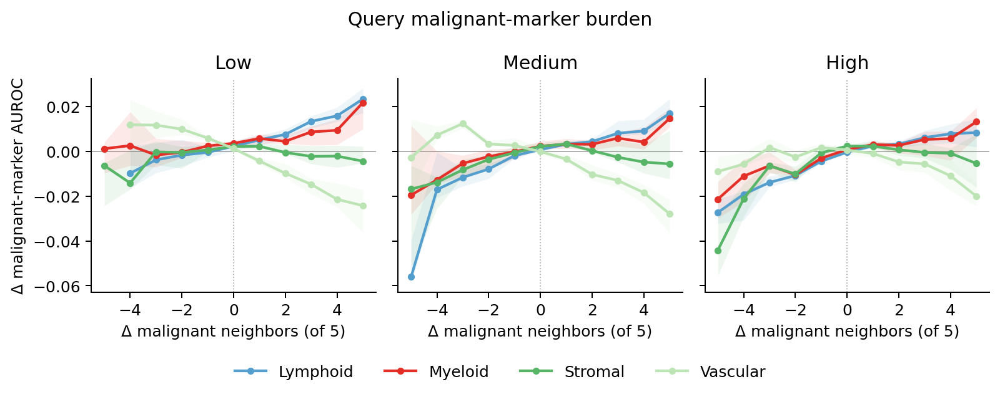

Saved equal-stratum superclass curves and contributing-strata tables: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/burden_stratified_context_auroc_response


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

COMBINED_AUROC_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748")
COMBINED_AUROC_MIN_SECTIONS = 3
COMBINED_AUROC_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
# Exact representative shades from Figure2_UMAPs_Xenium.ipynb: lymphoid blue,
# myeloid/innate red, stromal/vascular greens (vascular uses capillary endothelial).
COMBINED_AUROC_COLORS = {'Lymphoid': '#539ecd', 'Myeloid': '#e32f27', 'Stromal': '#56b567', 'Vascular': '#bce4b5'}
combined_auroc_out = COMBINED_AUROC_RUN / "burden_stratified_context_auroc_response"
combined_source = combined_auroc_out / "cell_family_grid_section_responses.csv.gz"
if not combined_source.exists():
    raise FileNotFoundError("Run the preceding cell-family AUROC grid first: " + str(combined_source))
combined_family_sections = pd.read_csv(combined_source, dtype={"query_neighbor_level": str})
combined_stratum_keys = ["query_family", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
# Preserve the separate original-context curves: each is the section median
# of equal-weight type summaries, as in the preceding superclass grid.
combined_stratum_curves = combined_family_sections.groupby(combined_stratum_keys, observed=True).agg(
    stratum_delta_auroc=("delta_marker_auroc", "median"), n_sections=("slice", "nunique")
).reset_index()
combined_stratum_curves["contributes"] = (
    combined_stratum_curves.n_sections.ge(COMBINED_AUROC_MIN_SECTIONS)
    & np.isfinite(combined_stratum_curves.stratum_delta_auroc)
)
combined_supported = combined_stratum_curves.loc[combined_stratum_curves.contributes].copy()
combined_keys = ["query_family", "query_burden_quantile", "delta_malignant_neighbors"]
# Average original-context strata equally within each section at each x.
# Retain the same >=3-section support gate for each stratum/x combination.
combined_supported_sections = combined_family_sections.merge(
    combined_supported[combined_stratum_keys], on=combined_stratum_keys,
    how="inner", validate="many_to_one")
combined_section_curves = combined_supported_sections.groupby(["slice"] + combined_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "mean"),
    n_original_context_strata=("query_neighbor_level", "nunique"),
    contributing_strata=("query_neighbor_level", lambda s: ", ".join(v for v in ["0", "1-2", "3-5"] if v in set(s)))
).reset_index()
combined_auroc_curves = combined_section_curves.groupby(combined_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"),
    q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
    q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
    n_sections=("slice", "nunique"),
    min_original_context_strata=("n_original_context_strata", "min"),
    max_original_context_strata=("n_original_context_strata", "max")
).reset_index()
assert combined_section_curves.n_original_context_strata.between(1, 3).all()
combined_stratum_curves.to_csv(combined_auroc_out / "combined_family_auroc_stratum_support.csv", index=False)
combined_section_curves.to_csv(combined_auroc_out / "combined_family_auroc_section_curves.csv", index=False)
combined_auroc_curves.to_csv(combined_auroc_out / "combined_family_auroc_curves.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.5), sharex=True, sharey=True, dpi=180)
for ax, burden in zip(axes, ["low", "medium", "high"]):
    for family in COMBINED_AUROC_FAMILY_ORDER:
        current = combined_auroc_curves.loc[
            combined_auroc_curves.query_family.eq(family)
            & combined_auroc_curves.query_burden_quantile.eq(burden)
        ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
        current.loc[current.n_sections.fillna(0).lt(COMBINED_AUROC_MIN_SECTIONS), ["delta_marker_auroc", "q25", "q75"]] = np.nan
        ax.fill_between(current.index.to_numpy(), current.q25.to_numpy(float), current.q75.to_numpy(float),
                        color=COMBINED_AUROC_COLORS[family], alpha=.10, linewidth=0)
        ax.plot(current.index, current.delta_marker_auroc, marker="o", ms=3.5,
                lw=1.7, color=COMBINED_AUROC_COLORS[family], label=family)
    ax.axhline(0, color=".65", lw=.7, zorder=0)
    ax.axvline(0, color=".65", lw=.7, ls=":", zorder=0)
    ax.set_title(f"{burden.capitalize()}")
    ax.set_xlabel("Δ malignant neighbors (of 5)")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Δ malignant-marker AUROC")
fig.suptitle("Query malignant-marker burden")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4,
           frameon=False, bbox_to_anchor=(.5, .005))
fig.tight_layout(rect=[0, .10, 1, 1])
for suffix in ["png", "pdf"]:
    fig.savefig(combined_auroc_out / f"combined_superclass_burden_delta_auroc.{suffix}", bbox_inches="tight")
plt.show()
print("Saved equal-stratum superclass curves and contributing-strata tables:", combined_auroc_out)


## Nine-stratum marker-versus-nonpanel response by query superclass

For each expressed gene in the 32-gene panel, calculate the strict fraction W of expressed **nonpanel** genes it outranks, using each query’s fixed raw-expressed comparison set. Ties count as zero wins. ΔW is the swapped minus original value; Δn is donor minus original malignant-token count among the five encoded neighbors.

**Calculate correlations independently in all nine query strata:** burden low/medium/high × original malignant-neighbor group 0/1–2/3–5. Burden strata retain their per-exact-cell-type/per-slice definitions. Within each section × superclass × burden × original-context stratum, compute Spearman(Δn, ΔW) across shared donor-panel query/context pairs. Require ≥10 distinct queries expressing the gene, ≥3 distinct Δn values, and nonconstant ΔW. Pool cell types' pairs only within the same superclass and query stratum.

The main color is **median across supported section × burden × original-context correlations**, assigning each such unit one equal weight, exactly `median_(s,b,o)(rho_gscbo)`. Do not pool the nine strata’s pairs before calculating correlations. Require ≥3 supported sections to display a gene/superclass. Unsupported units remain missing rather than receiving invented correlations or replacement samples; therefore coverage can vary among the nine strata. Section/stratum CSVs explicitly retain all 72 possible units per gene/superclass, their query/pair support, and exclusion reasons. The accompanying coverage heatmap shows the number of valid units out of 72.

Text in the response heatmap is sections whose **within-section median across supported strata** agrees with the main median sign / supported sections. It measures descriptive sign consistency, not significance. Multiple swaps per query are dependent. All rows share a −1 to +1 color scale. Gray means insufficient support.

Rows use average-linkage hierarchical clustering of the four signed superclass response profiles, with optimal leaf ordering. Missing entries use a gene’s mean solely for clustering, remaining gray in the plotted matrix. Set `GENE_WIN_CLUSTER_ROWS=False` for the original panel order. Nonpanel genes are operational comparison controls, not independently validated nonmalignant markers.

The response and coverage heatmaps use landscape orientation: clustered genes along x and query superclasses along y. Numerical tables retain their existing gene-by-superclass layout.


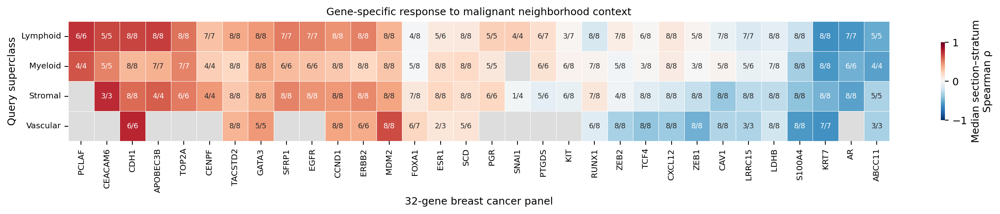

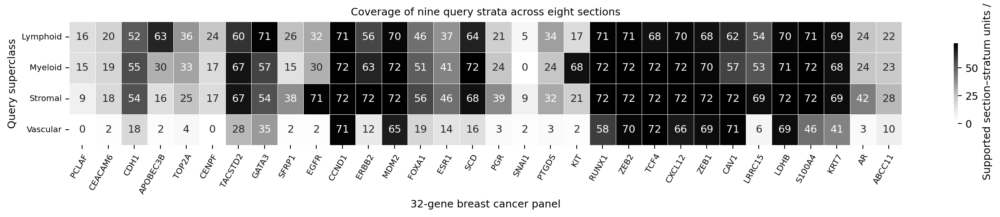

Saved heatmaps and section-level support tables: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/gene_nonpanel_win_stratified_context_correlations


In [15]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

GENE_WIN_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748")
if str(GENE_WIN_RUN) not in sys.path:
    sys.path.insert(0, str(GENE_WIN_RUN))
from gene_stratified_nonpanel_win_correlations import compute_stratified_gene_win_correlations
GENE_WIN_MIN_QUERIES = 10
GENE_WIN_MIN_SECTIONS = 3
GENE_WIN_MIN_DELTA_LEVELS = 3
GENE_WIN_CLUSTER_ROWS = True  # Group similar signed superclass response profiles.
GENE_WIN_ANNOTATE = True  # k/n sections agreeing with the median sign, not significance.
GENE_WIN_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
GENE_WIN_TYPE_ORDER = None  # Optional ordered subset of exact cell-type names.
gene_win_out = compute_stratified_gene_win_correlations(
    GENE_WIN_RUN, min_queries=GENE_WIN_MIN_QUERIES, min_delta_levels=GENE_WIN_MIN_DELTA_LEVELS)
gene_win_summary = pd.read_csv(gene_win_out / "gene_win_correlation_summary.csv")
gene_win_markers = json.loads((GENE_WIN_RUN / "design.json").read_text())["marker_genes"]
for kind, title in [("family", "Query superclass")]:
    current = gene_win_summary.loc[gene_win_summary.group_kind.eq(kind)]
    columns = GENE_WIN_FAMILY_ORDER if kind == "family" else (
        sorted(current.query_group.unique()) if GENE_WIN_TYPE_ORDER is None else GENE_WIN_TYPE_ORDER)
    values = current.pivot(index="gene", columns="query_group", values="median_rho").reindex(index=gene_win_markers, columns=columns)
    support = current.pivot(index="gene", columns="query_group", values="n_sections").reindex_like(values)
    agreement = current.pivot(index="gene", columns="query_group", values="n_same_sign").reindex_like(values)
    values = values.mask(support.lt(GENE_WIN_MIN_SECTIONS))
    if GENE_WIN_CLUSTER_ROWS:
        from scipy.cluster.hierarchy import linkage, leaves_list
        supported_genes = values.index[values.notna().any(axis=1)].tolist()
        missing_genes = values.index[values.isna().all(axis=1)].tolist()
        cluster_values = values.loc[supported_genes].copy()
        # Impute missing entries with that gene's mean only for clustering;
        # the displayed heatmap and saved response matrix retain missing values.
        cluster_values = cluster_values.T.fillna(cluster_values.mean(axis=1)).T
        if len(supported_genes) > 1:
            tree = linkage(cluster_values.to_numpy(), method="average", metric="euclidean", optimal_ordering=True)
            ordered_genes = cluster_values.index[leaves_list(tree)].tolist()
            # Flip the complete dendrogram orientation to place the more positive end first.
            if values.loc[ordered_genes[0]].mean() < values.loc[ordered_genes[-1]].mean():
                ordered_genes.reverse()
        else:
            ordered_genes = supported_genes
        ordered_genes += missing_genes
        values = values.reindex(ordered_genes)
        support = support.reindex(ordered_genes)
        agreement = agreement.reindex(ordered_genes)
    pd.DataFrame({"gene": values.index, "row": np.arange(1, len(values) + 1)}).to_csv(
        gene_win_out / f"gene_nonpanel_win_delta_context_{kind}_row_order.csv", index=False)
    labels = pd.DataFrame("", index=values.index, columns=values.columns)
    for gene in values.index:
        for group in values.columns:
            if np.isfinite(values.loc[gene, group]):
                labels.loc[gene, group] = f"{int(agreement.loc[gene, group])}/{int(support.loc[gene, group])}"
    fig, ax = plt.subplots(figsize=(15, 3.0), dpi=180)
    ax.set_facecolor("#dddddd")
    sns.heatmap(values.T, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=labels.T if GENE_WIN_ANNOTATE else False, fmt="", annot_kws={"fontsize":7},
                linewidths=.35, linecolor="white",
                cbar_kws={"label":"Median section–stratum\nSpearman ρ", "shrink":.65})
    ax.set_title("Gene-specific response to malignant neighborhood context", fontsize=10)
    ax.set_xlabel("32-gene breast cancer panel")
    ax.set_ylabel(title)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_rotation_mode("anchor")
        label.set_ha("right")
        label.set_va("center")
    fig.tight_layout()
    for suffix in ["png", "pdf"]:
        fig.savefig(gene_win_out / f"gene_nonpanel_win_delta_context_{kind}_heatmap.{suffix}", bbox_inches="tight")
    values.to_csv(gene_win_out / f"gene_nonpanel_win_delta_context_{kind}_heatmap.csv")
    plt.show()
coverage = current.pivot(index="gene", columns="query_group", values="n_section_stratum_units").reindex(index=values.index, columns=values.columns)
fig, ax = plt.subplots(figsize=(15, 3.), dpi=180)
sns.heatmap(coverage.T, cmap="Greys", vmin=0, vmax=72, annot=True, fmt=".0f", linewidths=.35,
            cbar_kws={"label":"Supported section–stratum units / 72", "shrink":.65}, ax=ax)
ax.set_title("Coverage of nine query strata across eight sections", fontsize=10)
ax.set_xlabel("32-gene breast cancer panel")
ax.set_ylabel("Query superclass")
ax.tick_params(axis="y", labelrotation=0, labelsize=8)
ax.tick_params(axis="x", labelrotation=60, labelsize=8)
for label in ax.get_xticklabels():
    label.set_rotation_mode("anchor")
    label.set_ha("right")
fig.tight_layout()
for suffix in ["png", "pdf"]:
    fig.savefig(gene_win_out / f"gene_nonpanel_win_stratified_coverage.{suffix}", bbox_inches="tight")
plt.show()
print("Saved heatmaps and section-level support tables:", gene_win_out)


## Controlled versus native AUROC slopes: estimate within exact query type first

Each faint point is a **section × superclass × burden** summary; large points are coordinate-wise section medians with horizontal/vertical section IQR bars. Colors match Xenium UMAP families, and dashed lines indicate equal slopes. Units are AUROC change per additional malignant neighbor among the five encoded neighbors.

**First estimate within section × exact query cell type × burden quantile:**

- Native β: weighted OLS with an intercept, `original marker AUROC ~ original malignant-neighbor count`, across original-context predictions of eligible sampled queries of that exact type. Require ≥10 queries and ≥3 distinct native count levels.
- Controlled β: weighted mean of those **same queries’** within-query context-swap slopes, each previously fit with an intercept as `ΔAUROC ~ Δmalignant count` (≥3 donor count levels). Each selected donor contributes once; unchanged duplicate controls are excluded.
- Balance the original-context groups (0, 1–2, 3–5) within the exact-type fit: each available group has equal total weight, and queries within a group have equal weights. Require ≥5 queries per contributing group. No oversampling or replacement. Burden quantiles retain their per-type/per-slice definition.

**Then aggregate:** within each section × superclass × burden, take the arithmetic mean of the exact-type slopes, giving each eligible type equal weight. Use only types with both coefficients valid, for both axes. Finally show section medians and IQRs. Thus the native slope no longer mixes differences between exact cell types into a superclass-level regression. This changes the controlled-axis aggregation too, to keep type weights and query cohorts matched.

This conditions on annotated cell type, section, and burden tertile; it does not control every aspect of query state, continuous expression, or other context features. Native β remains an observational association, while controlled β holds query expression fixed across remappings. Their agreement is descriptive rather than a causal or contamination-accuracy test.

`cell_type_control_native_slopes.csv` retains the individual fits/support; `section_control_native_slopes.csv` lists contributing types and their equal-weight averages; `query_weights_and_support.csv.gz` records the query weights. These adjusted results are saved in `auroc_control_native_within_type/`; the previous superclass-fit results remain in `auroc_control_native/`.


Slopes are AUROC change per additional malignant neighbor. Saved: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/auroc_control_native_within_type


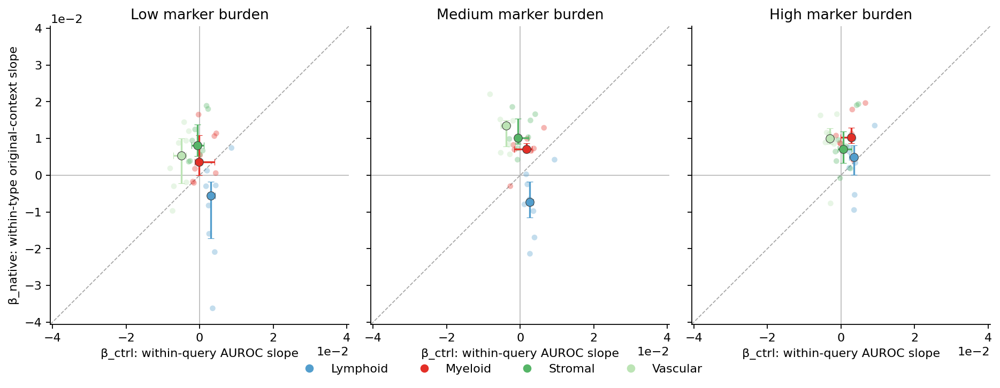

,query_family,query_burden_quantile,beta_ctrl,beta_native,n_sections
0,Lymphoid,high,0.003509,0.004886,8
1,Lymphoid,low,0.003068,-0.005623,8
2,Lymphoid,medium,0.002573,-0.007250,8
3,Myeloid,high,0.002855,0.010259,8
4,Myeloid,low,-0.000085,0.003605,8
5,Myeloid,medium,0.001694,0.007115,8
6,Stromal,high,0.000593,0.007144,8
7,Stromal,low,-0.000590,0.008071,8
8,Stromal,medium,-0.000675,0.010120,8
9,Vascular,high,-0.002990,0.010051,8


In [ ]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

CONTROL_NATIVE_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748")
CONTROL_NATIVE_MIN_SECTIONS = 3
CONTROL_NATIVE_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
if str(CONTROL_NATIVE_RUN) not in sys.path:
    sys.path.insert(0, str(CONTROL_NATIVE_RUN))
from auroc_control_native_within_type import compute_control_native_within_type
control_native_out = compute_control_native_within_type(CONTROL_NATIVE_RUN)
control_native_sections = pd.read_csv(control_native_out / "section_control_native_slopes.csv")
control_native_summary = pd.read_csv(control_native_out / "control_native_summary.csv")
control_native_colors = json.loads((CONTROL_NATIVE_RUN / "burden_stratified_context_auroc_response" / "combined_family_colors.json").read_text())["colors"]
control_native_valid = control_native_sections.loc[
    control_native_sections.status.eq("valid")
    & np.isfinite(control_native_sections.beta_ctrl)
    & np.isfinite(control_native_sections.beta_native)]
control_native_xy = control_native_valid[["beta_ctrl", "beta_native"]].to_numpy()
if not control_native_xy.size:
    raise ValueError("No paired controlled/native slopes with adequate support")
control_native_lim = max(np.abs(control_native_xy).max() * 1.12, .005)
fig, axes = plt.subplots(1, 3, figsize=(11.8, 4.4), sharex=True, sharey=True, dpi=180)
for ax, burden in zip(axes, ["low", "medium", "high"]):
    ax.axhline(0, color=".7", lw=.7, zorder=0)
    ax.axvline(0, color=".7", lw=.7, zorder=0)
    ax.plot([-control_native_lim, control_native_lim], [-control_native_lim, control_native_lim],
            color=".65", ls="--", lw=.8, zorder=0)
    for family in CONTROL_NATIVE_FAMILY_ORDER:
        color = control_native_colors[family]
        points = control_native_valid.loc[control_native_valid.query_family.eq(family)
            & control_native_valid.query_burden_quantile.eq(burden)]
        ax.scatter(points.beta_ctrl, points.beta_native, color=color, s=23, alpha=.35,
                   edgecolor="none", zorder=2)
        rows = control_native_summary.loc[control_native_summary.query_family.eq(family)
            & control_native_summary.query_burden_quantile.eq(burden)
            & control_native_summary.n_sections.ge(CONTROL_NATIVE_MIN_SECTIONS)]
        for row in rows.itertuples():
            ax.errorbar(row.beta_ctrl, row.beta_native,
                xerr=[[row.beta_ctrl - row.beta_ctrl_q25], [row.beta_ctrl_q75 - row.beta_ctrl]],
                yerr=[[row.beta_native - row.beta_native_q25], [row.beta_native_q75 - row.beta_native]],
                fmt="o", ms=7, color=color, markeredgecolor=".25", markeredgewidth=.5,
                elinewidth=1.5, capsize=2.5, zorder=3)
    ax.set_title(f"{burden.capitalize()} marker burden")
    ax.set_xlabel("β_ctrl: within-query AUROC slope")
    ax.set_xlim(-control_native_lim, control_native_lim)
    ax.set_ylim(-control_native_lim, control_native_lim)
    ax.set_aspect("equal", adjustable="box")
    ax.spines[["top", "right"]].set_visible(False)
    ax.ticklabel_format(style="sci", axis="both", scilimits=(-2, 2))
axes[0].set_ylabel("β_native: within-type original-context slope")
handles = [Line2D([0], [0], marker="o", linestyle="", color=control_native_colors[f], label=f) for f in CONTROL_NATIVE_FAMILY_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(.5, .01))
fig.tight_layout(rect=[0, .12, 1, 1])
for suffix in ["png", "pdf"]:
    fig.savefig(control_native_out / f"beta_controlled_vs_native.{suffix}", bbox_inches="tight")
plt.show()
display(control_native_summary[["query_family", "query_burden_quantile", "beta_ctrl", "beta_native", "n_sections"]])
print("Slopes are AUROC change per additional malignant neighbor. Saved:", control_native_out)
